# Air-writing: train and test 5 adapted architectures on your 2-IMU ZIP recordings

**What this notebook actually does:** aligns WT901 and Apple Watch wrist-motion data, trains CNN–BiLSTM, IMU2Text-inspired, SCLAiR-inspired, REWI-inspired CTC, and ECHWR-inspired CTC models on your recordings. Holds out one of the three sentence sessions at a time, then tests isolated letters and exploratory complete-sentence recordings. Each of the five variants is an independently implemented *adaptation*; it is **not** a copy of a published repository with pretrained weights.

**Limits:** all recordings are uppercase. Only three real complete sentences exist, and one has no usable Apple Watch stream. REWI/ECHWR learn CTC from synthetic concatenated letters, which does not automatically transfer to continuous sentence handwriting. The second sentence filename spells **LIQOUR**. We do **not** pretend a lowercase score exists.

In [2]:
!pip -q install "numpy>=1.24,<3" "pandas>=2.0,<3" "torch>=2.1,<3"

## 1. Upload all SIX original ZIPs
Choose `A(4).zip`, `B(2).zip`, `C(3).zip`, `FIRST SENTENCE(5).zip`, `SECOND SENTENCE(5).zip`, `THIRD SENTENCE(5).zip`. Upload files as-is; **do not unpack them**. Exact names in this package are preconfigured.

In [3]:
from google.colab import files
uploaded = files.upload()
print("Uploaded:", list(uploaded))

Saving A.zip to A.zip
Saving B.zip to B.zip
Saving C.zip to C.zip
Saving FIRST SENTENCE.zip to FIRST SENTENCE.zip
Saving SECOND SENTENCE.zip to SECOND SENTENCE.zip
Saving THIRD SENTENCE.zip to THIRD SENTENCE.zip
Uploaded: ['A.zip', 'B.zip', 'C.zip', 'FIRST SENTENCE.zip', 'SECOND SENTENCE.zip', 'THIRD SENTENCE.zip']


## 2. Write the complete model/data pipeline

In [4]:
%%writefile /content/benchmark.py
#!/usr/bin/env python3
"""
Two-IMU uppercase air-writing benchmark.

Five locally adaptable architectures (NOT official released model reproductions):
  cnn_bilstm: temporal CNN + BiLSTM letter classifier
  imu2text: CNN + BiLSTM + attention letter classifier (IMU2Text-inspired)
  sclair: supervised-contrastive CNN + BiLSTM letter classifier (SCLAiR-inspired)
  rewi: temporal CNN + BiLSTM + CTC sequence model (REWI-inspired)
  echwr: REWI-like CTC plus training-only positive/typo text contrastive branch
         (ECHWR-inspired approximation, not paper's original text encoder)

Train isolated letters from other sessions; test held-out sentence session's
isolated letters. For CTC models, train on isolated letters AND artificial
concatenations of training clips; test real WHOLE recordings. Since artificial
concatenation is not natural continuous handwriting, sentence CER is exploratory.
No lowercase files are present. No writer-independent claims are supported.
"""
from __future__ import annotations
import argparse
import csv
import io
import json
import logging
import os
import random
import re
import sys
import zipfile
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

MODELS = ('cnn_bilstm','imu2text','sclair','rewi','echwr')
SESSIONS = ('FIRST SENTENCE','SECOND SENTENCE','THIRD SENTENCE')
ABC = ('A','B','C')
ALPHABET = 'ABCDEFGHIJKLMNOPQRSTUVWXYZ'
WT_COLS = ['AccX(g)','AccY(g)','AccZ(g)','AsX(°/s)','AsY(°/s)','AsZ(°/s)']
WATCH_COLS = ['accelerationX','accelerationY','accelerationZ','rotationRateX','rotationRateY','rotationRateZ']
ZIP_MAP = {
    'A':'A(4).zip','B':'B(2).zip','C':'C(3).zip',
    'FIRST SENTENCE':'FIRST SENTENCE(5).zip',
    'SECOND SENTENCE':'SECOND SENTENCE(5).zip',
    'THIRD SENTENCE':'THIRD SENTENCE(5).zip',
}


def seed_all(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)


def normalize_text(s):
    return ''.join(c for c in s.upper() if 'A'<=c<='Z')


def linear_resample(a, count):
    if len(a)<2: raise ValueError('not enough samples')
    xo=np.linspace(0,1,len(a),dtype=np.float64)
    xn=np.linspace(0,1,int(count),dtype=np.float64)
    return np.stack([np.interp(xn,xo,a[:,j]) for j in range(a.shape[1])],axis=-1).astype('float32')


def load_watch(outer, folder, nested_name):
    """Prefer nested watch export, falling back to extracted A1 archive."""
    nested=None
    if nested_name:
        with zipfile.ZipFile(io.BytesIO(outer.read(nested_name))) as inn:
            if 'WristMotion.csv' not in inn.namelist():
                return None
            return pd.read_csv(io.BytesIO(inn.read('WristMotion.csv')))
    # A/A1 has extracted Watch csv, not nested archive
    choices=[n for n in outer.namelist() if n.startswith(folder+'/') and n.endswith('/WristMotion.csv')]
    if len(choices)!=1: return None
    return pd.read_csv(io.BytesIO(outer.read(choices[0])))


def parse_record(outer, txt_name, nested_name, sample_rate=50, max_seconds=200):
    folder=str(Path(txt_name).parent).replace('\\','/')
    wt=pd.read_csv(io.BytesIO(outer.read(txt_name)), sep='\t', low_memory=False)
    watch=load_watch(outer,folder,nested_name)
    for field in WT_COLS:
        if field not in wt: raise ValueError('WT missing '+field)
    if watch is not None:
        for field in WATCH_COLS:
            if field not in watch: watch=None;break
    wt_values=wt[WT_COLS].apply(pd.to_numeric,errors='coerce').to_numpy(dtype=np.float64)
    watch_values=(watch[WATCH_COLS].apply(pd.to_numeric,errors='coerce').to_numpy(dtype=np.float64) if watch is not None else None)
    # Units: WT gyro degrees/s, watch gyro radians/s. Both accel in g.
    wt_values[:,3:6] *= np.pi/180.
    # Each recording may have many identical WT timestamp fields: recreate
    # near-uniform sampling between their first and last timestamps (approximate).
    time=pd.to_datetime(wt['time'],errors='coerce')
    valid=~pd.isna(time)
    wt_values=wt_values[valid]
    time=time[valid]
    if len(time)<10: raise ValueError('WT too short')
    # Wall clock of WT in Asia/Beirut. Apple Watch ns are UTC Unix timestamps.
    times=time.dt.tz_localize('Asia/Beirut',ambiguous='NaT',nonexistent='shift_forward')
    numeric=(times.astype('int64').to_numpy()/1e9).astype(np.float64)
    numeric=numeric[np.isfinite(numeric)]; wt_values=wt_values[:len(numeric)]
    if len(numeric)<10 or numeric[-1]<=numeric[0]: raise ValueError('invalid WT time')
    wt_secs=np.linspace(numeric[0],numeric[-1],len(numeric))
    status='two_IMU'
    if watch is not None:
        watch_secs=pd.to_numeric(watch['time'],errors='coerce').to_numpy(dtype=np.float64)/1e9
        finite=np.isfinite(watch_secs)&np.isfinite(watch_values).all(1)
        watch_secs=watch_secs[finite];watch_values=watch_values[finite]
        order=np.argsort(watch_secs);watch_secs=watch_secs[order];watch_values=watch_values[order]
        unique=np.r_[True,np.diff(watch_secs)>1e-7] if len(watch_secs) else []
        watch_secs=watch_secs[unique];watch_values=watch_values[unique]
    else: watch_secs=np.array([])
    finite_wt=np.isfinite(wt_values).all(1)
    wt_secs=wt_secs[finite_wt];wt_values=wt_values[finite_wt]
    if len(wt_secs)<10: raise ValueError('not enough WT sensor samples')
    if len(watch_secs)<10:
        status='WT_only_missing_watch'
    elif min(wt_secs[-1],watch_secs[-1])-max(wt_secs[0],watch_secs[0])<1.0:
        status='WT_only_nonoverlap_watch'
    if status=='two_IMU':
        begin=max(wt_secs[0],watch_secs[0]);end=min(wt_secs[-1],watch_secs[-1])
    else:
        # Do not align mismatched watch streams: zero-fill exactly these channels.
        begin=wt_secs[0];end=wt_secs[-1]
    end=min(end,begin+max_seconds)
    if end-begin<0.2: raise ValueError('recording too short')
    n=max(8,int((end-begin)*sample_rate))
    t=np.linspace(begin,end,n)
    left=np.column_stack([np.interp(t,wt_secs,wt_values[:,j]) for j in range(6)])
    right=(np.column_stack([np.interp(t,watch_secs,watch_values[:,j]) for j in range(6)])
           if status=='two_IMU' else np.zeros((n,6),dtype=np.float64))
    x=np.concatenate([left,right],axis=-1).astype('float32')
    # Remove per-trial static sensor offsets (especially orientation/gravity).
    # Works consistently for training/testing; no labels are used.
    x -= np.median(x,axis=0,keepdims=True)
    x=np.clip(x,-8,8)
    return x,status


def extract_all(root: Path, rate=50, max_seconds=200, cache:Path|None=None):
    if cache and cache.exists():
        logging.info('Loading cached preprocessing: %s',cache)
        with np.load(cache,allow_pickle=True) as d:
            return d['records'].tolist()
    rec=[];errors=[]
    for source, filename in ZIP_MAP.items():
        path=root/filename
        if not path.exists(): raise FileNotFoundError(f'Missing {path}; upload the six ZIPs')
        with zipfile.ZipFile(path) as z:
            txts=sorted(n for n in z.namelist() if n.lower().endswith('.txt') and not n.startswith('__MACOSX/'))
            for txt in txts:
                folder=str(Path(txt).parent).replace('\\','/')
                nested=[n for n in z.namelist() if n.startswith(folder+'/') and n.endswith('.zip') and not n.startswith('__MACOSX/')]
                name=Path(txt).stem
                whole=Path(txt).parent.name.upper()=='WHOLE'
                label=normalize_text(name if whole else name.rstrip('0123456789'))
                if not label: errors.append((txt,'no label'));continue
                if not whole and len(label)!=1: errors.append((txt,'not a single-letter label'));continue
                try:
                    x,status=parse_record(z,txt,nested[0] if nested else None,rate,max_seconds)
                    rec.append(dict(source=source,file=txt,label=label,whole=whole,x=x,sensor_status=status))
                except Exception as e:
                    errors.append((txt,str(e)))
    print('Preprocessed:',len(rec),'recordings', 'by source',dict(Counter(r['source'] for r in rec)))
    print('Sensor quality:',dict(Counter(r['sensor_status'] for r in rec)))
    for r in rec:
        if r['sensor_status']!='two_IMU':print(' WARNING: single usable IMU:',r['file'],r['sensor_status'])
    if errors:
        print('Skipped',len(errors),'recordings (inspect below):')
        for e in errors[:40]:print(' ',e)
    if cache:
        cache.parent.mkdir(parents=True,exist_ok=True)
        np.savez_compressed(cache, records=np.array(rec,dtype=object))
    return rec


def split_data(records, heldout):
    train=[r for r in records if r['source']!=heldout and not r['whole']]
    test=[r for r in records if r['source']==heldout and not r['whole']]
    whole=[r for r in records if r['source']==heldout and r['whole']]
    count=Counter(r['label'] for r in train)
    missing=sorted(set(ALPHABET)-set(count))
    if missing: raise ValueError('training letters missing '+''.join(missing))
    return train,test,whole


def stats_from_train(train):
    # Per-channel standard deviation from training data only.
    x=np.concatenate([r['x'] for r in train],axis=0)
    scale=np.std(x,axis=0).astype('float32')
    return np.maximum(scale,0.05)


def augment(x, std=0.035):
    # mild view augmentations; not applied during evaluation
    scale=np.random.uniform(0.9,1.1,size=(1,x.shape[1]))
    noise=np.random.randn(*x.shape)*std
    return (x*scale+noise).astype('float32')


class LetterDataset(Dataset):
    def __init__(self, records, scale, length=160, train=False):
        self.records=records;self.scale=scale;self.length=length;self.train=train
    def __len__(self):return len(self.records)
    def __getitem__(self,i):
        r=self.records[i]; x=linear_resample(r['x']/self.scale,self.length)
        if self.train:x=augment(x)
        return torch.from_numpy(x), torch.tensor(ALPHABET.index(r['label']),dtype=torch.long)


class ConvEncoder(nn.Module):
    def __init__(self,d=64):
        super().__init__()
        self.net=nn.Sequential(
            nn.Conv1d(12,d,5,padding=2,stride=2),nn.BatchNorm1d(d),nn.ReLU(),
            nn.Conv1d(d,d,5,padding=2,stride=2),nn.BatchNorm1d(d),nn.ReLU(),
            nn.Conv1d(d,d,3,padding=1),nn.BatchNorm1d(d),nn.ReLU())
        self.rnn=nn.LSTM(d,d,batch_first=True,bidirectional=True,num_layers=1)
    def forward(self,x,lengths=None):
        z=self.net(x.transpose(1,2)).transpose(1,2)
        if lengths is None:
            z,_=self.rnn(z)
        else:
            out_lengths=(lengths+3)//4
            packed=nn.utils.rnn.pack_padded_sequence(
                z,out_lengths.detach().cpu(),batch_first=True,enforce_sorted=False)
            packed_out,_=self.rnn(packed)
            z,_=nn.utils.rnn.pad_packed_sequence(
                packed_out,batch_first=True,total_length=z.shape[1])
        return z


class LetterModel(nn.Module):
    def __init__(self,kind,d=64):
        super().__init__()
        self.kind=kind
        self.enc=ConvEncoder(d)
        self.attn=nn.Linear(2*d,1) if kind=='imu2text' else None
        self.clf=nn.Linear(2*d,26)
        self.proj=nn.Sequential(nn.Linear(2*d,2*d),nn.ReLU(),nn.Linear(2*d,64))
    def forward(self,x,with_features=False):
        z=self.enc(x)
        if self.attn is None: p=z.mean(1)
        else:p=(z*F.softmax(self.attn(z),dim=1)).sum(1)
        logits=self.clf(p)
        if with_features:return logits, F.normalize(self.proj(p),dim=1)
        return logits


def supcon_loss(z,y,temp=0.10):
    z=F.normalize(z,dim=1)
    sim=z@z.T/temp
    mask=torch.eq(y[:,None],y[None,:])
    mask.fill_diagonal_(False)
    logits_mask=~torch.eye(len(y),dtype=torch.bool,device=y.device)
    exp=torch.exp(sim-sim.detach().max(dim=1,keepdim=True).values)*logits_mask
    log_prob=sim-sim.detach().max(dim=1,keepdim=True).values-torch.log(exp.sum(1,keepdim=True).clamp_min(1e-8))
    pos=mask.sum(1); valid=pos>0
    if not valid.any(): return z.sum()*0
    return -(log_prob*mask).sum(1)[valid].div(pos[valid]).mean()


def train_letter(kind,train,test,scale,device,epochs=20,batch=24,lr=0.001,seed=42,balance=False):
    torch.manual_seed(seed)
    model=LetterModel(kind).to(device)
    opt=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=0.001)
    dataset=LetterDataset(train,scale,train=True)
    counts=Counter(r['label'] for r in train)
    sampler=(WeightedRandomSampler([1.0/counts[r['label']] for r in train],
                                   num_samples=len(train),replacement=True) if balance else None)
    dl=DataLoader(dataset,batch_size=batch,shuffle=sampler is None,sampler=sampler,num_workers=0)
    eval_dl=DataLoader(LetterDataset(test,scale),batch_size=32,shuffle=False)
    for ep in range(epochs):
        model.train();running=0.
        for xb,yb in dl:
            xb,yb=xb.to(device),yb.to(device)
            opt.zero_grad()
            if kind=='sclair':
                # Same label appears twice, guaranteeing supervised positives.
                x2=xb+torch.randn_like(xb)*0.06
                logits,z=model(torch.cat((xb,x2)),with_features=True)
                targets=torch.cat((yb,yb))
                loss=F.cross_entropy(logits,targets)+0.15*supcon_loss(z,targets)
            else:loss=F.cross_entropy(model(xb),yb)
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),5.);opt.step()
            running+=float(loss.item())
        if ep==0 or (ep+1)%max(1,epochs//5)==0:
            print(f'    {kind} epoch {ep+1}/{epochs}, loss {running/max(1,len(dl)):.4f}',flush=True)
    model.eval(); pred=[]; actual=[]
    with torch.no_grad():
        for xb,yb in eval_dl:
            yp=model(xb.to(device)).argmax(1).cpu().tolist()
            pred+=yp;actual+=yb.tolist()
    return model,actual,pred


class SequenceModel(nn.Module):
    def __init__(self,kind,d=64):
        super().__init__();self.kind=kind
        self.enc=ConvEncoder(d)
        self.ctc=nn.Linear(2*d,27) # blank=0; letters A=1,...Z=26
        if kind=='echwr':
            self.sensor_proj=nn.Sequential(nn.Linear(2*d,2*d),nn.ReLU(),nn.Linear(2*d,64))
            self.text_embed=nn.Embedding(27,64,padding_idx=0)
            self.text_proj=nn.Linear(64,64)
    def forward(self,x,return_encoding=False,lengths=None):
        z=self.enc(x,lengths=lengths)
        logits=self.ctc(z)
        return (logits,z) if return_encoding else logits
    def contrastive_text(self,z,seq_targets,signal_lengths=None):
        # Lightweight learnable character embeddings, NOT released ECHWR's
        # original pretrained multimodal text encoder.
        if signal_lengths is not None:
            mask=(torch.arange(z.shape[1],device=z.device)[None,:] <
                  ((signal_lengths+3)//4)[:,None]).unsqueeze(-1)
            pooled=(z*mask).sum(1)/mask.sum(1).clamp_min(1)
        else:pooled=z.mean(1)
        s=F.normalize(self.sensor_proj(pooled),dim=1)
        texts=[];neg=[]
        for chars in seq_targets:
            arr=list(chars)
            if not arr: arr=[1]
            texts.append(arr)
            bad=arr.copy();pos=random.randrange(len(bad));bad[pos]=random.choice([i for i in range(1,27) if i!=bad[pos]])
            neg.append(bad)
        def embed(items):
            lengths=torch.tensor([len(a) for a in items],device=z.device)
            longest=max(len(a) for a in items)
            padded=torch.zeros((len(items),longest),device=z.device,dtype=torch.long)
            for i,a in enumerate(items):padded[i,:len(a)]=torch.tensor(a,device=z.device,dtype=torch.long)
            out=self.text_embed(padded).sum(1)/lengths[:,None]
            return F.normalize(self.text_proj(out),dim=1)
        good=embed(texts);bad=embed(neg)
        # paired positive vs text-corruption negative
        pos=(s*good).sum(1)/0.2
        bad_log=(s*bad).sum(1)/0.2
        return F.softplus(bad_log-pos).mean()


def greedy_ctc(indices):
    seq=[];last=0
    for a in indices:
        if a and a!=last:seq.append(ALPHABET[int(a)-1])
        last=int(a)
    return ''.join(seq)


def lev(a,b):
    if len(a)<len(b):a,b=b,a
    row=list(range(len(b)+1))
    for i,ca in enumerate(a,1):
        new=[i]
        for j,cb in enumerate(b,1):
            new.append(min(new[-1]+1,row[j]+1,row[j-1]+(ca!=cb)))
        row=new
    return row[-1]


def synthetic_sample(buckets,scale,length=640,max_chars=12):
    # 25% single-letter examples; 75% random multi-letter sequences.
    count=1 if random.random()<.25 else random.randint(4,max_chars)
    letters=random.choices(ALPHABET,k=count)
    parts=[]
    for c in letters:
        r=random.choice(buckets[c]);x=r['x']/scale
        n=random.randint(55,90)
        v=linear_resample(x,n)
        v=augment(v,std=.03)
        parts.append(v)
        # small zero-motion pause. Not a ground-truth pen-up detector.
        if count>1:parts.append(np.zeros((random.randint(3,9),12),np.float32))
    joined=np.concatenate(parts,axis=0)
    if len(joined)>length:
        joined=linear_resample(joined,length)
    actual_len=len(joined)
    if actual_len<length:
        joined=np.pad(joined,((0,length-actual_len),(0,0)))
    return joined.astype('float32'),[ALPHABET.index(c)+1 for c in letters],actual_len


def train_sequence(kind,train,scale,device,epochs=20,batch=12,samples_per_epoch=360,lr=0.001,seed=42):
    torch.manual_seed(seed);random.seed(seed)
    model=SequenceModel(kind).to(device)
    opt=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=.001)
    criterion=nn.CTCLoss(blank=0,zero_infinity=True)
    buckets=defaultdict(list)
    for r in train:buckets[r['label']].append(r)
    for ep in range(epochs):
        model.train();epochloss=[]
        for _ in range(max(1,samples_per_epoch//batch)):
            items=[synthetic_sample(buckets,scale) for _ in range(batch)]
            xb=torch.from_numpy(np.stack([a for a,b,n in items])).to(device)
            raw_lengths=torch.tensor([n for a,b,n in items],dtype=torch.long,device=device)
            yy=[b for a,b,n in items]
            targets=torch.tensor([v for row in yy for v in row],dtype=torch.long,device=device)
            lengths=torch.tensor([len(row) for row in yy],dtype=torch.long,device=device)
            opt.zero_grad()
            outputs,features=model(xb,return_encoding=True,lengths=raw_lengths)
            log_probs=outputs.log_softmax(-1).transpose(0,1)
            input_lengths=(raw_lengths+3)//4
            loss=criterion(log_probs,targets,input_lengths,lengths)
            if kind=='echwr':loss+=0.1*model.contrastive_text(features,yy,raw_lengths)
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),5.);opt.step()
            epochloss.append(float(loss.item()))
        if ep==0 or (ep+1)%max(1,epochs//5)==0:
            print(f'    {kind} epoch {ep+1}/{epochs}, loss {np.mean(epochloss):.4f}',flush=True)
    return model


def predict_sequence(model,x,scale,device,max_len=1500):
    # For long whole recordings: preserve relative time while cap memory.
    z=linear_resample(x/scale,min(max_len,max(32,len(x))))
    model.eval()
    with torch.no_grad():
        out=model(torch.from_numpy(z[None]).to(device))
        ids=out.argmax(-1)[0].cpu().tolist()
    return greedy_ctc(ids)


def run(args):
    seed_all(args.seed)
    device=torch.device('cuda' if torch.cuda.is_available() and not args.cpu else 'cpu')
    if device.type=='cpu':torch.set_num_threads(min(args.threads,os.cpu_count() or 2))
    print('Device:',device, 'Torch:',torch.__version__)
    root=Path(args.data).resolve(); output=Path(args.output);output.mkdir(exist_ok=True,parents=True)
    cache=output/f'preprocess_{args.rate}hz_{args.max_seconds}s.npz'
    records=extract_all(root,args.rate,args.max_seconds,cache)
    if not records:raise RuntimeError('No data successfully parsed')
    if args.inspect_only:return
    which=MODELS if args.models=='all' else tuple(m.strip() for m in args.models.split(','))
    if any(m not in MODELS for m in which):raise ValueError('models must be '+','.join(MODELS))
    folds=SESSIONS if args.folds=='all' else (SESSIONS[int(args.folds)-1],)
    row_out=[];sentence_out=[]
    for held in folds:
        train,test,whole=split_data(records,held)
        scale=stats_from_train(train)
        fold_no=SESSIONS.index(held)+1
        print(f'\n=== FOLD {fold_no}: held out {held} === train={len(train)} test letters={len(test)} whole={len(whole)}',flush=True)
        for kind in which:
            print(' MODEL',kind,flush=True)
            if kind in ('rewi','echwr'):
                model=train_sequence(kind,train,scale,device,args.seq_epochs,args.batch_seq,args.seq_samples,args.lr,args.seed+fold_no)
                yy=[r['label'] for r in test]
                pp=[predict_sequence(model,r['x'],scale,device) for r in test]
                for r in whole:
                    truth=r['label']; pred=predict_sequence(model,r['x'],scale,device)
                    cer=lev(truth,pred)/max(1,len(truth))
                    sentence_out.append(dict(fold=fold_no,model=kind,truth=truth,prediction=pred,cer=cer,exact_match=int(truth==pred),n_char=len(truth),sensor_status=r['sensor_status']))
                    print('   WHOLE true:',truth,'pred:',pred,'CER:',f'{cer:.3f}',flush=True)
            else:
                model,actual,pred=train_letter(kind,train,test,scale,device,args.epochs,args.batch,args.lr,args.seed+fold_no,args.balance_classes)
                yy=[ALPHABET[v] for v in actual]; pp=[ALPHABET[v] for v in pred]
            score=np.mean([a==b for a,b in zip(yy,pp)])
            print(f'   ISOLATED LETTERS {sum(a==b for a,b in zip(yy,pp))}/{len(yy)} = {score:.2%}',flush=True)
            for r,a,p in zip(test,yy,pp):
                row_out.append(dict(fold=fold_no,source=held,model=kind,file=r['file'],actual=a,prediction=p,correct=int(a==p),sensor_status=r['sensor_status']))
            fold_name=held.lower().replace(' ','_')
            ckpt=output/f'{kind}_{fold_name}.pt'
            torch.save({'model_state':model.cpu().state_dict(),'kind':kind,'scale':scale,'rate':args.rate,'seed':args.seed+fold_no,'held_out':held,'model_type':'adapted, NOT official'},ckpt)
            model.to(device)
            print('   saved',ckpt,flush=True)
            # persist incrementally, so partial runs remain inspectable
            pd.DataFrame(row_out).to_csv(output/'letter_predictions.csv',index=False)
            if sentence_out:pd.DataFrame(sentence_out).to_csv(output/'sentence_predictions.csv',index=False)
    summary=[]
    for kind in which:
        selected=[x for x in row_out if x['model']==kind]
        if selected:
            summary.append(dict(model=kind,correct=sum(x['correct'] for x in selected),total=len(selected),uppercase_accuracy=sum(x['correct'] for x in selected)/len(selected),lowercase_accuracy='NOT TESTED (no lowercase labels)'))
    pd.DataFrame(summary).to_csv(output/'summary.csv',index=False)
    with open(output/'run_config.json','w') as f:json.dump(vars(args),f,indent=2)
    print('\n=== FINAL ISOLATED-LETTER SUMMARY ===')
    print(pd.DataFrame(summary).to_string(index=False))
    if sentence_out:
        print('\n=== COMPLETE SENTENCE CER (exploratory) ===')
        print(pd.DataFrame(sentence_out)[['fold','model','cer','exact_match','truth','prediction']].to_string(index=False))
    print('\nAll output files:',output.resolve())


def main():
    p=argparse.ArgumentParser(description=__doc__,formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument('--data',default='/content',help='Directory with the six original ZIP files')
    p.add_argument('--output',default='results')
    p.add_argument('--models',default='all',help='all or comma-separated names')
    p.add_argument('--folds',default='all',help='all or 1, 2, 3')
    p.add_argument('--epochs',type=int,default=30,help='classification epochs')
    p.add_argument('--seq-epochs',type=int,default=40,help='CTC sequence epochs')
    p.add_argument('--seq-samples',type=int,default=400,help='synthetic examples per CTC epoch')
    p.add_argument('--batch',type=int,default=24)
    p.add_argument('--batch-seq',type=int,default=12)
    p.add_argument('--rate',type=int,default=50)
    p.add_argument('--max-seconds',type=int,default=200)
    p.add_argument('--lr',type=float,default=.001)
    p.add_argument('--threads',type=int,default=4)
    p.add_argument('--seed',type=int,default=42)
    p.add_argument('--balance-classes',action='store_true',help='Sample classes equally, helpful with 90 A/B/C and only 2-3 other letters')
    p.add_argument('--cpu',action='store_true')
    p.add_argument('--inspect-only',action='store_true')
    args=p.parse_args();run(args)

if __name__=='__main__':main()


Writing /content/benchmark.py


## 3. Inspect your data before training (fast)
Should report **191 recordings**: 185 paired two-IMU, 4 with non-overlapping Apple Watch streams, and 2 without usable Watch data. Missing/misaligned Watch channels are zero-filled and flagged; never fabricated.

In [5]:
!python /content/benchmark.py --data /content --output /content/airwrite_results --inspect-only

Device: cuda Torch: 2.14.1+cu130
Traceback (most recent call last):
  File "/content/benchmark.py", line 507, in <module>
    if __name__=='__main__':main()
                            ~~~~^^
  File "/content/benchmark.py", line 505, in main
    args=p.parse_args();run(args)
                        ~~~^^^^^^
  File "/content/benchmark.py", line 433, in run
    records=extract_all(root,args.rate,args.max_seconds,cache)
  File "/content/benchmark.py", line 154, in extract_all
    if not path.exists(): raise FileNotFoundError(f'Missing {path}; upload the six ZIPs')
                          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
FileNotFoundError: Missing /content/A(4).zip; upload the six ZIPs


## 4. Train all five models and test across all three held-out sentence sessions
This is the **full experiment**; it has not already run to completion in this conversation. Enabling a GPU under Runtime → Change runtime type → T4 GPU can help. All model states, letter predictions, sentence CER and summary CSVs are saved under `/content/airwrite_results`. Synthetic CTC training can be computationally expensive. **Do not interpret a low result as a published model benchmark.**

In [6]:
!python /content/benchmark.py --data /content --output /content/airwrite_results --models all --folds all --epochs 30 --seq-epochs 40 --seq-samples 400 --batch-seq 12 --balance-classes

Device: cuda Torch: 2.14.1+cu130
Traceback (most recent call last):
  File "/content/benchmark.py", line 507, in <module>
    if __name__=='__main__':main()
                            ~~~~^^
  File "/content/benchmark.py", line 505, in main
    args=p.parse_args();run(args)
                        ~~~^^^^^^
  File "/content/benchmark.py", line 433, in run
    records=extract_all(root,args.rate,args.max_seconds,cache)
  File "/content/benchmark.py", line 154, in extract_all
    if not path.exists(): raise FileNotFoundError(f'Missing {path}; upload the six ZIPs')
                          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
FileNotFoundError: Missing /content/A(4).zip; upload the six ZIPs


## 5. Inspect results and download everything
`summary.csv` is held-out uppercase isolated-letter accuracy; `sentence_predictions.csv` is exploratory full-sentence CER for REWI/ECHWR. `*.pt` checkpoints are one per model/fold. Lowercase accuracy is **NOT TESTED**.

In [7]:
from pathlib import Path
import pandas as pd
r=Path('/content/airwrite_results')
for name in ['summary.csv','sentence_predictions.csv']:
    p=r/name
    if p.exists():
        print('\n',name)
        display(pd.read_csv(p))
!cd /content && zip -q -r airwrite_trained_results.zip airwrite_results
from google.colab import files
files.download('/content/airwrite_trained_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:

import os
import re
import sys
import shutil
import subprocess
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from collections import Counter
from torch.utils.data import DataLoader, TensorDataset, WeightedRandomSampler
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from google.colab import files

ROOT = Path("/content")
OUT = ROOT / "airwrite_visual_results"
OUT.mkdir(exist_ok=True)

assert (ROOT / "benchmark.py").exists(), (
    "Run the %%writefile /content/benchmark.py cell "
    "in your five-model notebook first."
)

# ==========================================
# 1. FIND ALL SIX ZIP FILES
# ==========================================

expected = {
    "A": "A(4).zip",
    "B": "B(2).zip",
    "C": "C(3).zip",
    "FIRST SENTENCE": "FIRST SENTENCE(5).zip",
    "SECOND SENTENCE": "SECOND SENTENCE(5).zip",
    "THIRD SENTENCE": "THIRD SENTENCE(5).zip",
}

def find_zip(label):
    matches = []

    for p in ROOT.glob("*.zip"):
        name = re.sub(r"\(\d+\)$", "", p.stem).strip().upper()
        if name == label:
            matches.append(p)

    return sorted(matches, key=lambda p: p.stat().st_mtime, reverse=True)

missing = [k for k in expected if not find_zip(k)]

if missing:
    print("Upload the missing ZIPs:", missing)
    files.upload()

for label, target_name in expected.items():
    matches = find_zip(label)

    if not matches:
        raise FileNotFoundError(f"Missing ZIP: {label}")

    target = ROOT / target_name
    source = matches[0]

    if source.resolve() != target.resolve():
        shutil.copy2(source, target)

    print("READY:", label, "->", target.name)

# ==========================================
# 2. TRAIN FIVE ARCHITECTURE ADAPTATIONS
# ==========================================

device = "cuda" if torch.cuda.is_available() else "cpu"
print("\nDEVICE:", device)

command = [
    sys.executable,
    str(ROOT / "benchmark.py"),
    "--data", str(ROOT),
    "--output", str(OUT),
    "--models", "all",
    "--folds", "all",
    "--epochs", "40",
    "--seq-epochs", "40",
    "--seq-samples", "400",
    "--balance-classes",
]

print("\nTRAINING FIVE MODELS...\n")

log_file = OUT / "five_model_training.log"

with open(log_file, "w") as log:
    process = subprocess.Popen(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1
    )

    for line in process.stdout:
        print(line, end="")
        log.write(line)
        log.flush()

    code = process.wait()

if code != 0:
    raise RuntimeError(
        "Five-model training failed. "
        f"See {log_file}"
    )

print("\nFIVE MODELS COMPLETE!")

# ==========================================
# 3. LOAD THE SAME PREPROCESSED RECORDINGS
# ==========================================

sys.path.insert(0, str(ROOT))
bm = importlib.import_module("benchmark")

records = bm.extract_all(
    ROOT,
    rate=50,
    max_seconds=200,
    cache=OUT / "preprocess_50hz_200s.npz"
)

ALPHABET = "ABCDEFGHIJKLMNOPQRSTUVWXYZ"

def make_xy(samples, scale):
    X = np.stack([
        bm.linear_resample(
            s["x"] / scale, 128
        ).T
        for s in samples
    ]).astype("float32")

    y = np.array([
        ALPHABET.index(s["label"])
        for s in samples
    ], dtype=np.int64)

    return torch.from_numpy(X), torch.from_numpy(y)

# ==========================================
# 4. ORIGINAL CUSTOM TWO-IMU CNN
# ==========================================

def make_custom_cnn():
    return nn.Sequential(
        nn.Conv1d(12, 32, 7, padding=3),
        nn.GroupNorm(4, 32),
        nn.GELU(),
        nn.MaxPool1d(2),

        nn.Conv1d(32, 64, 5, padding=2),
        nn.GroupNorm(8, 64),
        nn.GELU(),
        nn.MaxPool1d(2),

        nn.Conv1d(64, 64, 5, padding=2),
        nn.GroupNorm(8, 64),
        nn.GELU(),

        nn.AdaptiveAvgPool1d(8),
        nn.Flatten(),
        nn.Dropout(0.35),

        nn.Linear(512, 64),
        nn.GELU(),
        nn.Dropout(0.30),
        nn.Linear(64, 26)
    )

# ==========================================
# 5. CUSTOM CNN + RAW12 SVM
# ==========================================

extra_predictions = []
training_history = []

sessions = [
    "FIRST SENTENCE",
    "SECOND SENTENCE",
    "THIRD SENTENCE"
]

for fold, heldout in enumerate(sessions, 1):

    print("\n" + "=" * 55)
    print("TESTING ON:", heldout)
    print("=" * 55)

    train, test, whole = bm.split_data(records, heldout)

    # Scale calculated ONLY from training data
    scale = bm.stats_from_train(train)

    Xtr, ytr = make_xy(train, scale)
    Xte, yte = make_xy(test, scale)

    # ------------------------------
    # CUSTOM CNN TRAINING
    # ------------------------------

    model = make_custom_cnn().to(device)

    counts = Counter(ytr.tolist())

    weights = torch.tensor([
        1.0 / counts[int(y)]
        for y in ytr
    ], dtype=torch.double)

    loader = DataLoader(
        TensorDataset(Xtr, ytr),
        batch_size=16,
        sampler=WeightedRandomSampler(
            weights,
            len(weights),
            replacement=True
        )
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=0.001,
        weight_decay=0.01
    )

    for epoch in range(1, 41):

        model.train()
        losses = []

        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            xb = (
                xb * torch.empty(
                    xb.shape[0], 12, 1,
                    device=device
                ).uniform_(0.95, 1.05)
                + torch.randn_like(xb) * 0.02
            )

            optimizer.zero_grad()
            output = model(xb)
            loss = F.cross_entropy(output, yb)
            loss.backward()
            optimizer.step()

            losses.append(loss.item())

        model.eval()

        with torch.no_grad():
            train_pred = model(
                Xtr.to(device)
            ).argmax(1).cpu()

            val_pred = model(
                Xte.to(device)
            ).argmax(1).cpu()

        train_accuracy = (
            (train_pred == ytr).float().mean().item() * 100
        )

        val_accuracy = (
            (val_pred == yte).float().mean().item() * 100
        )

        training_history.append({
            "model": "Custom CNN",
            "fold": fold,
            "epoch": epoch,
            "training_loss": np.mean(losses),
            "training_accuracy": train_accuracy,
            "validation_accuracy": val_accuracy
        })

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"CNN epoch {epoch:02d} | "
                f"Loss {np.mean(losses):.3f} | "
                f"Train {train_accuracy:.1f}% | "
                f"Held-out {val_accuracy:.1f}%"
            )

    model.eval()

    with torch.no_grad():
        cnn_pred = model(
            Xte.to(device)
        ).argmax(1).cpu().numpy()

    torch.save({
        "model_state": model.cpu().state_dict(),
        "scale": scale,
        "heldout": heldout
    }, OUT / f"custom_cnn_fold{fold}.pt")

    # ------------------------------
    # 12-CHANNEL RBF SVM
    # ------------------------------

    svm = make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=10,
            gamma="scale",
            class_weight="balanced"
        )
    )

    svm.fit(
        Xtr.numpy().reshape(len(Xtr), -1),
        ytr.numpy()
    )

    svm_pred = svm.predict(
        Xte.numpy().reshape(len(Xte), -1)
    )

    import joblib
    joblib.dump(
        {"model": svm, "scale": scale, "heldout": heldout},
        OUT / f"svm_raw12_fold{fold}.joblib"
    )

    # ------------------------------
    # STORE LETTER-BY-LETTER RESULTS
    # ------------------------------

    for model_name, preds in [
        ("Custom CNN", cnn_pred),
        ("Raw12 SVM", svm_pred)
    ]:

        for sample, true, pred in zip(
            test, yte.numpy(), preds
        ):

            actual = ALPHABET[int(true)]
            predicted = ALPHABET[int(pred)]

            extra_predictions.append({
                "fold": fold,
                "source": heldout,
                "model": model_name,
                "file": sample["file"],
                "actual": actual,
                "prediction": predicted,
                "correct": int(actual == predicted),
                "sensor_status": sample["sensor_status"]
            })

        correct = sum(
            x["correct"]
            for x in extra_predictions
            if x["model"] == model_name
            and x["fold"] == fold
        )

        print(
            f"{model_name}: {correct}/{len(test)} "
            f"= {100 * correct / len(test):.2f}%"
        )

pd.DataFrame(extra_predictions).to_csv(
    OUT / "extra_model_predictions.csv",
    index=False
)

pd.DataFrame(training_history).to_csv(
    OUT / "custom_cnn_training_history.csv",
    index=False
)

print("\nALL SEVEN MODELS FINISHED!")
print("Results saved:", OUT)


READY: A -> A(4).zip
READY: B -> B(2).zip
READY: C -> C(3).zip
READY: FIRST SENTENCE -> FIRST SENTENCE(5).zip
READY: SECOND SENTENCE -> SECOND SENTENCE(5).zip
READY: THIRD SENTENCE -> THIRD SENTENCE(5).zip

DEVICE: cuda

TRAINING FIVE MODELS...

Device: cuda Torch: 2.14.1+cu130
Preprocessed: 191 recordings by source {'A': 30, 'B': 30, 'C': 30, 'FIRST SENTENCE': 32, 'SECOND SENTENCE': 33, 'THIRD SENTENCE': 36}
Sensor quality: {'two_IMU': 185, 'WT_only_nonoverlap_watch': 4, 'WT_only_missing_watch': 2}

=== FOLD 1: held out FIRST SENTENCE === train=157 test letters=31 whole=1
 MODEL cnn_bilstm
    cnn_bilstm epoch 1/40, loss 3.2301
    cnn_bilstm epoch 8/40, loss 1.7157
    cnn_bilstm epoch 16/40, loss 0.3938
    cnn_bilstm epoch 24/40, loss 0.1527
    cnn_bilstm epoch 32/40, loss 0.0886
    cnn_bilstm epoch 40/40, loss 0.0435
   ISOLATED LETTERS 14/31 = 45.16%
   saved /content/airwrite_visual_results/cnn_bilstm_first_sentence.pt
 MODEL imu2text
    imu2text epoch 1/40, loss 3.2056
    i


OVERALL HELD-OUT ACCURACY


,model,correct,total,accuracy
3,IMU2Text-inspired,80,98,81.632653
1,Custom CNN,78,98,79.591837
6,SCLAiR-inspired,68,98,69.387755
0,CNN-BiLSTM,55,98,56.122449
5,Raw12 SVM,38,98,38.775510
2,ECHWR-inspired,22,98,22.448980
4,REWI-inspired,22,98,22.448980


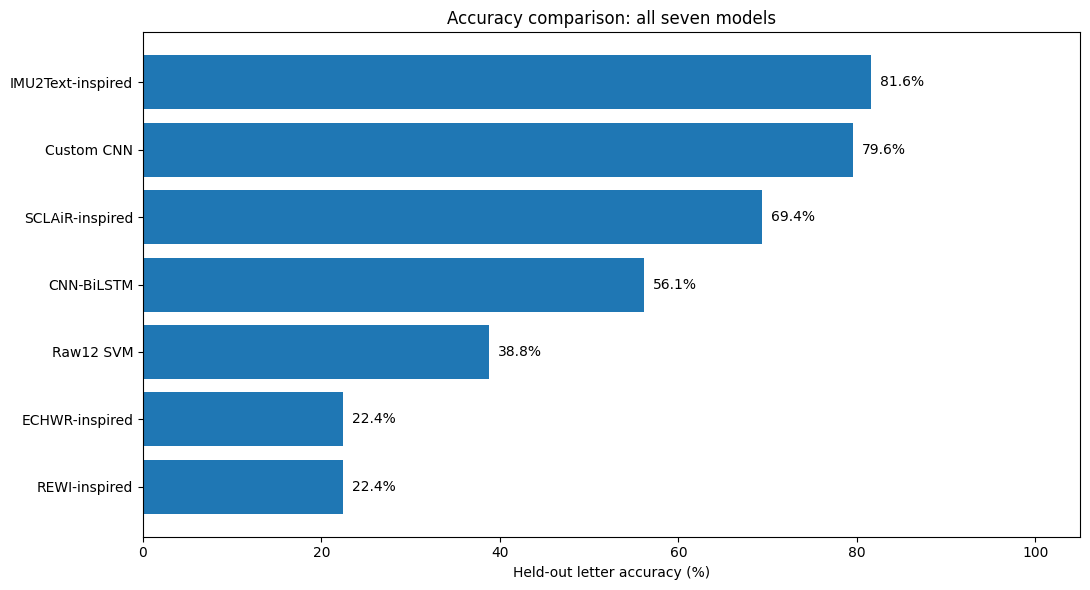


ACCURACY BY SENTENCE SESSION


source,FIRST SENTENCE,SECOND SENTENCE,THIRD SENTENCE
model,,,
IMU2Text-inspired,74.19,81.25,88.57
Custom CNN,64.52,90.62,82.86
SCLAiR-inspired,61.29,68.75,77.14
CNN-BiLSTM,45.16,68.75,54.29
Raw12 SVM,32.26,46.88,37.14
ECHWR-inspired,6.45,37.50,22.86
REWI-inspired,12.90,21.88,31.43


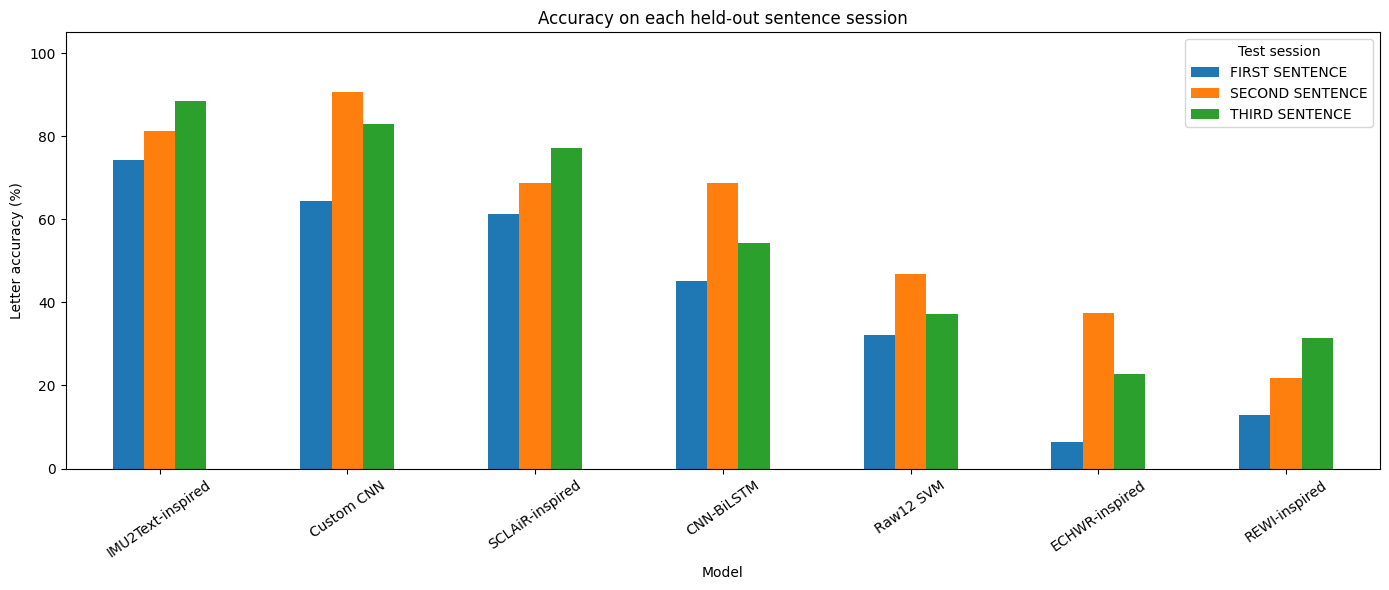

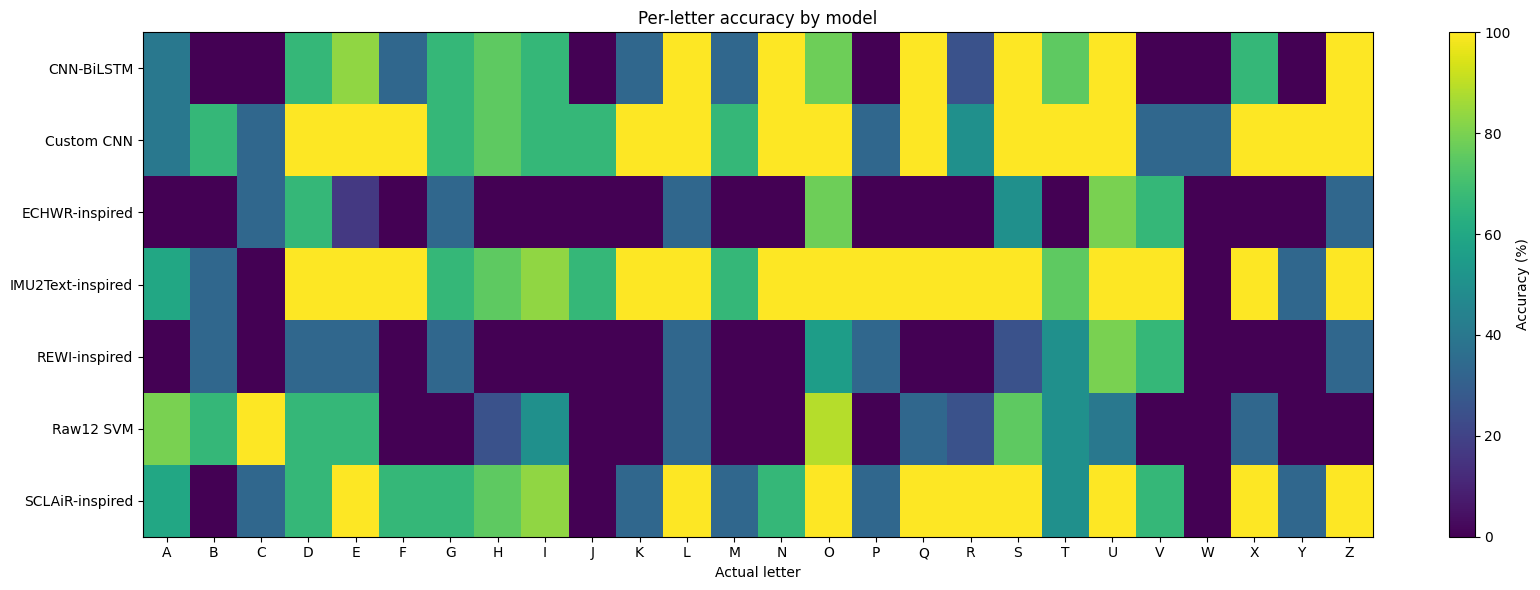

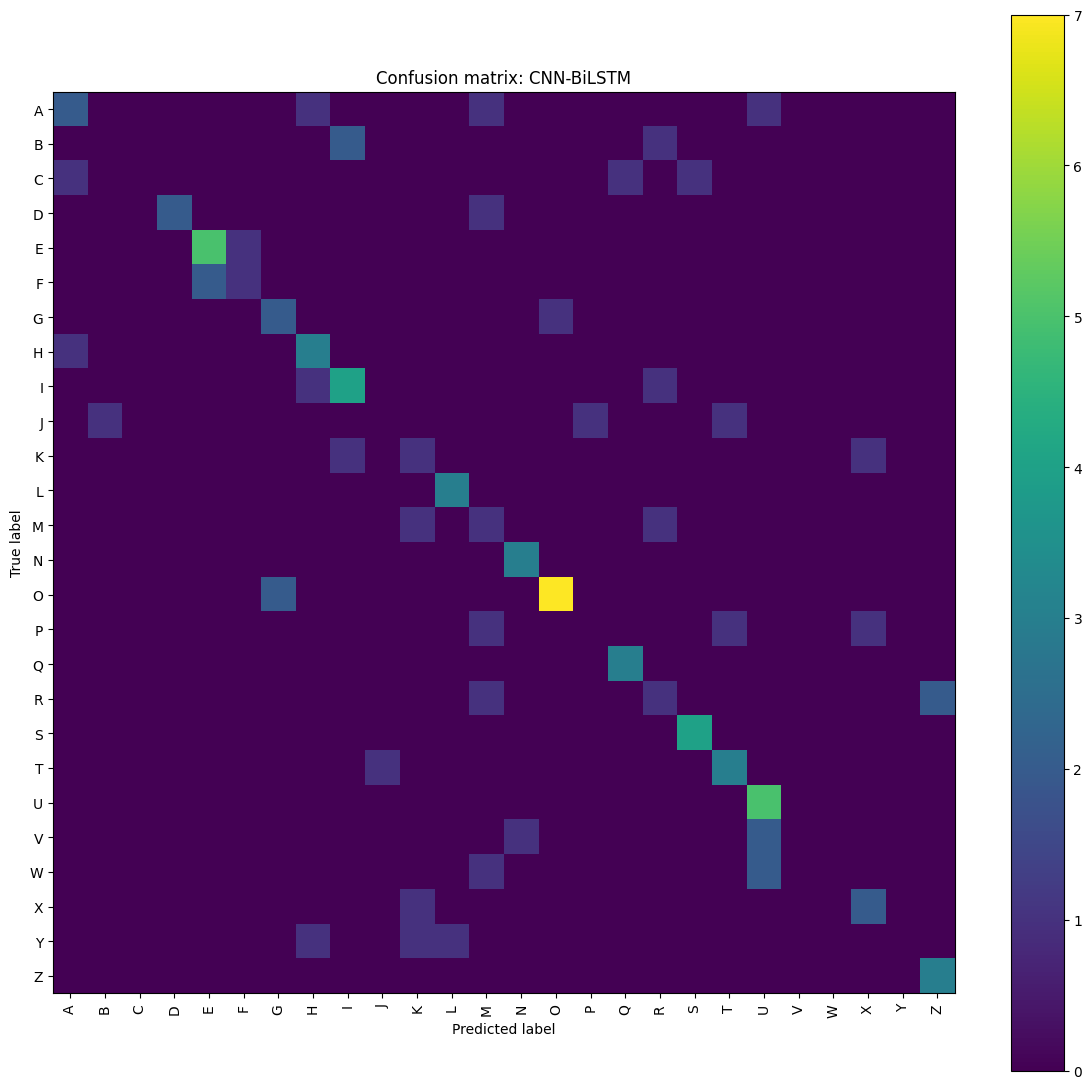

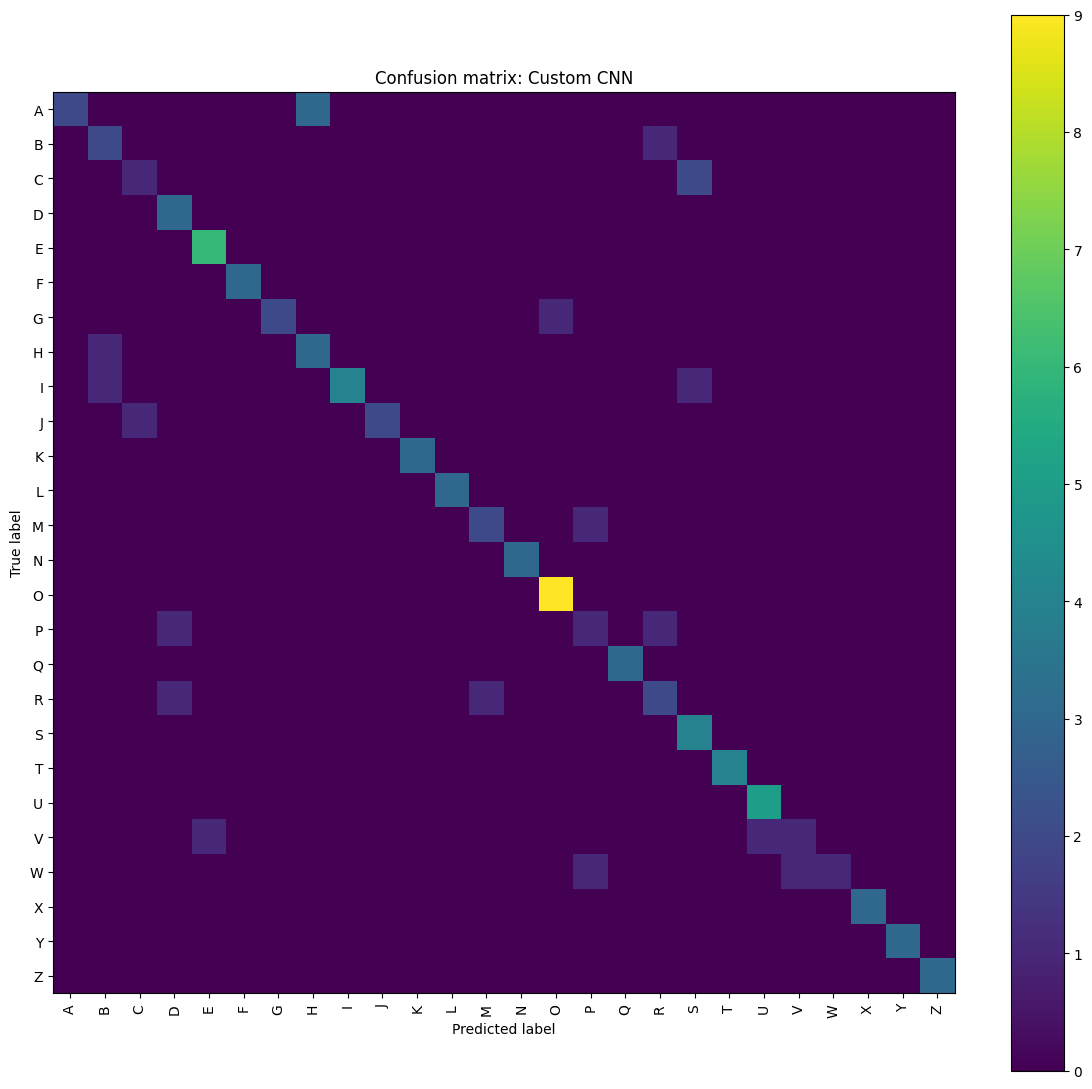

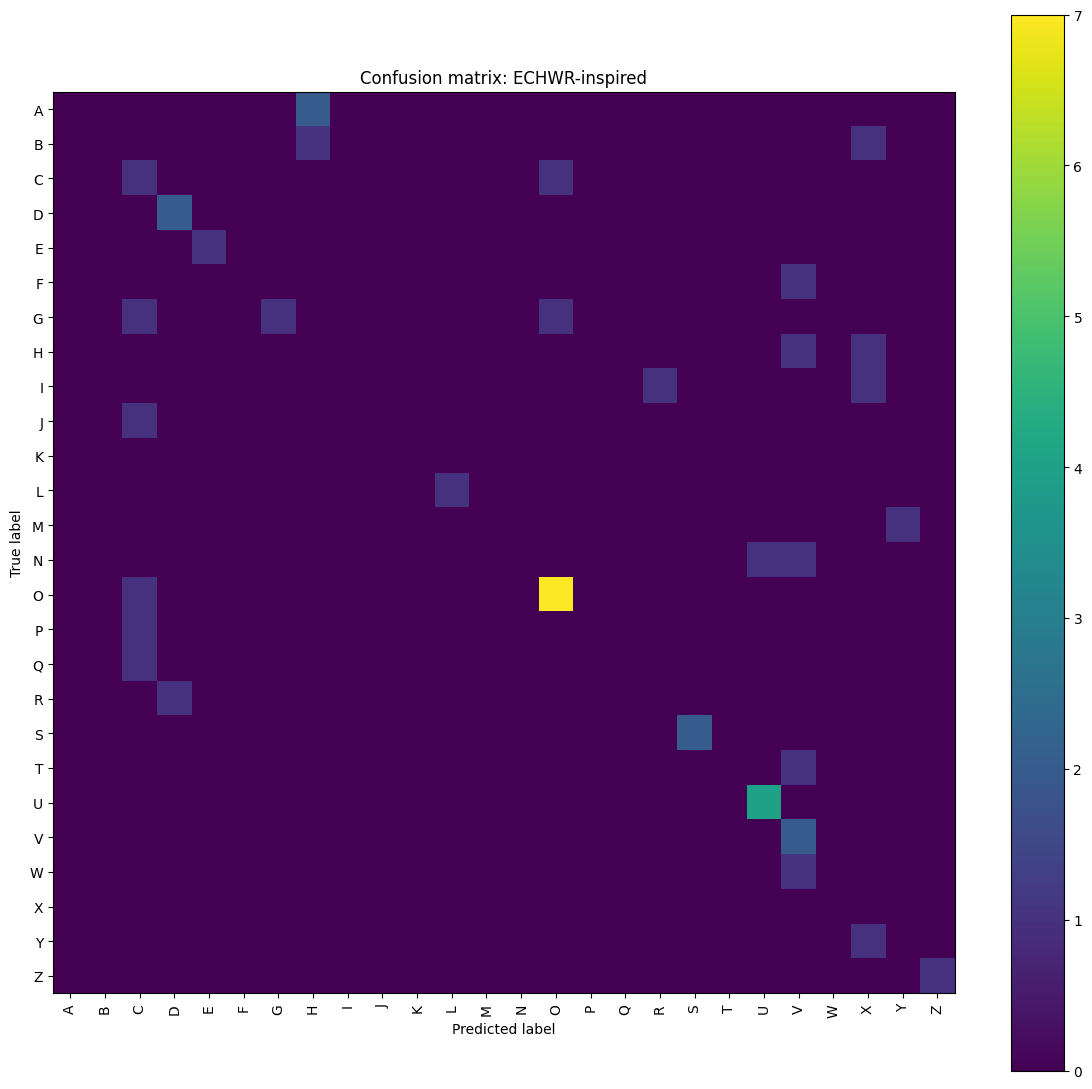

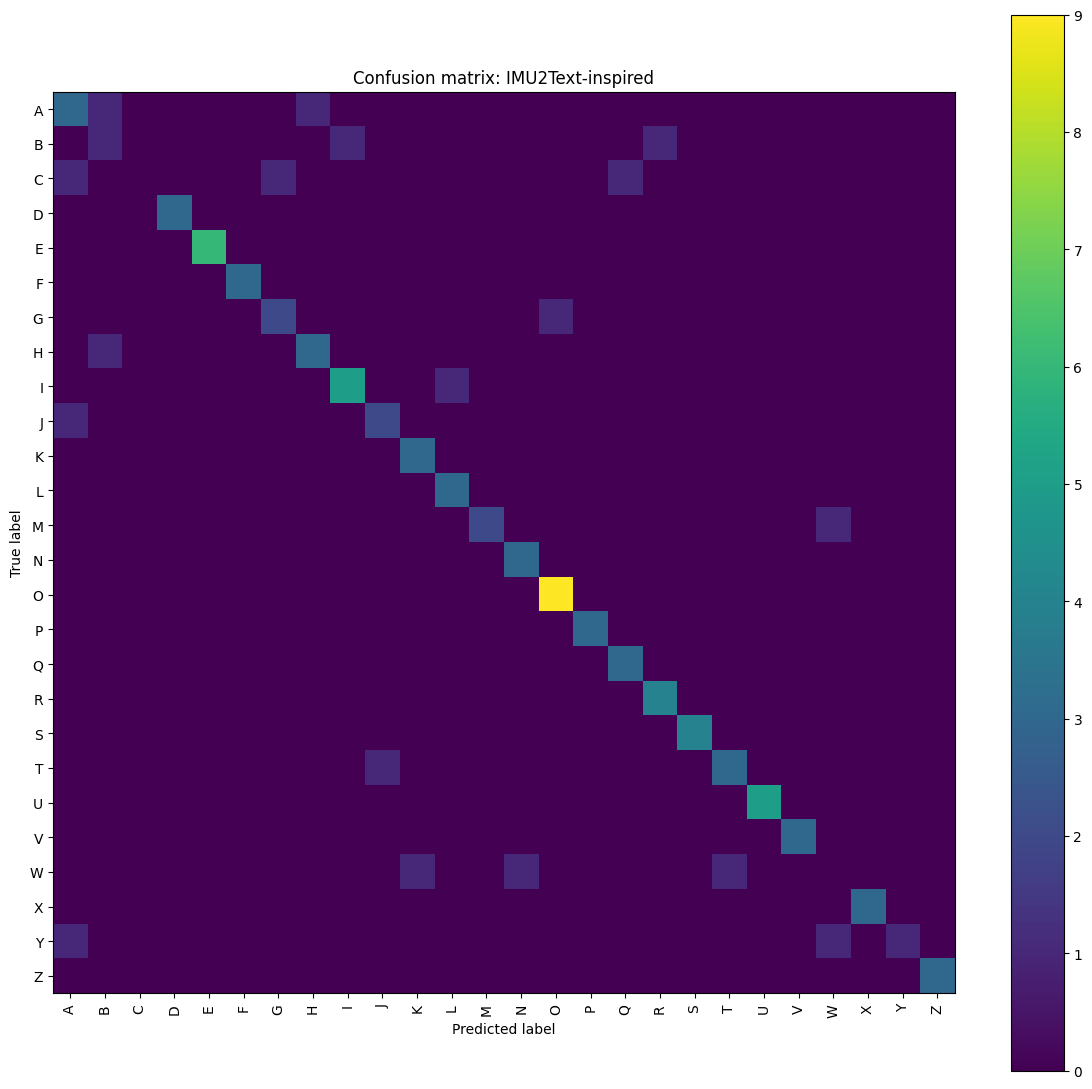

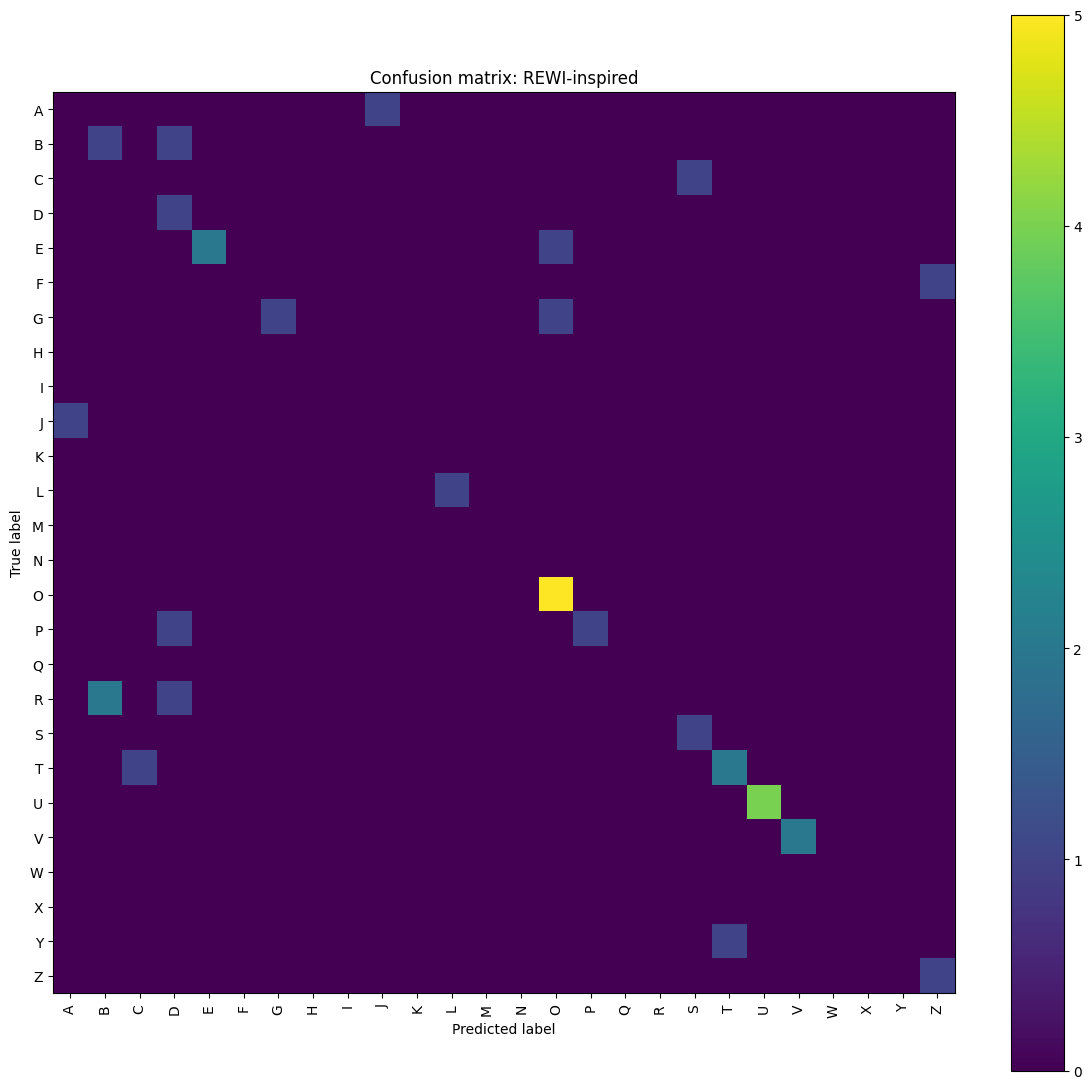

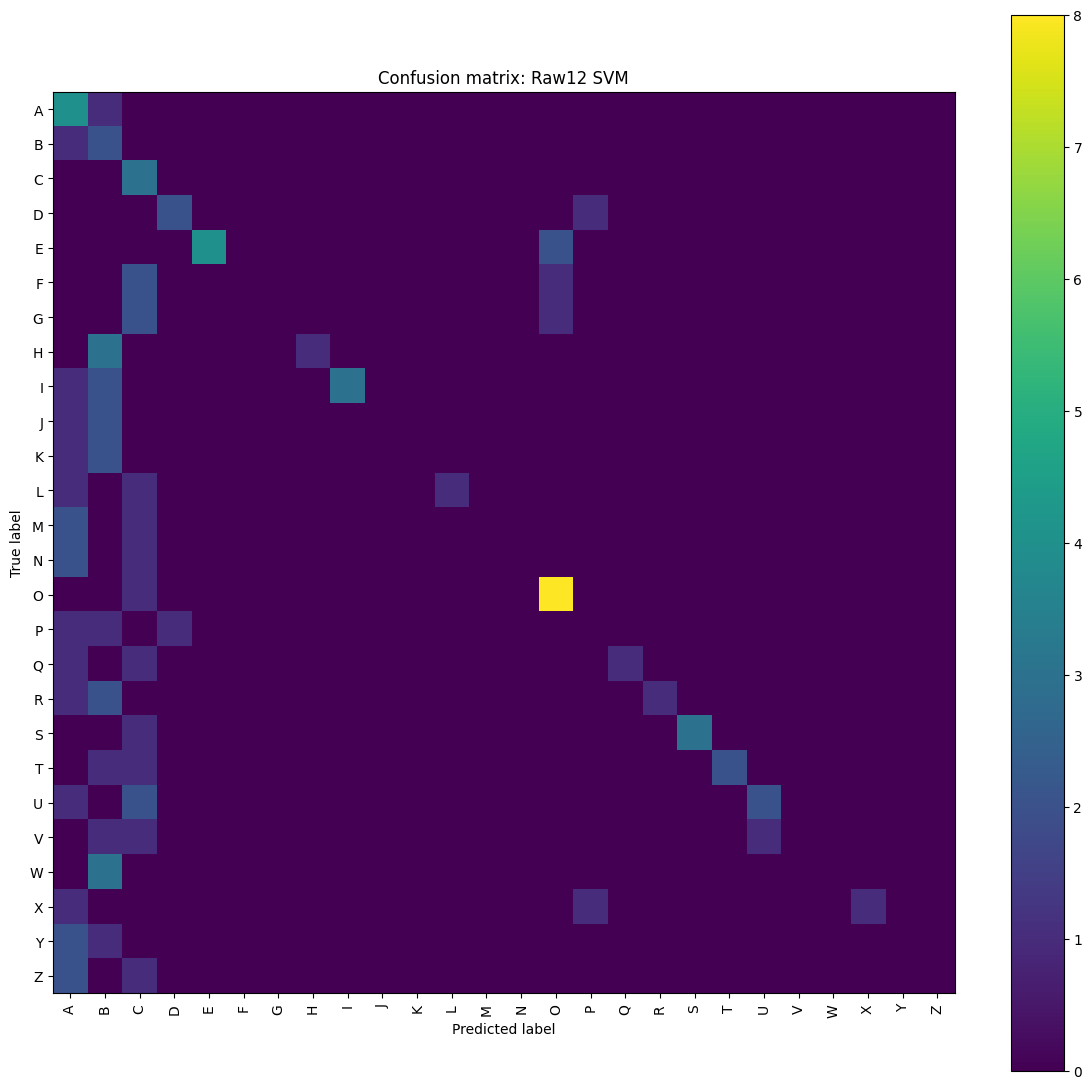

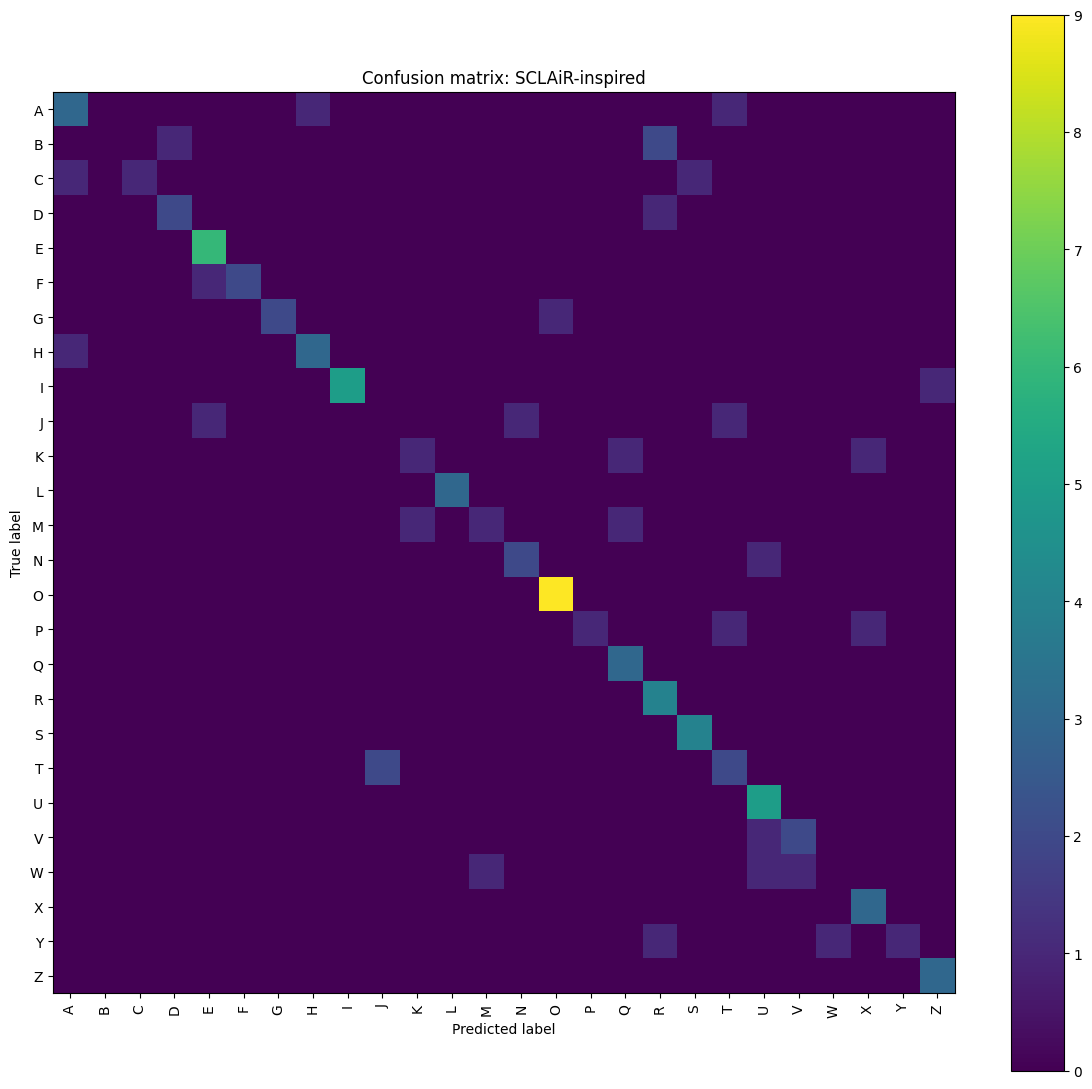

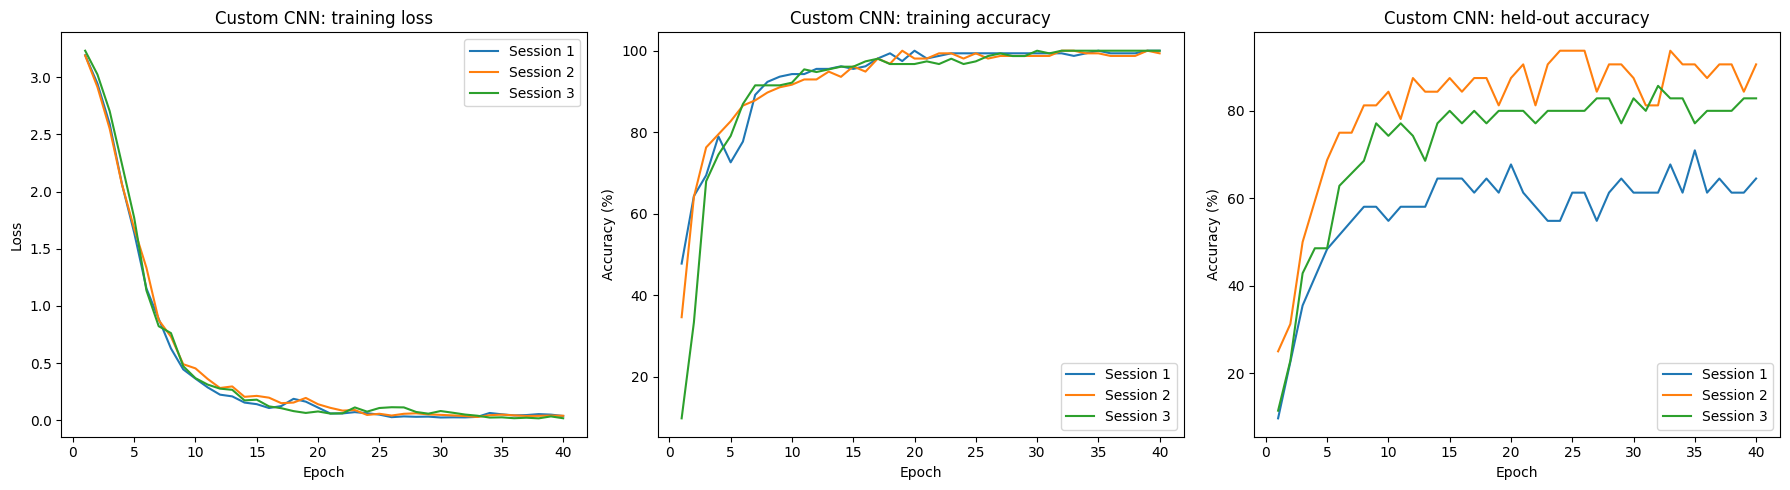

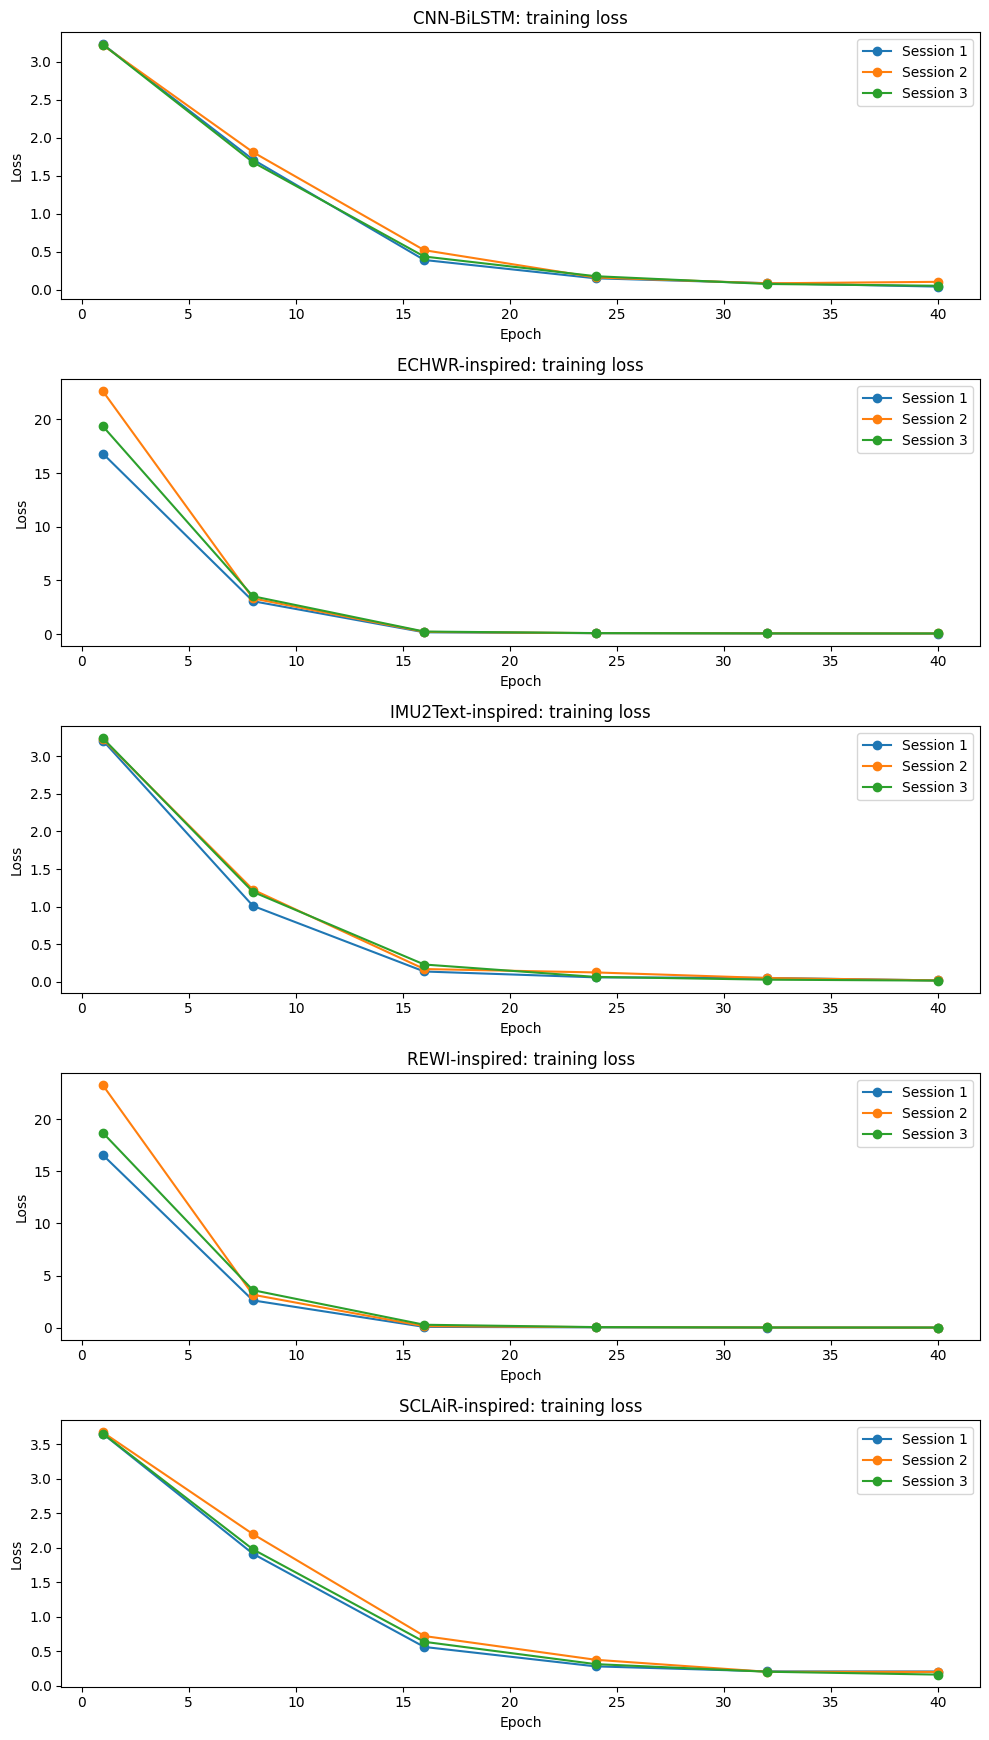


CONTINUOUS SENTENCE RESULTS


,fold,model,truth,prediction,cer
0,1,REWI-inspired,JACKDAWSLOVEMYBIGSPHINXOFQUARTZ,CMPMSLYHIGZPPXQQWDBE,0.709677
1,1,ECHWR-inspired,JACKDAWSLOVEMYBIGSPHINXOFQUARTZ,CPPYLCYWMYGAAQWHO,0.806452
2,2,REWI-inspired,PACKMYBOXWITHFIVEDOZENLIQOURJUGS,CCCCCCC,0.968750
3,2,ECHWR-inspired,PACKMYBOXWITHFIVEDOZENLIQOURJUGS,CCCCCCC,0.968750
4,3,REWI-inspired,THEQUICKBROWNFOXJUMPSOVERTHELAZYDOG,QQEP,0.942857
5,3,ECHWR-inspired,THEQUICKBROWNFOXJUMPSOVERTHELAZYDOG,DEEXIGFGSEEZPOG,0.742857


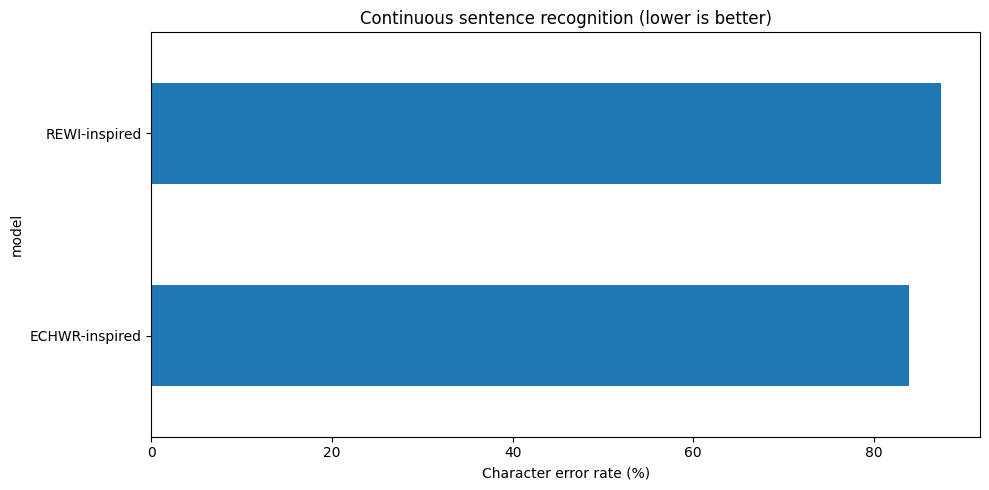

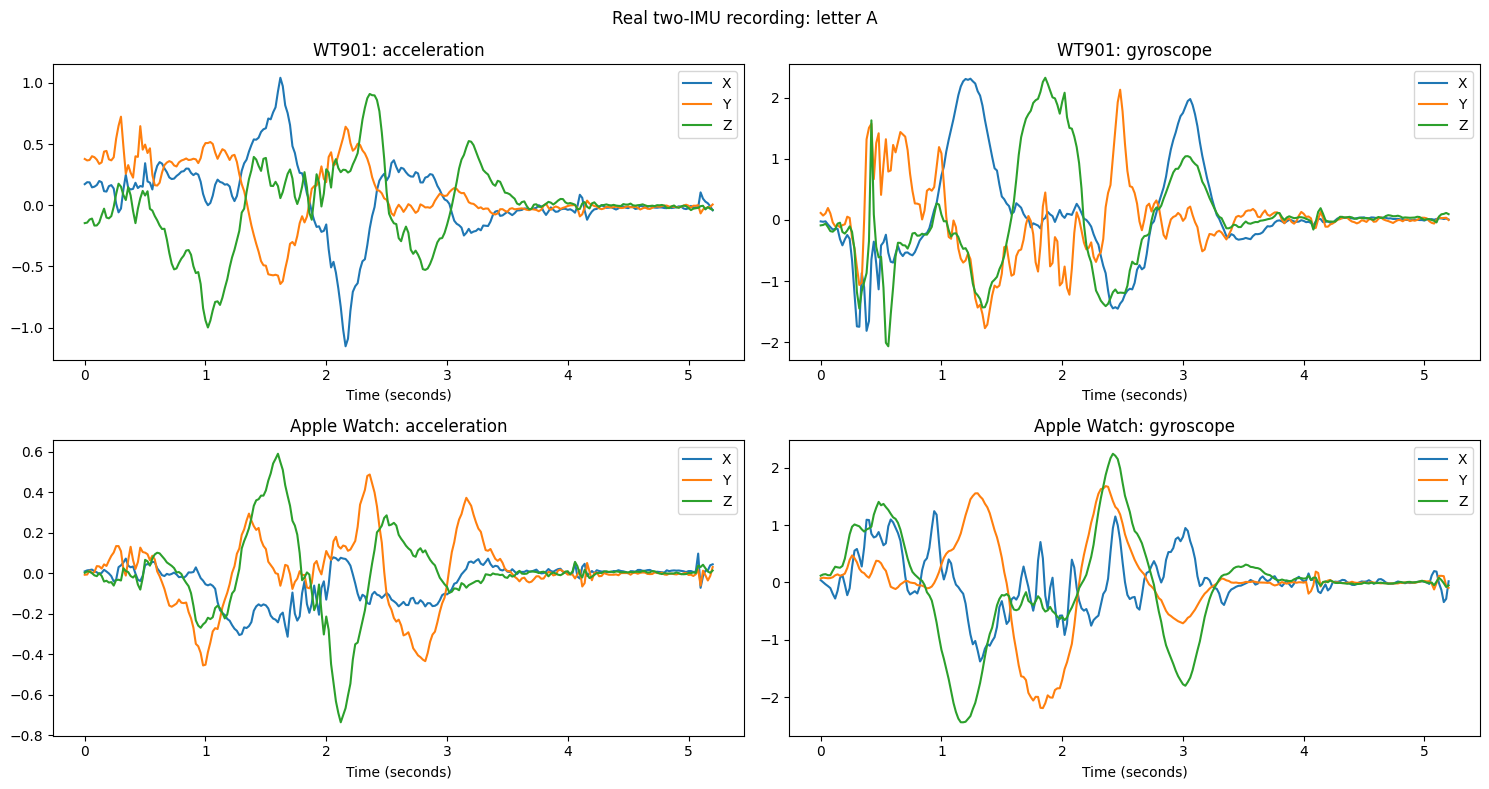


ALL VISUALIZATIONS COMPLETE!
Images saved: /content/airwrite_visual_results/images
Results package: /content/AirWrite_All_Visual_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:

import re
import zipfile
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display
from google.colab import files

OUT = Path("/content/airwrite_visual_results")
IMG = OUT / "images"
IMG.mkdir(parents=True, exist_ok=True)

# =====================================
# 1. COLLECT ALL MODEL PREDICTIONS
# =====================================

original = pd.read_csv(OUT / "letter_predictions.csv")
extra = pd.read_csv(OUT / "extra_model_predictions.csv")

df = pd.concat(
    [original, extra],
    ignore_index=True
)

df["correct"] = df["correct"].astype(int)

names = {
    "cnn_bilstm": "CNN-BiLSTM",
    "imu2text": "IMU2Text-inspired",
    "sclair": "SCLAiR-inspired",
    "rewi": "REWI-inspired",
    "echwr": "ECHWR-inspired",
}

df["model"] = df["model"].replace(names)

summary = (
    df.groupby("model")
    .agg(
        correct=("correct", "sum"),
        total=("correct", "size")
    )
    .reset_index()
)

summary["accuracy"] = (
    100 * summary["correct"] / summary["total"]
)

summary = summary.sort_values(
    "accuracy", ascending=False
)

print("\nOVERALL HELD-OUT ACCURACY")
display(summary)

summary.to_csv(
    OUT / "all_seven_model_accuracy.csv",
    index=False
)

# =====================================
# 2. OVERALL ACCURACY BAR CHART
# =====================================

plt.figure(figsize=(11, 6))

bars = plt.barh(
    summary["model"],
    summary["accuracy"]
)

plt.gca().invert_yaxis()
plt.xlim(0, 105)

for bar, acc in zip(bars, summary["accuracy"]):
    plt.text(
        acc + 1,
        bar.get_y() + bar.get_height()/2,
        f"{acc:.1f}%",
        va="center"
    )

plt.xlabel("Held-out letter accuracy (%)")
plt.title("Accuracy comparison: all seven models")
plt.tight_layout()
plt.savefig(IMG / "01_overall_accuracy.png", dpi=200)
plt.show()

# =====================================
# 3. ACCURACY ON EACH SENTENCE
# =====================================

by_session = (
    df.groupby(["model", "source"])
    ["correct"].mean()
    .mul(100)
    .unstack()
    .reindex(summary["model"])
)

print("\nACCURACY BY SENTENCE SESSION")
display(by_session.round(2))

ax = by_session.plot(
    kind="bar",
    figsize=(14, 6),
    rot=35
)

plt.ylabel("Letter accuracy (%)")
plt.xlabel("Model")
plt.title("Accuracy on each held-out sentence session")
plt.ylim(0, 105)
plt.legend(title="Test session")
plt.tight_layout()
plt.savefig(IMG / "02_accuracy_by_sentence.png", dpi=200)
plt.show()

# =====================================
# 4. ACCURACY FOR EACH LETTER A-Z
# =====================================

by_letter = (
    df.groupby(["model", "actual"])
    ["correct"].mean()
    .mul(100)
    .unstack()
    .reindex(
        columns=list("ABCDEFGHIJKLMNOPQRSTUVWXYZ"),
        fill_value=np.nan
    )
)

plt.figure(figsize=(17, 6))

plt.imshow(
    by_letter.to_numpy(dtype=float),
    aspect="auto",
    vmin=0,
    vmax=100
)

plt.colorbar(label="Accuracy (%)")

plt.xticks(
    range(26),
    list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")
)

plt.yticks(
    range(len(by_letter)),
    by_letter.index
)

plt.title("Per-letter accuracy by model")
plt.xlabel("Actual letter")
plt.tight_layout()
plt.savefig(IMG / "03_letter_accuracy_heatmap.png", dpi=200)
plt.show()

# =====================================
# 5. CONFUSION MATRIX FOR EACH MODEL
# =====================================

letters = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

for model_name in sorted(df["model"].unique()):

    part = df[df["model"] == model_name]

    cm = confusion_matrix(
        part["actual"],
        part["prediction"].fillna(""),
        labels=letters
    )

    fig, ax = plt.subplots(figsize=(12, 11))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=letters
    )

    disp.plot(
        ax=ax,
        include_values=False,
        xticks_rotation=90,
        colorbar=True
    )

    ax.set_title(f"Confusion matrix: {model_name}")
    plt.tight_layout()

    filename = re.sub(
        r"[^a-z0-9]+",
        "_",
        model_name.lower()
    )

    plt.savefig(
        IMG / f"confusion_{filename}.png",
        dpi=200
    )
    plt.show()

# =====================================
# 6. CUSTOM CNN TRAINING CURVES
# =====================================

history = pd.read_csv(
    OUT / "custom_cnn_training_history.csv"
)

fig, axes = plt.subplots(
    1, 3, figsize=(18, 5)
)

for fold, group in history.groupby("fold"):

    axes[0].plot(
        group["epoch"],
        group["training_loss"],
        label=f"Session {fold}"
    )

    axes[1].plot(
        group["epoch"],
        group["training_accuracy"],
        label=f"Session {fold}"
    )

    axes[2].plot(
        group["epoch"],
        group["validation_accuracy"],
        label=f"Session {fold}"
    )

axes[0].set_title("Custom CNN: training loss")
axes[1].set_title("Custom CNN: training accuracy")
axes[2].set_title("Custom CNN: held-out accuracy")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()

axes[0].set_ylabel("Loss")
axes[1].set_ylabel("Accuracy (%)")
axes[2].set_ylabel("Accuracy (%)")

plt.tight_layout()
plt.savefig(IMG / "04_custom_cnn_training.png", dpi=200)
plt.show()

# =====================================
# 7. TRAINING LOSS FOR THE OTHER 5
# =====================================

log_path = OUT / "five_model_training.log"

current_fold = None
current_model = None
rows = []

fold_pattern = re.compile(r"=== FOLD (\d+):")
model_pattern = re.compile(r"^\s*MODEL\s+(\w+)")
epoch_pattern = re.compile(
    r"^\s*(\w+) epoch (\d+)/(\d+), loss ([0-9.eE+-]+)"
)

for line in log_path.read_text().splitlines():

    match = fold_pattern.search(line)
    if match:
        current_fold = int(match.group(1))

    match = model_pattern.search(line)
    if match:
        current_model = match.group(1)

    match = epoch_pattern.search(line)
    if match:
        rows.append({
            "fold": current_fold,
            "model": current_model or match.group(1),
            "epoch": int(match.group(2)),
            "loss": float(match.group(4))
        })

loss_df = pd.DataFrame(rows)

if not loss_df.empty:

    loss_df["model"] = loss_df["model"].replace(names)

    models = sorted(loss_df["model"].unique())

    fig, axes = plt.subplots(
        len(models), 1,
        figsize=(10, 3.5 * len(models)),
        squeeze=False
    )

    for ax, model_name in zip(axes[:, 0], models):

        part = loss_df[
            loss_df["model"] == model_name
        ]

        for fold, group in part.groupby("fold"):
            ax.plot(
                group["epoch"],
                group["loss"],
                marker="o",
                label=f"Session {fold}"
            )

        ax.set_title(f"{model_name}: training loss")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.legend()

    plt.tight_layout()
    plt.savefig(
        IMG / "05_other_model_training_curves.png",
        dpi=200
    )
    plt.show()

    loss_df.to_csv(
        OUT / "five_model_training_history.csv",
        index=False
    )

# =====================================
# 8. CONTINUOUS SENTENCE RESULTS
# =====================================

sentence_file = OUT / "sentence_predictions.csv"

if sentence_file.exists():

    sentences = pd.read_csv(sentence_file)
    sentences["model"] = sentences["model"].replace(names)

    print("\nCONTINUOUS SENTENCE RESULTS")
    display(
        sentences[
            ["fold", "model", "truth", "prediction", "cer"]
        ]
    )

    cer = (
        sentences.groupby("model")["cer"]
        .mean()
        .mul(100)
        .sort_values()
    )

    plt.figure(figsize=(10, 5))
    cer.plot(kind="barh")

    plt.xlabel("Character error rate (%)")
    plt.title("Continuous sentence recognition (lower is better)")
    plt.tight_layout()
    plt.savefig(
        IMG / "06_continuous_sentence_CER.png",
        dpi=200
    )
    plt.show()

# =====================================
# 9. VIEW A REAL IMU RECORDING
# =====================================

sample = next(
    r for r in records
    if not r["whole"]
    and r["sensor_status"] == "two_IMU"
)

signal = sample["x"]
time = np.arange(len(signal)) / 50.0

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 8)
)

labels = ["X", "Y", "Z"]

for i in range(3):

    axes[0, 0].plot(
        time, signal[:, i],
        label=labels[i]
    )

    axes[0, 1].plot(
        time, signal[:, i+3],
        label=labels[i]
    )

    axes[1, 0].plot(
        time, signal[:, i+6],
        label=labels[i]
    )

    axes[1, 1].plot(
        time, signal[:, i+9],
        label=labels[i]
    )

axes[0, 0].set_title("WT901: acceleration")
axes[0, 1].set_title("WT901: gyroscope")
axes[1, 0].set_title("Apple Watch: acceleration")
axes[1, 1].set_title("Apple Watch: gyroscope")

for ax in axes.flat:
    ax.set_xlabel("Time (seconds)")
    ax.legend()

plt.suptitle(
    f"Real two-IMU recording: letter {sample['label']}"
)

plt.tight_layout()
plt.savefig(IMG / "07_raw_sensor_signals.png", dpi=200)
plt.show()

# =====================================
# 10. EXPORT ALL IMAGES + RESULTS
# =====================================

archive = Path("/content/AirWrite_All_Visual_Results.zip")

with zipfile.ZipFile(
    archive, "w",
    zipfile.ZIP_DEFLATED
) as z:

    for path in OUT.rglob("*"):
        if path.is_file() and path != archive:
            z.write(
                path,
                path.relative_to(OUT)
            )

print("\nALL VISUALIZATIONS COMPLETE!")
print("Images saved:", IMG)
print("Results package:", archive)

files.download(str(archive))


In [10]:
# REAL CHECKPOINT FINE-TUNING — NOT TRAINING FROM SCRATCH
# Run in Google Colab. Upload IMU_Project_Backup.zip when requested.
import io, zipfile, random, math, shutil, re
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset, DataLoader, WeightedRandomSampler
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

ROOT = Path('/content') if Path('/content').exists() else Path('/mnt/data')
ROOT.mkdir(exist_ok=True)
OUT = ROOT/'AirWrite_FineTune_Results'
OUT.mkdir(exist_ok=True)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE)

# 1. Load PREVIOUSLY SAVED WEIGHTS and datasets. Fail if the checkpoint is missing.
backups = sorted(ROOT.glob('IMU_Project_Backup*.zip'))
if not backups:
    try:
        from google.colab import files
        print('Upload IMU_Project_Backup.zip (your previously downloaded backup).')
        files.upload()
    except ImportError:
        pass
    backups = sorted(ROOT.glob('IMU_Project_Backup*.zip'))
if not backups:
    raise FileNotFoundError('Please upload IMU_Project_Backup.zip. This code will not train from scratch.')

with zipfile.ZipFile(backups[-1]) as z:
    names = z.namelist()
    weight_name = next((n for n in names if Path(n).name == 'cnn_session_test.pt'), None)
    old_name = next((n for n in names if Path(n).name.startswith('rewi_2imu_processed') and n.endswith('.pt')), None)
    abc_name = next((n for n in names if Path(n).name.startswith('abc_87_heldout_2imu') and n.endswith('.pt')), None)
    if not all((weight_name, old_name, abc_name)):
        raise FileNotFoundError('Backup must contain cnn_session_test.pt, rewi_2imu_processed*.pt, and abc_87_heldout_2imu.pt. Found: '+str(names))
    weights = torch.load(io.BytesIO(z.read(weight_name)), map_location='cpu', weights_only=True)
    original_data = torch.load(io.BytesIO(z.read(old_name)), map_location='cpu', weights_only=True)
    abc_data = torch.load(io.BytesIO(z.read(abc_name)), map_location='cpu', weights_only=True)

# Exact architecture of the ORIGINAL custom CNN, not a new adaptation.
def make_model():
    return nn.Sequential(
        nn.Conv1d(12,32,7,padding=3), nn.GroupNorm(4,32), nn.GELU(), nn.MaxPool1d(2),
        nn.Conv1d(32,64,5,padding=2), nn.GroupNorm(8,64), nn.GELU(), nn.MaxPool1d(2),
        nn.Conv1d(64,64,5,padding=2), nn.GroupNorm(8,64), nn.GELU(),
        nn.AdaptiveAvgPool1d(8), nn.Flatten(), nn.Dropout(.35),
        nn.Linear(512,64), nn.GELU(), nn.Dropout(.30), nn.Linear(64,26)
    )
model = make_model()
model.load_state_dict(weights, strict=True)   # Fails if architecture/weights are incompatible.
model = model.to(DEVICE)
print('LOADED EXISTING PRETRAINED CNN:', weight_name)
print('Previously collected sentence records:', len(original_data))
print('Newer A/B/C records:', len(abc_data))

# 2. USE ONLY INDIVIDUALLY RECORDED LETTERS (never WHOLE sentence files).
# IMPORTANT: cnn_session_test.pt was originally trained on the individually recorded
# FIRST and SECOND sentence letters. The THIRD sentence letters were held out.
# We fine-tune on FIRST + SECOND *individual letters*, with ABC training examples,
# and keep THIRD individual letters entirely out of optimization/model selection.
letters = set('ABCDEFGHIJKLMNOPQRSTUVWXYZ')

def is_individual_letter(sample):
    label = sample.get('label')
    filepath = str(sample.get('file', '')).replace('\\', '/').upper()
    return (isinstance(label, str) and len(label) == 1 and
            label in letters and '/WHOLE/' not in filepath and
            not bool(sample.get('whole', False)))

sentence_first = [s for s in original_data if is_individual_letter(s)
                  and 'FIRST SENTENCE' in str(s.get('source', '')).upper()]
sentence_second = [s for s in original_data if is_individual_letter(s)
                   and 'SECOND SENTENCE' in str(s.get('source', '')).upper()]
sentence_third = [s for s in original_data if is_individual_letter(s)
                  and 'THIRD SENTENCE' in str(s.get('source', '')).upper()]

if not all((sentence_first, sentence_second, sentence_third)):
    raise ValueError('Could not find individual letters in all three sentence archives.')
old_replay = sentence_first + sentence_second
old_third = sentence_third

# A/B/C are NEWER individually recorded letters, also not continuous sentences.
abc_train, abc_val = [], []
for letter in 'ABC':
    items = [s for s in abc_data if is_individual_letter(s) and s['label'] == letter]
    if len(items) < 2:
        raise ValueError(f'Need at least 2 individual recordings of {letter}.')
    random.Random(SEED + ord(letter)).shuffle(items)
    n_val = max(1, round(len(items) * .20))
    abc_val.extend(items[:n_val])
    abc_train.extend(items[n_val:])

# Fine-tune only on letter-level data from sentence 1 and 2 + ABC training split.
train_data = old_replay + abc_train

# Explicit safety check: no THIRD sentence examples and no WHOLE recording in training.
assert all(is_individual_letter(s) for s in train_data)
assert not any('THIRD SENTENCE' in str(s.get('source', '')).upper()
               for s in train_data)
assert all(is_individual_letter(s) for s in old_third)

print('\nINDIVIDUAL-LETTER FINE-TUNING DATA')
print('Sentence 1 individual letters (train/replay):', len(sentence_first))
print('Sentence 2 individual letters (train/replay):', len(sentence_second))
print('New A/B/C individual letters (fine-tune):', len(abc_train))
print('A/B/C individual letters (validation):', len(abc_val))
print('Sentence 3 individual letters (HELD OUT):', len(sentence_third))
print('TOTAL fine-tuning samples:', len(train_data))
print('WHOLE continuous sentence recordings in fine-tuning: 0')

# Exact original 128-step preprocessing, with NO new normalization.
def prepare(samples):
    X, y = [], []
    for s in samples:
        x = s['x'].float()
        if x.ndim != 2 or x.shape[0] != 12 or x.shape[1] < 2 or not bool(torch.isfinite(x).all()):
            raise ValueError(f'Invalid two-IMU recording: {s.get("file", "?")} {tuple(x.shape)}')
        x = F.interpolate(x.unsqueeze(0), size=128, mode='linear', align_corners=False).squeeze(0)
        X.append(x)
        y.append(ord(s['label']) - 65)
    return torch.stack(X), torch.tensor(y, dtype=torch.long)

Xtrain, ytrain = prepare(train_data)
Xval, yval = prepare(abc_val)

@torch.no_grad()
def evaluate(model, samples, label):
    X, y = prepare(samples)
    model.eval()
    logits = []
    for chunk in X.split(32):
        logits.append(model(chunk.to(DEVICE)).cpu())
    logits = torch.cat(logits)
    pred = logits.argmax(1)
    correct = int((pred == y).sum())
    score = 100 * correct / len(y)
    rows = [dict(dataset=label,actual=chr(int(a)+65),prediction=chr(int(p)+65),correct=int(a==p),source=str(s.get('source')),file=str(s.get('file'))) for s,a,p in zip(samples,y,pred)]
    return score, rows, float(F.cross_entropy(logits,y))

# BEFORE fine-tuning scores
before_scores = {}
for name, samples in [('ABC_validation',abc_val),('SENTENCE_1_seen', [s for s in old_replay if 'FIRST' in s.get('source','').upper()]),('SENTENCE_2_seen', [s for s in old_replay if 'SECOND' in s.get('source','').upper()]),('SENTENCE_3_unseen',old_third)]:
    before_scores[name] = evaluate(model,samples,name)[0]
    print(f'BEFORE | {name}: {before_scores[name]:.1f}%')

# 3. Fine-tune LOADED weights using a SMALL learning rate.
# Stop using A/B/C validation loss, NEVER third-session test loss.
counts = Counter(ytrain.tolist())
weights_sampling = torch.tensor([1.0 / math.sqrt(counts[int(y)]) for y in ytrain],dtype=torch.double)
loader = DataLoader(TensorDataset(Xtrain,ytrain),batch_size=16,sampler=WeightedRandomSampler(weights_sampling,num_samples=len(ytrain),replacement=True))
optimizer = torch.optim.AdamW(model.parameters(),lr=0.0001,weight_decay=.01)
EPOCHS = 20
best_val_loss = float('inf')
history = []
checkpoint_path = OUT/'cnn_real_finetuned.pt'
for epoch in range(1,EPOCHS+1):
    model.train(); total_loss=0.; n=0
    for xb, yb in loader:
        xb=xb.to(DEVICE); yb=yb.to(DEVICE)
        scale = torch.empty(xb.size(0),12,1,device=DEVICE).uniform_(.97,1.03)
        xb = xb * scale + .01*torch.randn_like(xb)
        optimizer.zero_grad()
        loss=F.cross_entropy(model(xb),yb)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.)
        optimizer.step()
        total_loss += float(loss.item())*len(yb); n += len(yb)
    score,_,val_loss=evaluate(model,abc_val,'ABC_validation')
    history.append(dict(epoch=epoch,train_loss=total_loss/n,abc_val_loss=val_loss,abc_val_accuracy=score))
    if val_loss < best_val_loss:
        best_val_loss=val_loss
        torch.save({'state_dict':model.state_dict(),'initial_checkpoint':weight_name,'fine_tuning_data':'individual FIRST and SECOND sentence letters + A/B/C training letters, excludes WHOLE','input_channels':12},checkpoint_path)
    if epoch==1 or epoch%5==0:
        print(f'Epoch {epoch:02d}/{EPOCHS} | loss {total_loss/n:.3f} | ABC val {score:.1f}%')

# 4. Reload best REAL fine-tuned model, test INDIVIDUAL letters from all three sessions.
ckpt = torch.load(checkpoint_path,map_location=DEVICE,weights_only=True)
model.load_state_dict(ckpt['state_dict'],strict=True)
model.eval()
results=[]; rows=[]
for name,samples in [
    ('ABC_validation',abc_val),
    ('SENTENCE_1_seen',[s for s in old_replay if 'FIRST' in s.get('source','').upper()]),
    ('SENTENCE_2_seen',[s for s in old_replay if 'SECOND' in s.get('source','').upper()]),
    ('SENTENCE_3_unseen',old_third)]:
    score,pred_rows,_=evaluate(model,samples,name)
    rows.extend(pred_rows)
    results.append(dict(dataset=name,before_pct=before_scores[name],after_pct=score,num_letters=len(samples),correct=sum(r['correct'] for r in pred_rows)))
    print(f'{name:22s} | before {before_scores[name]:5.1f}% | after {score:5.1f}% | {sum(r["correct"] for r in pred_rows)}/{len(samples)}')

summary = pd.DataFrame(results)
preds = pd.DataFrame(rows)
pd.DataFrame(history).to_csv(OUT/'training_history.csv',index=False)
summary.to_csv(OUT/'accuracy_before_after.csv',index=False)
preds.to_csv(OUT/'letter_predictions.csv',index=False)

# 5. Actual visual results — never fabricated example numbers.
fig,ax=plt.subplots(figsize=(11,5)); yy=np.arange(len(summary)); w=.36
ax.barh(yy-w/2,summary.before_pct,w,label='Before fine-tuning')
ax.barh(yy+w/2,summary.after_pct,w,label='After fine-tuning')
ax.set_yticks(yy,summary.dataset);ax.set_xlim(0,100);ax.set_xlabel('Accuracy (%)');ax.legend();ax.set_title('Saved CNN checkpoint: before vs after fine-tuning')
fig.tight_layout();fig.savefig(OUT/'01_accuracy_before_after.png',dpi=180);plt.show()

hist=pd.DataFrame(history)
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(hist.epoch,hist.train_loss,label='Fine-tuning training loss')
ax.plot(hist.epoch,hist.abc_val_loss,label='A/B/C validation loss')
ax.set_xlabel('Fine-tuning epoch');ax.set_ylabel('Cross-entropy loss');ax.set_title('Fine-tuning learning curves');ax.legend()
fig.tight_layout();fig.savefig(OUT/'02_finetuning_curves.png',dpi=180);plt.show()

# Confusion matrix only on the genuine held-out THIRD session.
third_preds=preds[preds.dataset=='SENTENCE_3_unseen']
cm=confusion_matrix(third_preds.actual,third_preds.prediction,labels=list('ABCDEFGHIJKLMNOPQRSTUVWXYZ'))
fig,ax=plt.subplots(figsize=(11,10))
ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=list('ABCDEFGHIJKLMNOPQRSTUVWXYZ')).plot(ax=ax,include_values=False,xticks_rotation=90)
ax.set_title('Sentence 3: unseen-letter confusion matrix')
fig.tight_layout();fig.savefig(OUT/'03_sentence3_confusion.png',dpi=180);plt.show()

# Plot real WT901 & Apple Watch signal from an A/B/C recording.
example=abc_val[0]
xx=example['x'].float().numpy().T
fig,axes=plt.subplots(2,1,figsize=(12,7),sharex=True)
for j in range(6):axes[0].plot(xx[:,j],label=['ax','ay','az','gx','gy','gz'][j])
for j in range(6):axes[1].plot(xx[:,j+6],label=['ax','ay','az','gx','gy','gz'][j])
axes[0].set_title('WT901: real acceleration and gyroscope channels')
axes[1].set_title('Apple Watch: real acceleration and gyroscope channels')
for ax in axes: ax.legend(ncol=6,fontsize=8);ax.set_ylabel('Recorded values (see original units)')
axes[1].set_xlabel('Sample index')
fig.suptitle('Recorded letter '+example['label']);fig.tight_layout();fig.savefig(OUT/'04_real_imu_signals.png',dpi=180);plt.show()

archive=shutil.make_archive(str(ROOT/'AirWrite_Real_FineTune_Results'),'zip',root_dir=str(OUT))
print('\nFINISHED. Results ZIP:',archive)
print('IMPORTANT: Sentence 1 and 2 were used in initial training AND individual-letter fine-tuning — not independent tests.')
print('Sentence 3 contains held-out INDIVIDUAL letters. No WHOLE continuous sentence recognition is claimed.')
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    pass


Device: cuda
Upload IMU_Project_Backup.zip (your previously downloaded backup).


KeyboardInterrupt: 

In [11]:
# SET THESE TO TRUE WHEN READY TO LAUNCH THE CORRESPONDING STEP
DOWNLOAD_PUBLIC_DATA = False         # Downloads OnHW chars (~896 MB), Words500 (~849 MB)
RUN_ADAPTED_PRETRAIN = False         # Five model variants trained on their public datasets
RUN_ADAPTED_FINETUNE = False         # Load public checkpoints + adapt to your 2 IMUs
RUN_OFFICIAL_REWI_ECHWR_PRETRAIN = False  # Author code + OnHW words
RUN_OFFICIAL_REWI_ECHWR_FINETUNE = False # Author code + your data

PUBLIC_EPOCHS = 30
PERSONAL_EPOCHS = 12
OFFICIAL_PUBLIC_EPOCHS = 60
OFFICIAL_PERSONAL_EPOCHS = 20
FOLDS = (1,2,3) # each time one complete sentence SESSION is held out
PUBLIC_SAMPLE_LIMIT = 0  # 0 = all, 2000 = quick dev subset (not full original training)

from pathlib import Path
ROOT=Path('/content')
print('Public downloads:',DOWNLOAD_PUBLIC_DATA)
print('Adapted models pretrain/fine-tune:',RUN_ADAPTED_PRETRAIN,RUN_ADAPTED_FINETUNE)
print('Official models pretrain/fine-tune:',RUN_OFFICIAL_REWI_ECHWR_PRETRAIN,RUN_OFFICIAL_REWI_ECHWR_FINETUNE)

Public downloads: False
Adapted models pretrain/fine-tune: False False
Official models pretrain/fine-tune: False False


In [12]:
import os, subprocess, sys, importlib.util
from pathlib import Path

def shell(*cmd, cwd=None):
    print('RUN:', ' '.join(map(str,cmd)),flush=True)
    subprocess.run(list(map(str,cmd)),cwd=cwd,check=True)

shell(sys.executable,'-m','pip','install','-q','numpy','pandas','scipy','scikit-learn','pyyaml','loguru','tqdm','einops','jiwer','Levenshtein','thop','timm','umap-learn')
repos={'SCLAiR':'https://github.com/ayushayt/SCLAiR.git',
       'imu2text':'https://github.com/vahinitech/imu2text.git',
       'REWI':'https://github.com/jindongli24/REWI.git',
       'ECHWR':'https://github.com/jindongli24/ECHWR.git'}
for name,url in repos.items():
    path=ROOT/name
    if not (path/'.git').exists(): shell('git','clone','--depth','1',url,path)

sys.path.insert(0,str(ROOT))
print('All official repositories checked out. PyTorch:',__import__('torch').__version__)
print('GPU available:',__import__('torch').cuda.is_available())

RUN: /usr/bin/python3 -m pip install -q numpy pandas scipy scikit-learn pyyaml loguru tqdm einops jiwer Levenshtein thop timm umap-learn
RUN: git clone --depth 1 https://github.com/ayushayt/SCLAiR.git /content/SCLAiR
RUN: git clone --depth 1 https://github.com/vahinitech/imu2text.git /content/imu2text
RUN: git clone --depth 1 https://github.com/jindongli24/REWI.git /content/REWI
RUN: git clone --depth 1 https://github.com/jindongli24/ECHWR.git /content/ECHWR
All official repositories checked out. PyTorch: 2.14.1+cu130
GPU available: True


In [13]:
%%writefile /content/benchmark.py
#!/usr/bin/env python3
"""
Two-IMU uppercase air-writing benchmark.

Five locally adaptable architectures (NOT official released model reproductions):
  cnn_bilstm: temporal CNN + BiLSTM letter classifier
  imu2text: CNN + BiLSTM + attention letter classifier (IMU2Text-inspired)
  sclair: supervised-contrastive CNN + BiLSTM letter classifier (SCLAiR-inspired)
  rewi: temporal CNN + BiLSTM + CTC sequence model (REWI-inspired)
  echwr: REWI-like CTC plus training-only positive/typo text contrastive branch
         (ECHWR-inspired approximation, not paper's original text encoder)

Train isolated letters from other sessions; test held-out sentence session's
isolated letters. For CTC models, train on isolated letters AND artificial
concatenations of training clips; test real WHOLE recordings. Since artificial
concatenation is not natural continuous handwriting, sentence CER is exploratory.
No lowercase files are present. No writer-independent claims are supported.
"""
from __future__ import annotations
import argparse
import csv
import io
import json
import logging
import os
import random
import re
import sys
import zipfile
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

MODELS = ('cnn_bilstm','imu2text','sclair','rewi','echwr')
SESSIONS = ('FIRST SENTENCE','SECOND SENTENCE','THIRD SENTENCE')
ABC = ('A','B','C')
ALPHABET = 'ABCDEFGHIJKLMNOPQRSTUVWXYZ'
WT_COLS = ['AccX(g)','AccY(g)','AccZ(g)','AsX(°/s)','AsY(°/s)','AsZ(°/s)']
WATCH_COLS = ['accelerationX','accelerationY','accelerationZ','rotationRateX','rotationRateY','rotationRateZ']
ZIP_MAP = {
    'A':'A(4).zip','B':'B(2).zip','C':'C(3).zip',
    'FIRST SENTENCE':'FIRST SENTENCE(5).zip',
    'SECOND SENTENCE':'SECOND SENTENCE(5).zip',
    'THIRD SENTENCE':'THIRD SENTENCE(5).zip',
}


def seed_all(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)


def normalize_text(s):
    return ''.join(c for c in s.upper() if 'A'<=c<='Z')


def linear_resample(a, count):
    if len(a)<2: raise ValueError('not enough samples')
    xo=np.linspace(0,1,len(a),dtype=np.float64)
    xn=np.linspace(0,1,int(count),dtype=np.float64)
    return np.stack([np.interp(xn,xo,a[:,j]) for j in range(a.shape[1])],axis=-1).astype('float32')


def load_watch(outer, folder, nested_name):
    """Prefer nested watch export, falling back to extracted A1 archive."""
    nested=None
    if nested_name:
        with zipfile.ZipFile(io.BytesIO(outer.read(nested_name))) as inn:
            if 'WristMotion.csv' not in inn.namelist():
                return None
            return pd.read_csv(io.BytesIO(inn.read('WristMotion.csv')))
    # A/A1 has extracted Watch csv, not nested archive
    choices=[n for n in outer.namelist() if n.startswith(folder+'/') and n.endswith('/WristMotion.csv')]
    if len(choices)!=1: return None
    return pd.read_csv(io.BytesIO(outer.read(choices[0])))


def parse_record(outer, txt_name, nested_name, sample_rate=50, max_seconds=200):
    folder=str(Path(txt_name).parent).replace('\\','/')
    wt=pd.read_csv(io.BytesIO(outer.read(txt_name)), sep='\t', low_memory=False)
    watch=load_watch(outer,folder,nested_name)
    for field in WT_COLS:
        if field not in wt: raise ValueError('WT missing '+field)
    if watch is not None:
        for field in WATCH_COLS:
            if field not in watch: watch=None;break
    wt_values=wt[WT_COLS].apply(pd.to_numeric,errors='coerce').to_numpy(dtype=np.float64)
    watch_values=(watch[WATCH_COLS].apply(pd.to_numeric,errors='coerce').to_numpy(dtype=np.float64) if watch is not None else None)
    # Units: WT gyro degrees/s, watch gyro radians/s. Both accel in g.
    wt_values[:,3:6] *= np.pi/180.
    # Each recording may have many identical WT timestamp fields: recreate
    # near-uniform sampling between their first and last timestamps (approximate).
    time=pd.to_datetime(wt['time'],errors='coerce')
    valid=~pd.isna(time)
    wt_values=wt_values[valid]
    time=time[valid]
    if len(time)<10: raise ValueError('WT too short')
    # Wall clock of WT in Asia/Beirut. Apple Watch ns are UTC Unix timestamps.
    times=time.dt.tz_localize('Asia/Beirut',ambiguous='NaT',nonexistent='shift_forward')
    numeric=(times.astype('int64').to_numpy()/1e9).astype(np.float64)
    numeric=numeric[np.isfinite(numeric)]; wt_values=wt_values[:len(numeric)]
    if len(numeric)<10 or numeric[-1]<=numeric[0]: raise ValueError('invalid WT time')
    wt_secs=np.linspace(numeric[0],numeric[-1],len(numeric))
    status='two_IMU'
    if watch is not None:
        watch_secs=pd.to_numeric(watch['time'],errors='coerce').to_numpy(dtype=np.float64)/1e9
        finite=np.isfinite(watch_secs)&np.isfinite(watch_values).all(1)
        watch_secs=watch_secs[finite];watch_values=watch_values[finite]
        order=np.argsort(watch_secs);watch_secs=watch_secs[order];watch_values=watch_values[order]
        unique=np.r_[True,np.diff(watch_secs)>1e-7] if len(watch_secs) else []
        watch_secs=watch_secs[unique];watch_values=watch_values[unique]
    else: watch_secs=np.array([])
    finite_wt=np.isfinite(wt_values).all(1)
    wt_secs=wt_secs[finite_wt];wt_values=wt_values[finite_wt]
    if len(wt_secs)<10: raise ValueError('not enough WT sensor samples')
    if len(watch_secs)<10:
        status='WT_only_missing_watch'
    elif min(wt_secs[-1],watch_secs[-1])-max(wt_secs[0],watch_secs[0])<1.0:
        status='WT_only_nonoverlap_watch'
    if status=='two_IMU':
        begin=max(wt_secs[0],watch_secs[0]);end=min(wt_secs[-1],watch_secs[-1])
    else:
        # Do not align mismatched watch streams: zero-fill exactly these channels.
        begin=wt_secs[0];end=wt_secs[-1]
    end=min(end,begin+max_seconds)
    if end-begin<0.2: raise ValueError('recording too short')
    n=max(8,int((end-begin)*sample_rate))
    t=np.linspace(begin,end,n)
    left=np.column_stack([np.interp(t,wt_secs,wt_values[:,j]) for j in range(6)])
    right=(np.column_stack([np.interp(t,watch_secs,watch_values[:,j]) for j in range(6)])
           if status=='two_IMU' else np.zeros((n,6),dtype=np.float64))
    x=np.concatenate([left,right],axis=-1).astype('float32')
    # Remove per-trial static sensor offsets (especially orientation/gravity).
    # Works consistently for training/testing; no labels are used.
    x -= np.median(x,axis=0,keepdims=True)
    x=np.clip(x,-8,8)
    return x,status


def extract_all(root: Path, rate=50, max_seconds=200, cache:Path|None=None):
    if cache and cache.exists():
        logging.info('Loading cached preprocessing: %s',cache)
        with np.load(cache,allow_pickle=True) as d:
            return d['records'].tolist()
    rec=[];errors=[]
    for source, filename in ZIP_MAP.items():
        path=root/filename
        if not path.exists(): raise FileNotFoundError(f'Missing {path}; upload the six ZIPs')
        with zipfile.ZipFile(path) as z:
            txts=sorted(n for n in z.namelist() if n.lower().endswith('.txt') and not n.startswith('__MACOSX/'))
            for txt in txts:
                folder=str(Path(txt).parent).replace('\\','/')
                nested=[n for n in z.namelist() if n.startswith(folder+'/') and n.endswith('.zip') and not n.startswith('__MACOSX/')]
                name=Path(txt).stem
                whole=Path(txt).parent.name.upper()=='WHOLE'
                label=normalize_text(name if whole else name.rstrip('0123456789'))
                if not label: errors.append((txt,'no label'));continue
                if not whole and len(label)!=1: errors.append((txt,'not a single-letter label'));continue
                try:
                    x,status=parse_record(z,txt,nested[0] if nested else None,rate,max_seconds)
                    rec.append(dict(source=source,file=txt,label=label,whole=whole,x=x,sensor_status=status))
                except Exception as e:
                    errors.append((txt,str(e)))
    print('Preprocessed:',len(rec),'recordings', 'by source',dict(Counter(r['source'] for r in rec)))
    print('Sensor quality:',dict(Counter(r['sensor_status'] for r in rec)))
    for r in rec:
        if r['sensor_status']!='two_IMU':print(' WARNING: single usable IMU:',r['file'],r['sensor_status'])
    if errors:
        print('Skipped',len(errors),'recordings (inspect below):')
        for e in errors[:40]:print(' ',e)
    if cache:
        cache.parent.mkdir(parents=True,exist_ok=True)
        np.savez_compressed(cache, records=np.array(rec,dtype=object))
    return rec


def split_data(records, heldout):
    train=[r for r in records if r['source']!=heldout and not r['whole']]
    test=[r for r in records if r['source']==heldout and not r['whole']]
    whole=[r for r in records if r['source']==heldout and r['whole']]
    count=Counter(r['label'] for r in train)
    missing=sorted(set(ALPHABET)-set(count))
    if missing: raise ValueError('training letters missing '+''.join(missing))
    return train,test,whole


def stats_from_train(train):
    # Per-channel standard deviation from training data only.
    x=np.concatenate([r['x'] for r in train],axis=0)
    scale=np.std(x,axis=0).astype('float32')
    return np.maximum(scale,0.05)


def augment(x, std=0.035):
    # mild view augmentations; not applied during evaluation
    scale=np.random.uniform(0.9,1.1,size=(1,x.shape[1]))
    noise=np.random.randn(*x.shape)*std
    return (x*scale+noise).astype('float32')


class LetterDataset(Dataset):
    def __init__(self, records, scale, length=160, train=False):
        self.records=records;self.scale=scale;self.length=length;self.train=train
    def __len__(self):return len(self.records)
    def __getitem__(self,i):
        r=self.records[i]; x=linear_resample(r['x']/self.scale,self.length)
        if self.train:x=augment(x)
        return torch.from_numpy(x), torch.tensor(ALPHABET.index(r['label']),dtype=torch.long)


class ConvEncoder(nn.Module):
    def __init__(self,d=64):
        super().__init__()
        self.net=nn.Sequential(
            nn.Conv1d(12,d,5,padding=2,stride=2),nn.BatchNorm1d(d),nn.ReLU(),
            nn.Conv1d(d,d,5,padding=2,stride=2),nn.BatchNorm1d(d),nn.ReLU(),
            nn.Conv1d(d,d,3,padding=1),nn.BatchNorm1d(d),nn.ReLU())
        self.rnn=nn.LSTM(d,d,batch_first=True,bidirectional=True,num_layers=1)
    def forward(self,x,lengths=None):
        z=self.net(x.transpose(1,2)).transpose(1,2)
        if lengths is None:
            z,_=self.rnn(z)
        else:
            out_lengths=(lengths+3)//4
            packed=nn.utils.rnn.pack_padded_sequence(
                z,out_lengths.detach().cpu(),batch_first=True,enforce_sorted=False)
            packed_out,_=self.rnn(packed)
            z,_=nn.utils.rnn.pad_packed_sequence(
                packed_out,batch_first=True,total_length=z.shape[1])
        return z


class LetterModel(nn.Module):
    def __init__(self,kind,d=64):
        super().__init__()
        self.kind=kind
        self.enc=ConvEncoder(d)
        self.attn=nn.Linear(2*d,1) if kind=='imu2text' else None
        self.clf=nn.Linear(2*d,26)
        self.proj=nn.Sequential(nn.Linear(2*d,2*d),nn.ReLU(),nn.Linear(2*d,64))
    def forward(self,x,with_features=False):
        z=self.enc(x)
        if self.attn is None: p=z.mean(1)
        else:p=(z*F.softmax(self.attn(z),dim=1)).sum(1)
        logits=self.clf(p)
        if with_features:return logits, F.normalize(self.proj(p),dim=1)
        return logits


def supcon_loss(z,y,temp=0.10):
    z=F.normalize(z,dim=1)
    sim=z@z.T/temp
    mask=torch.eq(y[:,None],y[None,:])
    mask.fill_diagonal_(False)
    logits_mask=~torch.eye(len(y),dtype=torch.bool,device=y.device)
    exp=torch.exp(sim-sim.detach().max(dim=1,keepdim=True).values)*logits_mask
    log_prob=sim-sim.detach().max(dim=1,keepdim=True).values-torch.log(exp.sum(1,keepdim=True).clamp_min(1e-8))
    pos=mask.sum(1); valid=pos>0
    if not valid.any(): return z.sum()*0
    return -(log_prob*mask).sum(1)[valid].div(pos[valid]).mean()


def train_letter(kind,train,test,scale,device,epochs=20,batch=24,lr=0.001,seed=42,balance=False):
    torch.manual_seed(seed)
    model=LetterModel(kind).to(device)
    opt=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=0.001)
    dataset=LetterDataset(train,scale,train=True)
    counts=Counter(r['label'] for r in train)
    sampler=(WeightedRandomSampler([1.0/counts[r['label']] for r in train],
                                   num_samples=len(train),replacement=True) if balance else None)
    dl=DataLoader(dataset,batch_size=batch,shuffle=sampler is None,sampler=sampler,num_workers=0)
    eval_dl=DataLoader(LetterDataset(test,scale),batch_size=32,shuffle=False)
    for ep in range(epochs):
        model.train();running=0.
        for xb,yb in dl:
            xb,yb=xb.to(device),yb.to(device)
            opt.zero_grad()
            if kind=='sclair':
                # Same label appears twice, guaranteeing supervised positives.
                x2=xb+torch.randn_like(xb)*0.06
                logits,z=model(torch.cat((xb,x2)),with_features=True)
                targets=torch.cat((yb,yb))
                loss=F.cross_entropy(logits,targets)+0.15*supcon_loss(z,targets)
            else:loss=F.cross_entropy(model(xb),yb)
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),5.);opt.step()
            running+=float(loss.item())
        if ep==0 or (ep+1)%max(1,epochs//5)==0:
            print(f'    {kind} epoch {ep+1}/{epochs}, loss {running/max(1,len(dl)):.4f}',flush=True)
    model.eval(); pred=[]; actual=[]
    with torch.no_grad():
        for xb,yb in eval_dl:
            yp=model(xb.to(device)).argmax(1).cpu().tolist()
            pred+=yp;actual+=yb.tolist()
    return model,actual,pred


class SequenceModel(nn.Module):
    def __init__(self,kind,d=64):
        super().__init__();self.kind=kind
        self.enc=ConvEncoder(d)
        self.ctc=nn.Linear(2*d,27) # blank=0; letters A=1,...Z=26
        if kind=='echwr':
            self.sensor_proj=nn.Sequential(nn.Linear(2*d,2*d),nn.ReLU(),nn.Linear(2*d,64))
            self.text_embed=nn.Embedding(27,64,padding_idx=0)
            self.text_proj=nn.Linear(64,64)
    def forward(self,x,return_encoding=False,lengths=None):
        z=self.enc(x,lengths=lengths)
        logits=self.ctc(z)
        return (logits,z) if return_encoding else logits
    def contrastive_text(self,z,seq_targets,signal_lengths=None):
        # Lightweight learnable character embeddings, NOT released ECHWR's
        # original pretrained multimodal text encoder.
        if signal_lengths is not None:
            mask=(torch.arange(z.shape[1],device=z.device)[None,:] <
                  ((signal_lengths+3)//4)[:,None]).unsqueeze(-1)
            pooled=(z*mask).sum(1)/mask.sum(1).clamp_min(1)
        else:pooled=z.mean(1)
        s=F.normalize(self.sensor_proj(pooled),dim=1)
        texts=[];neg=[]
        for chars in seq_targets:
            arr=list(chars)
            if not arr: arr=[1]
            texts.append(arr)
            bad=arr.copy();pos=random.randrange(len(bad));bad[pos]=random.choice([i for i in range(1,27) if i!=bad[pos]])
            neg.append(bad)
        def embed(items):
            lengths=torch.tensor([len(a) for a in items],device=z.device)
            longest=max(len(a) for a in items)
            padded=torch.zeros((len(items),longest),device=z.device,dtype=torch.long)
            for i,a in enumerate(items):padded[i,:len(a)]=torch.tensor(a,device=z.device,dtype=torch.long)
            out=self.text_embed(padded).sum(1)/lengths[:,None]
            return F.normalize(self.text_proj(out),dim=1)
        good=embed(texts);bad=embed(neg)
        # paired positive vs text-corruption negative
        pos=(s*good).sum(1)/0.2
        bad_log=(s*bad).sum(1)/0.2
        return F.softplus(bad_log-pos).mean()


def greedy_ctc(indices):
    seq=[];last=0
    for a in indices:
        if a and a!=last:seq.append(ALPHABET[int(a)-1])
        last=int(a)
    return ''.join(seq)


def lev(a,b):
    if len(a)<len(b):a,b=b,a
    row=list(range(len(b)+1))
    for i,ca in enumerate(a,1):
        new=[i]
        for j,cb in enumerate(b,1):
            new.append(min(new[-1]+1,row[j]+1,row[j-1]+(ca!=cb)))
        row=new
    return row[-1]


def synthetic_sample(buckets,scale,length=640,max_chars=12):
    # 25% single-letter examples; 75% random multi-letter sequences.
    count=1 if random.random()<.25 else random.randint(4,max_chars)
    letters=random.choices(ALPHABET,k=count)
    parts=[]
    for c in letters:
        r=random.choice(buckets[c]);x=r['x']/scale
        n=random.randint(55,90)
        v=linear_resample(x,n)
        v=augment(v,std=.03)
        parts.append(v)
        # small zero-motion pause. Not a ground-truth pen-up detector.
        if count>1:parts.append(np.zeros((random.randint(3,9),12),np.float32))
    joined=np.concatenate(parts,axis=0)
    if len(joined)>length:
        joined=linear_resample(joined,length)
    actual_len=len(joined)
    if actual_len<length:
        joined=np.pad(joined,((0,length-actual_len),(0,0)))
    return joined.astype('float32'),[ALPHABET.index(c)+1 for c in letters],actual_len


def train_sequence(kind,train,scale,device,epochs=20,batch=12,samples_per_epoch=360,lr=0.001,seed=42):
    torch.manual_seed(seed);random.seed(seed)
    model=SequenceModel(kind).to(device)
    opt=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=.001)
    criterion=nn.CTCLoss(blank=0,zero_infinity=True)
    buckets=defaultdict(list)
    for r in train:buckets[r['label']].append(r)
    for ep in range(epochs):
        model.train();epochloss=[]
        for _ in range(max(1,samples_per_epoch//batch)):
            items=[synthetic_sample(buckets,scale) for _ in range(batch)]
            xb=torch.from_numpy(np.stack([a for a,b,n in items])).to(device)
            raw_lengths=torch.tensor([n for a,b,n in items],dtype=torch.long,device=device)
            yy=[b for a,b,n in items]
            targets=torch.tensor([v for row in yy for v in row],dtype=torch.long,device=device)
            lengths=torch.tensor([len(row) for row in yy],dtype=torch.long,device=device)
            opt.zero_grad()
            outputs,features=model(xb,return_encoding=True,lengths=raw_lengths)
            log_probs=outputs.log_softmax(-1).transpose(0,1)
            input_lengths=(raw_lengths+3)//4
            loss=criterion(log_probs,targets,input_lengths,lengths)
            if kind=='echwr':loss+=0.1*model.contrastive_text(features,yy,raw_lengths)
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),5.);opt.step()
            epochloss.append(float(loss.item()))
        if ep==0 or (ep+1)%max(1,epochs//5)==0:
            print(f'    {kind} epoch {ep+1}/{epochs}, loss {np.mean(epochloss):.4f}',flush=True)
    return model


def predict_sequence(model,x,scale,device,max_len=1500):
    # For long whole recordings: preserve relative time while cap memory.
    z=linear_resample(x/scale,min(max_len,max(32,len(x))))
    model.eval()
    with torch.no_grad():
        out=model(torch.from_numpy(z[None]).to(device))
        ids=out.argmax(-1)[0].cpu().tolist()
    return greedy_ctc(ids)


def run(args):
    seed_all(args.seed)
    device=torch.device('cuda' if torch.cuda.is_available() and not args.cpu else 'cpu')
    if device.type=='cpu':torch.set_num_threads(min(args.threads,os.cpu_count() or 2))
    print('Device:',device, 'Torch:',torch.__version__)
    root=Path(args.data).resolve(); output=Path(args.output);output.mkdir(exist_ok=True,parents=True)
    cache=output/f'preprocess_{args.rate}hz_{args.max_seconds}s.npz'
    records=extract_all(root,args.rate,args.max_seconds,cache)
    if not records:raise RuntimeError('No data successfully parsed')
    if args.inspect_only:return
    which=MODELS if args.models=='all' else tuple(m.strip() for m in args.models.split(','))
    if any(m not in MODELS for m in which):raise ValueError('models must be '+','.join(MODELS))
    folds=SESSIONS if args.folds=='all' else (SESSIONS[int(args.folds)-1],)
    row_out=[];sentence_out=[]
    for held in folds:
        train,test,whole=split_data(records,held)
        scale=stats_from_train(train)
        fold_no=SESSIONS.index(held)+1
        print(f'\n=== FOLD {fold_no}: held out {held} === train={len(train)} test letters={len(test)} whole={len(whole)}',flush=True)
        for kind in which:
            print(' MODEL',kind,flush=True)
            if kind in ('rewi','echwr'):
                model=train_sequence(kind,train,scale,device,args.seq_epochs,args.batch_seq,args.seq_samples,args.lr,args.seed+fold_no)
                yy=[r['label'] for r in test]
                pp=[predict_sequence(model,r['x'],scale,device) for r in test]
                for r in whole:
                    truth=r['label']; pred=predict_sequence(model,r['x'],scale,device)
                    cer=lev(truth,pred)/max(1,len(truth))
                    sentence_out.append(dict(fold=fold_no,model=kind,truth=truth,prediction=pred,cer=cer,exact_match=int(truth==pred),n_char=len(truth),sensor_status=r['sensor_status']))
                    print('   WHOLE true:',truth,'pred:',pred,'CER:',f'{cer:.3f}',flush=True)
            else:
                model,actual,pred=train_letter(kind,train,test,scale,device,args.epochs,args.batch,args.lr,args.seed+fold_no,args.balance_classes)
                yy=[ALPHABET[v] for v in actual]; pp=[ALPHABET[v] for v in pred]
            score=np.mean([a==b for a,b in zip(yy,pp)])
            print(f'   ISOLATED LETTERS {sum(a==b for a,b in zip(yy,pp))}/{len(yy)} = {score:.2%}',flush=True)
            for r,a,p in zip(test,yy,pp):
                row_out.append(dict(fold=fold_no,source=held,model=kind,file=r['file'],actual=a,prediction=p,correct=int(a==p),sensor_status=r['sensor_status']))
            fold_name=held.lower().replace(' ','_')
            ckpt=output/f'{kind}_{fold_name}.pt'
            torch.save({'model_state':model.cpu().state_dict(),'kind':kind,'scale':scale,'rate':args.rate,'seed':args.seed+fold_no,'held_out':held,'model_type':'adapted, NOT official'},ckpt)
            model.to(device)
            print('   saved',ckpt,flush=True)
            # persist incrementally, so partial runs remain inspectable
            pd.DataFrame(row_out).to_csv(output/'letter_predictions.csv',index=False)
            if sentence_out:pd.DataFrame(sentence_out).to_csv(output/'sentence_predictions.csv',index=False)
    summary=[]
    for kind in which:
        selected=[x for x in row_out if x['model']==kind]
        if selected:
            summary.append(dict(model=kind,correct=sum(x['correct'] for x in selected),total=len(selected),uppercase_accuracy=sum(x['correct'] for x in selected)/len(selected),lowercase_accuracy='NOT TESTED (no lowercase labels)'))
    pd.DataFrame(summary).to_csv(output/'summary.csv',index=False)
    with open(output/'run_config.json','w') as f:json.dump(vars(args),f,indent=2)
    print('\n=== FINAL ISOLATED-LETTER SUMMARY ===')
    print(pd.DataFrame(summary).to_string(index=False))
    if sentence_out:
        print('\n=== COMPLETE SENTENCE CER (exploratory) ===')
        print(pd.DataFrame(sentence_out)[['fold','model','cer','exact_match','truth','prediction']].to_string(index=False))
    print('\nAll output files:',output.resolve())


def main():
    p=argparse.ArgumentParser(description=__doc__,formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument('--data',default='/content',help='Directory with the six original ZIP files')
    p.add_argument('--output',default='results')
    p.add_argument('--models',default='all',help='all or comma-separated names')
    p.add_argument('--folds',default='all',help='all or 1, 2, 3')
    p.add_argument('--epochs',type=int,default=30,help='classification epochs')
    p.add_argument('--seq-epochs',type=int,default=40,help='CTC sequence epochs')
    p.add_argument('--seq-samples',type=int,default=400,help='synthetic examples per CTC epoch')
    p.add_argument('--batch',type=int,default=24)
    p.add_argument('--batch-seq',type=int,default=12)
    p.add_argument('--rate',type=int,default=50)
    p.add_argument('--max-seconds',type=int,default=200)
    p.add_argument('--lr',type=float,default=.001)
    p.add_argument('--threads',type=int,default=4)
    p.add_argument('--seed',type=int,default=42)
    p.add_argument('--balance-classes',action='store_true',help='Sample classes equally, helpful with 90 A/B/C and only 2-3 other letters')
    p.add_argument('--cpu',action='store_true')
    p.add_argument('--inspect-only',action='store_true')
    args=p.parse_args();run(args)

if __name__=='__main__':main()


Overwriting /content/benchmark.py


In [14]:
%%writefile /content/transfer.py
#!/usr/bin/env python3
"""Public-dataset pretraining -> personalized two-IMU fine-tuning.
Five PyTorch architecture ADAPTATIONS (not exact official implementations).
Public data: SCLAiR subject-wise arrays; Fraunhofer OnHW-chars; OnHW-Words500.
Outputs are real test measurements only after YOU run this script on Colab.
"""
from __future__ import annotations
import argparse, glob, json, os, pickle, random, re, sys
from collections import defaultdict, Counter
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
import benchmark as bm

LETTERS='ABCDEFGHIJKLMNOPQRSTUVWXYZ'
# OnHW word ground-truth indices are based on the source's explicit string, including blank space.
WORD_CHARS='ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyzÄÖÜäöüß '
SOURCE_VOCAB=''.join(sorted(set(WORD_CHARS.replace(' ',''))))
CTC_VOCAB=''+SOURCE_VOCAB  # class 0 is CTC blank; class i+1 maps to SOURCE_VOCAB[i]
MODELS=('cnn_bilstm','sclair','imu2text','rewi','echwr')

def seed(n=42):
    random.seed(n);np.random.seed(n);torch.manual_seed(n)

def linear(x, n=160):
    x=np.asarray(x,dtype=np.float32)
    if x.ndim!=2 or len(x)<2: raise ValueError('bad signal shape')
    x=bm.linear_resample(x,n)
    # Same label-independent per-record scaling for source and target sensors.
    x=x-np.median(x,axis=0,keepdims=True)
    scale=np.maximum(np.std(x,axis=0,keepdims=True),0.05)
    return np.clip(x/scale,-8,8).astype(np.float32)

def sc_samples(path, max_samples=0):
    root=Path(path); pairs=[]
    for xfile in sorted(root.glob('X_*.npy')):
        yfile=xfile.with_name('Y_'+xfile.name[2:])
        if yfile.exists(): pairs.append((xfile,yfile))
    if not pairs:raise FileNotFoundError('No X_*.npy / Y_*.npy pairs in '+str(root))
    data=[]
    for xf,yf in pairs:
        xx=np.load(xf,allow_pickle=False);yy=np.load(yf,allow_pickle=False).reshape(-1)
        assert len(xx)==len(yy),(xf,len(xx),len(yy))
        for x,y in zip(xx,yy):
            x=np.asarray(x,dtype='float32')
            if x.ndim==2 and x.shape[1]==6 and len(x)>=2 and np.isfinite(x).all():
                data.append((linear(x,160),int(y)))
    labels=sorted(set(y for x,y in data))
    if len(labels)!=26:raise RuntimeError(f'Expected 26 SCLAiR classes, found {labels}')
    d={v:i for i,v in enumerate(labels)}
    data=[(x,d[y]) for x,y in data]
    if max_samples and len(data)>max_samples:
        rng=np.random.default_rng(42);inds=rng.choice(len(data),max_samples,replace=False)
        data=[data[i] for i in inds]
    print('Public SCLAiR loaded:',len(data),'observations; labels',labels)
    return data,26,6,LETTERS

def onhw_chars_samples(base,max_samples=0):
    sys.path.insert(0,'/content/imu2text')  # repository root, not just /content
    from imu2text.models import load_official_split
    # Respect official OnHW train/validation/test split; source pretraining never sees its test partition.
    xx,yy,classes,(tr,va,te)=load_official_split(str(base),'upper','indep',0,42)
    inds=np.concatenate([tr,va])
    samples=[]
    for i in inds:
        x=np.asarray(xx[int(i)],dtype=np.float32)
        if x.ndim==2 and x.shape[1]==13 and len(x)>=2 and np.isfinite(x).all():
            samples.append((linear(x,160),int(yy[int(i)])))
    if max_samples and len(samples)>max_samples:
        rng=np.random.default_rng(42);ids=rng.choice(len(samples),max_samples,replace=False)
        samples=[samples[i] for i in ids]
    if len(classes)!=26 or any(c not in LETTERS for c in classes):
        raise RuntimeError('OnHW uppercase label mapping unexpected: '+str(classes))
    # Remap labels to conventional A=0, B=1... to keep transfer head correct.
    samples=[(x,LETTERS.index(classes[y])) for x,y in samples]
    print('Public OnHW-chars train/validation loaded:',len(samples),'test excluded')
    return samples,26,13,LETTERS

def find_words_fold(base,idx=0):
    root=Path(base)
    folders=sorted({p.parent for p in root.rglob('all_x_dat_train_imu.pkl')})
    if not folders:
        raise FileNotFoundError('OnHW-Words500 raw archive missing all_x_dat_train_imu.pkl under '+str(root))
    if idx>=len(folders):raise ValueError(f'fold {idx} not found; found {len(folders)} folders')
    print('Using Words500 folder:',folders[idx])
    return folders[idx]

def words_samples(base,fold=0,max_samples=0):
    root=find_words_fold(base,fold)
    with open(root/'all_x_dat_train_imu.pkl','rb') as f:xx=pickle.load(f)
    with open(root/'all_train_gt.pkl','rb') as f:yy=pickle.load(f)
    if len(xx)!=len(yy):raise RuntimeError('Words input and label count differ')
    samples=[]
    for x,indices in zip(xx,yy):
        x=np.asarray(x,dtype=np.float32)
        if x.ndim!=2 or x.shape[1]!=13 or len(x)<3 or not np.isfinite(x).all():continue
        try: label=''.join(WORD_CHARS[int(j)] for j in indices).strip()
        except (ValueError,IndexError,TypeError):continue
        label=label.replace(' ','')
        if label and all(c in SOURCE_VOCAB for c in label):
            # Limit length per source example rather than truncate label and silently corrupt supervision.
            if len(x)>1024 or len(label)>35:continue
            samples.append((linear(x,256),label))
    if max_samples and len(samples)>max_samples:
        rng=np.random.default_rng(42);ids=rng.choice(len(samples),max_samples,replace=False)
        samples=[samples[i] for i in ids]
    print('Public OnHW-Words500 train examples:',len(samples))
    return samples,len(SOURCE_VOCAB)+1,13,SOURCE_VOCAB

class Adapter(nn.Module):
    def __init__(self,source_c):
        super().__init__();self.proj=nn.Linear(12,source_c,bias=False)
        with torch.no_grad():
            self.proj.weight.zero_()
            if source_c==6:
                for i in range(6):self.proj.weight[i,i]=1
            elif source_c==13:
                # Source OnHW: pen accel1, pen accel2, gyro, magneto, force.
                # Target: WT accel, WT gyro, Watch accel, Watch gyro.
                # This is a pragmatic initialization, NOT physical sensor equivalence.
                mapping={0:0,1:1,2:2,3:6,4:7,5:8,6:3,7:4,8:5,9:9,10:10,11:11}
                for dst,src in mapping.items():self.proj.weight[dst,src]=1
    def forward(self,x):return self.proj(x)

class Encoder(nn.Module):
    def __init__(self,channels,d=64):
        super().__init__()
        self.cnn=nn.Sequential(nn.Conv1d(channels,d,7,padding=3,stride=2),nn.BatchNorm1d(d),nn.ReLU(),
           nn.Conv1d(d,d,5,padding=2,stride=2),nn.BatchNorm1d(d),nn.ReLU())
        self.rnn=nn.LSTM(d,d,num_layers=1,bidirectional=True,batch_first=True)
    def forward(self,x):
        z=self.cnn(x.transpose(1,2)).transpose(1,2)
        return self.rnn(z)[0]

class LetterNetwork(nn.Module):
    def __init__(self,kind,channels=6):
        super().__init__();self.kind=kind;self.channels=channels
        self.enc=Encoder(channels)
        self.attn=nn.Linear(128,1) if kind=='imu2text' else None
        self.head=nn.Linear(128,26)
        self.project=nn.Sequential(nn.Linear(128,128),nn.ReLU(),nn.Linear(128,64))
    def forward(self,x):
        z=self.enc(x)
        if self.attn is None:z=z.mean(dim=1)
        else:z=(z*F.softmax(self.attn(z),dim=1)).sum(dim=1)
        return self.head(z),F.normalize(self.project(z),dim=-1)

class CTCNetwork(nn.Module):
    def __init__(self,kind,channels=13,nchar=len(SOURCE_VOCAB)+1):
        super().__init__();self.kind=kind;self.channels=channels;self.nchar=nchar
        self.enc=Encoder(channels)
        self.head=nn.Linear(128,nchar)
        if kind=='echwr':
            self.sensor_proj=nn.Linear(128,64)
            self.text_embed=nn.Embedding(nchar,64,padding_idx=0)
    def forward(self,x):
        z=self.enc(x);return self.head(z),z

def supcon(z,y):
    # Two random views are fed by caller; batch positives exist even for rare labels.
    sim=z@z.T/0.15
    sim=sim-sim.max(dim=1,keepdim=True).values.detach()
    eye=torch.eye(len(y),dtype=torch.bool,device=y.device)
    positives=(y[:,None]==y[None,:])&~eye
    den=torch.logsumexp(sim.masked_fill(eye,-1e9),dim=1)
    count=positives.sum(1).clamp_min(1)
    return (-((sim-den[:,None])*positives).sum(1)/count).mean()

def contrastive_ctc(model,z,labels):
    if model.kind!='echwr':return z.sum()*0
    device=z.device
    target_vectors=[]
    for s in labels:
        ids=torch.tensor([SOURCE_VOCAB.index(c)+1 for c in s],device=device)
        target_vectors.append(model.text_embed(ids).mean(0))
    target=F.normalize(torch.stack(target_vectors),dim=-1)
    p=F.normalize(model.sensor_proj(z.mean(1)),dim=-1)
    return F.cross_entropy(p@target.T/0.2,torch.arange(len(labels),device=device))

class PairDataset(Dataset):
    def __init__(self,records):self.r=records
    def __len__(self):return len(self.r)
    def __getitem__(self,i):
        x,y=self.r[i];return torch.tensor(x,dtype=torch.float32),int(y)

def ctc_collate(batch):
    xx=[];yy=[];lens=[];text=[]
    for x,y in batch:
        xx.append(x);text.append(y);lens.append(len(x))
        yy.append(torch.tensor([SOURCE_VOCAB.index(c)+1 for c in y],dtype=torch.long))
    x=torch.nn.utils.rnn.pad_sequence(xx,batch_first=True)
    t=torch.cat(yy)
    return x,t,torch.tensor(lens),torch.tensor([len(v) for v in yy]),text

class CTCDataset(Dataset):
    def __init__(self,records):self.r=records
    def __len__(self):return len(self.r)
    def __getitem__(self,i):
        x,s=self.r[i];return torch.tensor(x,dtype=torch.float32),s

def decode(indices):
    out=[];prev=-1
    for j in indices:
        j=int(j)
        if j!=0 and j!=prev:out.append(SOURCE_VOCAB[j-1])
        prev=j
    return ''.join(out)

def evaluate_letters(model,adapter,examples,device):
    model.eval();adapter.eval() if adapter is not None else None
    rows=[]
    with torch.no_grad():
        for x,y in examples:
            t=torch.tensor(x[None],dtype=torch.float32,device=device)
            if adapter is not None:t=adapter(t)
            pred=LETTERS[int(model(t)[0].argmax(1)[0])]
            rows.append((y,pred))
    return rows

def evaluate_ctc(model,adapter,examples,device,limit=2048):
    model.eval();adapter.eval() if adapter is not None else None
    rows=[]
    with torch.no_grad():
        for x,y in examples:
            x=linear(x,min(len(x),limit)) # same scaling; exploratory compression for long sentences
            t=torch.tensor(x[None],dtype=torch.float32,device=device)
            if adapter is not None:t=adapter(t)
            yp=decode(model(t)[0].argmax(-1)[0].tolist())
            rows.append((y,yp))
    return rows

def train_classifier(model,adapter,records,device,epochs,lr=1e-3,batch=64,kind='cnn_bilstm'):
    model.to(device);model.train()
    if adapter is not None:adapter.to(device)
    par=list(model.parameters())+(list(adapter.parameters()) if adapter is not None else [])
    opt=torch.optim.AdamW(par,lr=lr,weight_decay=1e-3)
    ds=PairDataset(records)
    counts=Counter(y for _,y in records)
    sampler=WeightedRandomSampler([1.0/counts[y] for _,y in records],len(ds),replacement=True)
    dl=DataLoader(ds,batch_size=batch,sampler=sampler,num_workers=0)
    for epoch in range(epochs):
        model.train()
        if adapter is not None:adapter.train()
        losses=[]
        for x,y in dl:
            x,y=x.to(device),y.to(device)
            if adapter is not None:x=adapter(x)
            opt.zero_grad()
            if kind=='sclair':
                xx=torch.cat([x,x+torch.randn_like(x)*0.025]);yy=torch.cat([y,y])
                logits,z=model(xx)
                loss=F.cross_entropy(logits,yy)+0.12*supcon(z,yy)
            else:loss=F.cross_entropy(model(x)[0],y)
            loss.backward();torch.nn.utils.clip_grad_norm_(par,5);opt.step();losses.append(float(loss))
        print(f'  epoch {epoch+1:>3}/{epochs} loss={np.mean(losses):.4f}',flush=True)

def train_ctc(model,adapter,records,device,epochs,lr=3e-4,batch=16):
    model.to(device)
    if adapter is not None:adapter.to(device)
    par=list(model.parameters())+(list(adapter.parameters()) if adapter is not None else [])
    opt=torch.optim.AdamW(par,lr=lr,weight_decay=1e-3)
    dl=DataLoader(CTCDataset(records),batch_size=batch,shuffle=True,collate_fn=ctc_collate,num_workers=0)
    ctc=nn.CTCLoss(blank=0,zero_infinity=True)
    for epoch in range(epochs):
        model.train();adapter.train() if adapter is not None else None
        losses=[]
        for x,y,lx,ly,txt in dl:
            x,y=x.to(device),y.to(device)
            if adapter is not None:x=adapter(x)
            opt.zero_grad()
            out,z=model(x)
            # Each CNN layer is stride 2 with odd kernel, so ceil(ceil(n/2)/2).
            input_lengths=((lx+3)//4).to(device)
            logprob=out.log_softmax(-1).transpose(0,1)
            loss=ctc(logprob,y,input_lengths,ly)
            if model.kind=='echwr':loss=loss+0.04*contrastive_ctc(model,z,txt)
            if not torch.isfinite(loss):raise RuntimeError('Nonfinite CTC loss')
            loss.backward();torch.nn.utils.clip_grad_norm_(par,5);opt.step();losses.append(float(loss))
        print(f'  epoch {epoch+1:>3}/{epochs} CTC={np.mean(losses):.4f}',flush=True)

def select_source(kind,args):
    if kind in ('cnn_bilstm','sclair'):return sc_samples(args.sclair,args.max_source)
    if kind=='imu2text':return onhw_chars_samples(args.chars,args.max_source)
    return words_samples(args.words,args.words_fold,args.max_source)

def load_target(args):
    raw=bm.extract_all(Path(args.personal),rate=50,max_seconds=200,
       cache=Path(args.output)/'personal_50hz_200s.npz')
    print('Target sensor statuses:',Counter(r['sensor_status'] for r in raw))
    return raw

def personal_split(raw,held):
    tr,te,whole=bm.split_data(raw,held)
    # Train only on real isolated letters, not on entire sentences.
    # Keep whole sentence completely unseen in fine-tuning and tuning.
    train=[(linear(r['x'],160),LETTERS.index(r['label'])) for r in tr]
    test=[(linear(r['x'],160),r['label']) for r in te]
    return train,test,whole

def main():
    p=argparse.ArgumentParser()
    p.add_argument('--stage',choices=['pretrain','finetune'],required=True)
    p.add_argument('--model',choices=MODELS,required=True)
    p.add_argument('--sclair',default='/content/SCLAiR/Subject_wise_data3')
    p.add_argument('--chars',default='/content/data/onhw-chars_2021-06-30')
    p.add_argument('--words',default='/content/data')
    p.add_argument('--words-fold',type=int,default=0)
    p.add_argument('--personal',default='/content')
    p.add_argument('--output',default='/content/transfer_outputs')
    p.add_argument('--heldout',type=int,choices=[1,2,3],default=1)
    p.add_argument('--epochs',type=int,default=20)
    p.add_argument('--max-source',type=int,default=0,help='0=all source training examples')
    a=p.parse_args();seed()
    device='cuda' if torch.cuda.is_available() else 'cpu'
    out=Path(a.output);out.mkdir(parents=True,exist_ok=True)
    src_path=out/f'{a.model}_public_pretrained.pt'
    if a.stage=='pretrain':
        source,n_cls,n_ch,vocab=select_source(a.model,a)
        if not source:raise RuntimeError('No public source records loaded')
        if a.model in ('rewi','echwr'):
            model=CTCNetwork(a.model,n_ch,n_cls)
            train_ctc(model,None,source,device,a.epochs,batch=16)
        else:
            model=LetterNetwork(a.model,n_ch)
            train_classifier(model,None,source,device,a.epochs,kind=a.model)
        torch.save({'model':model.cpu().state_dict(),'kind':a.model,'channels':n_ch,
                    'vocab':vocab,'dataset':{'cnn_bilstm':'SCLAiR','sclair':'SCLAiR',
                    'imu2text':'OnHW-chars','rewi':'OnHW-Words500','echwr':'OnHW-Words500'}[a.model],
                    'architecture':'inspired implementation; not official released model'},src_path)
        print('PUBLIC PRETRAINING SAVED:',src_path)
        return
    if not src_path.exists():
        raise FileNotFoundError(f'First complete public pretraining. Missing {src_path}')
    ck=torch.load(src_path,map_location='cpu',weights_only=True)
    if ck['kind']!=a.model:raise RuntimeError('Checkpoint model mismatch')
    src_ch=int(ck['channels'])
    if a.model in ('rewi','echwr'):
        model=CTCNetwork(a.model,src_ch,len(SOURCE_VOCAB)+1)
    else:model=LetterNetwork(a.model,src_ch)
    model.load_state_dict(ck['model'],strict=True)
    adapter=Adapter(src_ch)
    raw=load_target(a)
    held=bm.SESSIONS[a.heldout-1]
    train,test,whole=personal_split(raw,held)
    print('FINETUNING',a.model,'on',len(train),'isolated letters; held-out',held,
          len(test),'letters +',len(whole),'whole sentence')
    if a.model in ('rewi','echwr'):
        # Keep original CTC label dictionary and output head intact.
        train=[(x,LETTERS[y]) for x,y in train]
        train_ctc(model,adapter,train,device,a.epochs,lr=1e-4,batch=12)
        trial=evaluate_ctc(model,adapter,test,device)
        wh=[(r['x'],r['label']) for r in whole]
        results=evaluate_ctc(model,adapter,wh,device)
    else:
        train_classifier(model,adapter,train,device,a.epochs,lr=1e-4,batch=16,kind=a.model)
        trial=evaluate_letters(model,adapter,test,device)
        results=[]
    rows=[{'model':a.model,'fold':a.heldout,'actual':y,'predicted':p,
          'correct':int(y==p)} for y,p in trial]
    pd.DataFrame(rows).to_csv(out/f'{a.model}_fold{a.heldout}_letters.csv',index=False)
    print('Held-out isolated letter exact accuracy:',sum(v['correct'] for v in rows),'/',len(rows))
    seq=[]
    for y,p in results:
        ce=bm.lev(y,p)/max(1,len(y))
        seq.append({'model':a.model,'fold':a.heldout,'truth':y,'prediction':p,
           'CER':ce,'exact_match':int(y==p)})
        print('Whole sentence truth:',y,'pred:',p,'CER:',ce)
    if seq:pd.DataFrame(seq).to_csv(out/f'{a.model}_fold{a.heldout}_whole.csv',index=False)
    torch.save({'model':model.cpu().state_dict(),'adapter':adapter.cpu().state_dict(),
         'kind':a.model,'channels':src_ch,'heldout':held,
         'note':'fine-tuned from public-pretrained architecture adaptation'},
         out/f'{a.model}_fold{a.heldout}_finetuned.pt')
    print('SAVED FINE-TUNING OUTPUTS in',out)

if __name__=='__main__':main()


Writing /content/transfer.py


In [15]:
%%writefile /content/transfer.py
#!/usr/bin/env python3
"""Public-dataset pretraining -> personalized two-IMU fine-tuning.
Five PyTorch architecture ADAPTATIONS (not exact official implementations).
Public data: SCLAiR subject-wise arrays; Fraunhofer OnHW-chars; OnHW-Words500.
Outputs are real test measurements only after YOU run this script on Colab.
"""
from __future__ import annotations
import argparse, glob, json, os, pickle, random, re, sys
from collections import defaultdict, Counter
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
import benchmark as bm

LETTERS='ABCDEFGHIJKLMNOPQRSTUVWXYZ'
# OnHW word ground-truth indices are based on the source's explicit string, including blank space.
WORD_CHARS='ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyzÄÖÜäöüß '
SOURCE_VOCAB=''.join(sorted(set(WORD_CHARS.replace(' ',''))))
CTC_VOCAB=''+SOURCE_VOCAB  # class 0 is CTC blank; class i+1 maps to SOURCE_VOCAB[i]
MODELS=('cnn_bilstm','sclair','imu2text','rewi','echwr')

def seed(n=42):
    random.seed(n);np.random.seed(n);torch.manual_seed(n)

def linear(x, n=160):
    x=np.asarray(x,dtype=np.float32)
    if x.ndim!=2 or len(x)<2: raise ValueError('bad signal shape')
    x=bm.linear_resample(x,n)
    # Same label-independent per-record scaling for source and target sensors.
    x=x-np.median(x,axis=0,keepdims=True)
    scale=np.maximum(np.std(x,axis=0,keepdims=True),0.05)
    return np.clip(x/scale,-8,8).astype(np.float32)

def sc_samples(path, max_samples=0):
    root=Path(path); pairs=[]
    for xfile in sorted(root.glob('X_*.npy')):
        yfile=xfile.with_name('Y_'+xfile.name[2:])
        if yfile.exists(): pairs.append((xfile,yfile))
    if not pairs:raise FileNotFoundError('No X_*.npy / Y_*.npy pairs in '+str(root))
    data=[]
    for xf,yf in pairs:
        xx=np.load(xf,allow_pickle=False);yy=np.load(yf,allow_pickle=False).reshape(-1)
        assert len(xx)==len(yy),(xf,len(xx),len(yy))
        for x,y in zip(xx,yy):
            x=np.asarray(x,dtype='float32')
            if x.ndim==2 and x.shape[1]==6 and len(x)>=2 and np.isfinite(x).all():
                data.append((linear(x,160),int(y)))
    labels=sorted(set(y for x,y in data))
    if len(labels)!=26:raise RuntimeError(f'Expected 26 SCLAiR classes, found {labels}')
    d={v:i for i,v in enumerate(labels)}
    data=[(x,d[y]) for x,y in data]
    if max_samples and len(data)>max_samples:
        rng=np.random.default_rng(42);inds=rng.choice(len(data),max_samples,replace=False)
        data=[data[i] for i in inds]
    print('Public SCLAiR loaded:',len(data),'observations; labels',labels)
    return data,26,6,LETTERS

def onhw_chars_samples(base,max_samples=0):
    sys.path.insert(0,'/content/imu2text')  # repository root, not just /content
    from imu2text.models import load_official_split
    # Respect official OnHW train/validation/test split; source pretraining never sees its test partition.
    xx,yy,classes,(tr,va,te)=load_official_split(str(base),'upper','indep',0,42)
    inds=np.concatenate([tr,va])
    samples=[]
    for i in inds:
        x=np.asarray(xx[int(i)],dtype=np.float32)
        if x.ndim==2 and x.shape[1]==13 and len(x)>=2 and np.isfinite(x).all():
            samples.append((linear(x,160),int(yy[int(i)])))
    if max_samples and len(samples)>max_samples:
        rng=np.random.default_rng(42);ids=rng.choice(len(samples),max_samples,replace=False)
        samples=[samples[i] for i in ids]
    if len(classes)!=26 or any(c not in LETTERS for c in classes):
        raise RuntimeError('OnHW uppercase label mapping unexpected: '+str(classes))
    # Remap labels to conventional A=0, B=1... to keep transfer head correct.
    samples=[(x,LETTERS.index(classes[y])) for x,y in samples]
    print('Public OnHW-chars train/validation loaded:',len(samples),'test excluded')
    return samples,26,13,LETTERS

def find_words_fold(base,idx=0):
    root=Path(base)
    folders=sorted({p.parent for p in root.rglob('all_x_dat_train_imu.pkl')})
    if not folders:
        raise FileNotFoundError('OnHW-Words500 raw archive missing all_x_dat_train_imu.pkl under '+str(root))
    if idx>=len(folders):raise ValueError(f'fold {idx} not found; found {len(folders)} folders')
    print('Using Words500 folder:',folders[idx])
    return folders[idx]

def words_samples(base,fold=0,max_samples=0):
    root=find_words_fold(base,fold)
    with open(root/'all_x_dat_train_imu.pkl','rb') as f:xx=pickle.load(f)
    with open(root/'all_train_gt.pkl','rb') as f:yy=pickle.load(f)
    if len(xx)!=len(yy):raise RuntimeError('Words input and label count differ')
    samples=[]
    for x,indices in zip(xx,yy):
        x=np.asarray(x,dtype=np.float32)
        if x.ndim!=2 or x.shape[1]!=13 or len(x)<3 or not np.isfinite(x).all():continue
        try: label=''.join(WORD_CHARS[int(j)] for j in indices).strip()
        except (ValueError,IndexError,TypeError):continue
        label=label.replace(' ','')
        if label and all(c in SOURCE_VOCAB for c in label):
            # Limit length per source example rather than truncate label and silently corrupt supervision.
            if len(x)>1024 or len(label)>35:continue
            samples.append((linear(x,256),label))
    if max_samples and len(samples)>max_samples:
        rng=np.random.default_rng(42);ids=rng.choice(len(samples),max_samples,replace=False)
        samples=[samples[i] for i in ids]
    print('Public OnHW-Words500 train examples:',len(samples))
    return samples,len(SOURCE_VOCAB)+1,13,SOURCE_VOCAB

class Adapter(nn.Module):
    def __init__(self,source_c):
        super().__init__();self.proj=nn.Linear(12,source_c,bias=False)
        with torch.no_grad():
            self.proj.weight.zero_()
            if source_c==6:
                for i in range(6):self.proj.weight[i,i]=1
            elif source_c==13:
                # Source OnHW: pen accel1, pen accel2, gyro, magneto, force.
                # Target: WT accel, WT gyro, Watch accel, Watch gyro.
                # This is a pragmatic initialization, NOT physical sensor equivalence.
                mapping={0:0,1:1,2:2,3:6,4:7,5:8,6:3,7:4,8:5,9:9,10:10,11:11}
                for dst,src in mapping.items():self.proj.weight[dst,src]=1
    def forward(self,x):return self.proj(x)

class Encoder(nn.Module):
    def __init__(self,channels,d=64):
        super().__init__()
        self.cnn=nn.Sequential(nn.Conv1d(channels,d,7,padding=3,stride=2),nn.BatchNorm1d(d),nn.ReLU(),
           nn.Conv1d(d,d,5,padding=2,stride=2),nn.BatchNorm1d(d),nn.ReLU())
        self.rnn=nn.LSTM(d,d,num_layers=1,bidirectional=True,batch_first=True)
    def forward(self,x):
        z=self.cnn(x.transpose(1,2)).transpose(1,2)
        return self.rnn(z)[0]

class LetterNetwork(nn.Module):
    def __init__(self,kind,channels=6):
        super().__init__();self.kind=kind;self.channels=channels
        self.enc=Encoder(channels)
        self.attn=nn.Linear(128,1) if kind=='imu2text' else None
        self.head=nn.Linear(128,26)
        self.project=nn.Sequential(nn.Linear(128,128),nn.ReLU(),nn.Linear(128,64))
    def forward(self,x):
        z=self.enc(x)
        if self.attn is None:z=z.mean(dim=1)
        else:z=(z*F.softmax(self.attn(z),dim=1)).sum(dim=1)
        return self.head(z),F.normalize(self.project(z),dim=-1)

class CTCNetwork(nn.Module):
    def __init__(self,kind,channels=13,nchar=len(SOURCE_VOCAB)+1):
        super().__init__();self.kind=kind;self.channels=channels;self.nchar=nchar
        self.enc=Encoder(channels)
        self.head=nn.Linear(128,nchar)
        if kind=='echwr':
            self.sensor_proj=nn.Linear(128,64)
            self.text_embed=nn.Embedding(nchar,64,padding_idx=0)
    def forward(self,x):
        z=self.enc(x);return self.head(z),z

def supcon(z,y):
    # Two random views are fed by caller; batch positives exist even for rare labels.
    sim=z@z.T/0.15
    sim=sim-sim.max(dim=1,keepdim=True).values.detach()
    eye=torch.eye(len(y),dtype=torch.bool,device=y.device)
    positives=(y[:,None]==y[None,:])&~eye
    den=torch.logsumexp(sim.masked_fill(eye,-1e9),dim=1)
    count=positives.sum(1).clamp_min(1)
    return (-((sim-den[:,None])*positives).sum(1)/count).mean()

def contrastive_ctc(model,z,labels):
    if model.kind!='echwr':return z.sum()*0
    device=z.device
    target_vectors=[]
    for s in labels:
        ids=torch.tensor([SOURCE_VOCAB.index(c)+1 for c in s],device=device)
        target_vectors.append(model.text_embed(ids).mean(0))
    target=F.normalize(torch.stack(target_vectors),dim=-1)
    p=F.normalize(model.sensor_proj(z.mean(1)),dim=-1)
    return F.cross_entropy(p@target.T/0.2,torch.arange(len(labels),device=device))

class PairDataset(Dataset):
    def __init__(self,records):self.r=records
    def __len__(self):return len(self.r)
    def __getitem__(self,i):
        x,y=self.r[i];return torch.tensor(x,dtype=torch.float32),int(y)

def ctc_collate(batch):
    xx=[];yy=[];lens=[];text=[]
    for x,y in batch:
        xx.append(x);text.append(y);lens.append(len(x))
        yy.append(torch.tensor([SOURCE_VOCAB.index(c)+1 for c in y],dtype=torch.long))
    x=torch.nn.utils.rnn.pad_sequence(xx,batch_first=True)
    t=torch.cat(yy)
    return x,t,torch.tensor(lens),torch.tensor([len(v) for v in yy]),text

class CTCDataset(Dataset):
    def __init__(self,records):self.r=records
    def __len__(self):return len(self.r)
    def __getitem__(self,i):
        x,s=self.r[i];return torch.tensor(x,dtype=torch.float32),s

def decode(indices):
    out=[];prev=-1
    for j in indices:
        j=int(j)
        if j!=0 and j!=prev:out.append(SOURCE_VOCAB[j-1])
        prev=j
    return ''.join(out)

def evaluate_letters(model,adapter,examples,device):
    model.eval();adapter.eval() if adapter is not None else None
    rows=[]
    with torch.no_grad():
        for x,y in examples:
            t=torch.tensor(x[None],dtype=torch.float32,device=device)
            if adapter is not None:t=adapter(t)
            pred=LETTERS[int(model(t)[0].argmax(1)[0])]
            rows.append((y,pred))
    return rows

def evaluate_ctc(model,adapter,examples,device,limit=2048):
    model.eval();adapter.eval() if adapter is not None else None
    rows=[]
    with torch.no_grad():
        for x,y in examples:
            x=linear(x,min(len(x),limit)) # same scaling; exploratory compression for long sentences
            t=torch.tensor(x[None],dtype=torch.float32,device=device)
            if adapter is not None:t=adapter(t)
            yp=decode(model(t)[0].argmax(-1)[0].tolist())
            rows.append((y,yp))
    return rows

def train_classifier(model,adapter,records,device,epochs,lr=1e-3,batch=64,kind='cnn_bilstm'):
    model.to(device);model.train()
    if adapter is not None:adapter.to(device)
    par=list(model.parameters())+(list(adapter.parameters()) if adapter is not None else [])
    opt=torch.optim.AdamW(par,lr=lr,weight_decay=1e-3)
    ds=PairDataset(records)
    counts=Counter(y for _,y in records)
    sampler=WeightedRandomSampler([1.0/counts[y] for _,y in records],len(ds),replacement=True)
    dl=DataLoader(ds,batch_size=batch,sampler=sampler,num_workers=0)
    for epoch in range(epochs):
        model.train()
        if adapter is not None:adapter.train()
        losses=[]
        for x,y in dl:
            x,y=x.to(device),y.to(device)
            if adapter is not None:x=adapter(x)
            opt.zero_grad()
            if kind=='sclair':
                xx=torch.cat([x,x+torch.randn_like(x)*0.025]);yy=torch.cat([y,y])
                logits,z=model(xx)
                loss=F.cross_entropy(logits,yy)+0.12*supcon(z,yy)
            else:loss=F.cross_entropy(model(x)[0],y)
            loss.backward();torch.nn.utils.clip_grad_norm_(par,5);opt.step();losses.append(float(loss))
        print(f'  epoch {epoch+1:>3}/{epochs} loss={np.mean(losses):.4f}',flush=True)

def train_ctc(model,adapter,records,device,epochs,lr=3e-4,batch=16):
    model.to(device)
    if adapter is not None:adapter.to(device)
    par=list(model.parameters())+(list(adapter.parameters()) if adapter is not None else [])
    opt=torch.optim.AdamW(par,lr=lr,weight_decay=1e-3)
    dl=DataLoader(CTCDataset(records),batch_size=batch,shuffle=True,collate_fn=ctc_collate,num_workers=0)
    ctc=nn.CTCLoss(blank=0,zero_infinity=True)
    for epoch in range(epochs):
        model.train();adapter.train() if adapter is not None else None
        losses=[]
        for x,y,lx,ly,txt in dl:
            x,y=x.to(device),y.to(device)
            if adapter is not None:x=adapter(x)
            opt.zero_grad()
            out,z=model(x)
            # Each CNN layer is stride 2 with odd kernel, so ceil(ceil(n/2)/2).
            input_lengths=((lx+3)//4).to(device)
            logprob=out.log_softmax(-1).transpose(0,1)
            loss=ctc(logprob,y,input_lengths,ly)
            if model.kind=='echwr':loss=loss+0.04*contrastive_ctc(model,z,txt)
            if not torch.isfinite(loss):raise RuntimeError('Nonfinite CTC loss')
            loss.backward();torch.nn.utils.clip_grad_norm_(par,5);opt.step();losses.append(float(loss))
        print(f'  epoch {epoch+1:>3}/{epochs} CTC={np.mean(losses):.4f}',flush=True)

def select_source(kind,args):
    if kind in ('cnn_bilstm','sclair'):return sc_samples(args.sclair,args.max_source)
    if kind=='imu2text':return onhw_chars_samples(args.chars,args.max_source)
    return words_samples(args.words,args.words_fold,args.max_source)

def load_target(args):
    raw=bm.extract_all(Path(args.personal),rate=50,max_seconds=200,
       cache=Path(args.output)/'personal_50hz_200s.npz')
    print('Target sensor statuses:',Counter(r['sensor_status'] for r in raw))
    return raw

def personal_split(raw,held):
    tr,te,whole=bm.split_data(raw,held)
    # Train only on real isolated letters, not on entire sentences.
    # Keep whole sentence completely unseen in fine-tuning and tuning.
    train=[(linear(r['x'],160),LETTERS.index(r['label'])) for r in tr]
    test=[(linear(r['x'],160),r['label']) for r in te]
    return train,test,whole

def main():
    p=argparse.ArgumentParser()
    p.add_argument('--stage',choices=['pretrain','finetune'],required=True)
    p.add_argument('--model',choices=MODELS,required=True)
    p.add_argument('--sclair',default='/content/SCLAiR/Subject_wise_data3')
    p.add_argument('--chars',default='/content/data/onhw-chars_2021-06-30')
    p.add_argument('--words',default='/content/data')
    p.add_argument('--words-fold',type=int,default=0)
    p.add_argument('--personal',default='/content')
    p.add_argument('--output',default='/content/transfer_outputs')
    p.add_argument('--heldout',type=int,choices=[1,2,3],default=1)
    p.add_argument('--epochs',type=int,default=20)
    p.add_argument('--max-source',type=int,default=0,help='0=all source training examples')
    a=p.parse_args();seed()
    device='cuda' if torch.cuda.is_available() else 'cpu'
    out=Path(a.output);out.mkdir(parents=True,exist_ok=True)
    src_path=out/f'{a.model}_public_pretrained.pt'
    if a.stage=='pretrain':
        source,n_cls,n_ch,vocab=select_source(a.model,a)
        if not source:raise RuntimeError('No public source records loaded')
        if a.model in ('rewi','echwr'):
            model=CTCNetwork(a.model,n_ch,n_cls)
            train_ctc(model,None,source,device,a.epochs,batch=16)
        else:
            model=LetterNetwork(a.model,n_ch)
            train_classifier(model,None,source,device,a.epochs,kind=a.model)
        torch.save({'model':model.cpu().state_dict(),'kind':a.model,'channels':n_ch,
                    'vocab':vocab,'dataset':{'cnn_bilstm':'SCLAiR','sclair':'SCLAiR',
                    'imu2text':'OnHW-chars','rewi':'OnHW-Words500','echwr':'OnHW-Words500'}[a.model],
                    'architecture':'inspired implementation; not official released model'},src_path)
        print('PUBLIC PRETRAINING SAVED:',src_path)
        return
    if not src_path.exists():
        raise FileNotFoundError(f'First complete public pretraining. Missing {src_path}')
    ck=torch.load(src_path,map_location='cpu',weights_only=True)
    if ck['kind']!=a.model:raise RuntimeError('Checkpoint model mismatch')
    src_ch=int(ck['channels'])
    if a.model in ('rewi','echwr'):
        model=CTCNetwork(a.model,src_ch,len(SOURCE_VOCAB)+1)
    else:model=LetterNetwork(a.model,src_ch)
    model.load_state_dict(ck['model'],strict=True)
    adapter=Adapter(src_ch)
    raw=load_target(a)
    held=bm.SESSIONS[a.heldout-1]
    train,test,whole=personal_split(raw,held)
    print('FINETUNING',a.model,'on',len(train),'isolated letters; held-out',held,
          len(test),'letters +',len(whole),'whole sentence')
    if a.model in ('rewi','echwr'):
        # Keep original CTC label dictionary and output head intact.
        train=[(x,LETTERS[y]) for x,y in train]
        train_ctc(model,adapter,train,device,a.epochs,lr=1e-4,batch=12)
        trial=evaluate_ctc(model,adapter,test,device)
        wh=[(r['x'],r['label']) for r in whole]
        results=evaluate_ctc(model,adapter,wh,device)
    else:
        train_classifier(model,adapter,train,device,a.epochs,lr=1e-4,batch=16,kind=a.model)
        trial=evaluate_letters(model,adapter,test,device)
        results=[]
    rows=[{'model':a.model,'fold':a.heldout,'actual':y,'predicted':p,
          'correct':int(y==p)} for y,p in trial]
    pd.DataFrame(rows).to_csv(out/f'{a.model}_fold{a.heldout}_letters.csv',index=False)
    print('Held-out isolated letter exact accuracy:',sum(v['correct'] for v in rows),'/',len(rows))
    seq=[]
    for y,p in results:
        ce=bm.lev(y,p)/max(1,len(y))
        seq.append({'model':a.model,'fold':a.heldout,'truth':y,'prediction':p,
           'CER':ce,'exact_match':int(y==p)})
        print('Whole sentence truth:',y,'pred:',p,'CER:',ce)
    if seq:pd.DataFrame(seq).to_csv(out/f'{a.model}_fold{a.heldout}_whole.csv',index=False)
    torch.save({'model':model.cpu().state_dict(),'adapter':adapter.cpu().state_dict(),
         'kind':a.model,'channels':src_ch,'heldout':held,
         'note':'fine-tuned from public-pretrained architecture adaptation'},
         out/f'{a.model}_fold{a.heldout}_finetuned.pt')
    print('SAVED FINE-TUNING OUTPUTS in',out)

if __name__=='__main__':main()


Overwriting /content/transfer.py


In [16]:
%%writefile /content/official_rewi_echwr.py
#!/usr/bin/env python3
"""Prepare original OnHW-Words500 and two-IMU recordings for OFFICIAL REWI/ECHWR.
No model training inside this file. It prepares data and YAML files only.
The official GitHub repositories do the actual training/fine-tuning.
"""
from __future__ import annotations
import argparse, json, os, pickle, re, sys
from pathlib import Path
from collections import Counter
import numpy as np
import yaml
import benchmark as bm

CATS='ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyzÄÖÜäöüß'
CATEGORY=['']+list(sorted(CATS))
TRUTH_DECODE=CATS+' '

def make_onhw13(x):
    """Personal [T,12] -> pen-like [T,13] target channel *adapter*.
    The last 3 slots are watch gyro, not genuine pen magnetometer. Channel 13 is zero.
    There is a substantial device mismatch. Treat transfer outcomes as empirical only.
    """
    x=np.asarray(x,dtype=np.float32)
    if x.shape[1]!=12:raise ValueError(x.shape)
    y=np.zeros((len(x),13),dtype=np.float32)
    y[:,:3]=x[:,:3]       # WT acceleration -> front pen acceleration (approx)
    y[:,3:6]=x[:,6:9]     # Watch acceleration -> rear pen acceleration (approx)
    y[:,6:9]=x[:,3:6]     # WT gyro -> pen gyro (approx)
    y[:,9:12]=x[:,9:12]   # Watch gyro -> pen magnetometer slot (not same physical quantity!)
    return y

def build_json(root,entries,phase,writer_indep=True):
    d={'info':{'idxs_channel':list(range(13)),'num_channel':13,
          'rate_sample_target':100,'sensors':['AF','AR','G','M','F'],
          'num_fold':1,'writer_independent':writer_indep},
       'categories':list(sorted(CATS)),'annotations':{'0':[]}}
    for i,(x,label,writer) in enumerate(entries):
        if len(label)==0:continue
        filename=f'data/0/{phase}/{i:06}.csv'
        path=root/filename;path.parent.mkdir(parents=True,exist_ok=True)
        np.savetxt(path,x,delimiter=';',fmt='%.6f')
        d['annotations']['0'].append({'filename':filename,'id':i,'label':label,
                    'id_writer':int(writer),'rate_sample_orig':100})
    (root/f'{phase}.json').write_text(json.dumps(d,indent=2))
    print(phase, 'created',len(d['annotations']['0']),'recordings in',root)

def source_words(data,output,fold=0):
    folders=sorted({p.parent for p in Path(data).rglob('all_x_dat_train_imu.pkl')})
    if len(folders)<=fold:raise FileNotFoundError('OnHW-words500 extracted raw .pkl folds not found under '+data)
    f=folders[fold];print('OnHW source fold:',f)
    for phase in ['train','val']:
        key='train' if phase=='train' else 'val'
        with open(f/f'all_x_dat_{key}_imu.pkl','rb') as z: xx=pickle.load(z)
        with open(f/f'all_{key}_gt.pkl','rb') as z: yy=pickle.load(z)
        with open(f/f'{key}_ids.pkl','rb') as z: ids=pickle.load(z)
        assert len(xx)==len(yy)==len(ids)
        examples=[]
        for x,g,w in zip(xx,yy,ids):
            x=np.asarray(x,dtype=np.float32)
            if x.ndim!=2 or x.shape[1]!=13 or len(x)<2 or len(x)>1024 or not np.isfinite(x).all():continue
            label=''.join(TRUTH_DECODE[int(q)] for q in g).strip()
            if label and all(c in CATS for c in label):
                examples.append((x,label,w))
        build_json(Path(output),examples,phase)

def target_personal(zips,output,heldout=1):
    raw=bm.extract_all(Path(zips),rate=50,max_seconds=200,cache=None)
    held=bm.SESSIONS[heldout-1]
    tr,va,whole=bm.split_data(raw,held)
    output=Path(output)
    build_json(output,[(make_onhw13(r['x']),r['label'],0) for r in tr],'train',False)
    build_json(output,[(make_onhw13(r['x']),r['label'],0) for r in va],'val',False)
    (output/'heldout_whole.json').write_text(json.dumps([{'file':r['file'],
                   'label':r['label'],'source':r['source'],'sensor_status':r['sensor_status']}
                   for r in whole],indent=2))
    print('HELD-OUT WHOLE SENTENCE NOT USED IN ANY TRAINING/VALIDATION:',held)

def make_configs(repo,source_dataset,target_dataset,output,model,fold=1,pretrain_epochs=60,finetune_epochs=20,source_checkpoint=None):
    root=Path(output);root.mkdir(parents=True,exist_ok=True)
    base=Path(repo)/'configs'/'train.yaml'
    cfg=yaml.safe_load(base.read_text())
    cfg.update(dir_dataset=str(Path(source_dataset).resolve()),
        dir_work=str((root/'public_pretrain').resolve()),
        idx_fold=0,num_channel=13,cache=False,
        num_worker=2,size_batch=16,epoch=pretrain_epochs,
        epoch_warmup=min(5,max(1,pretrain_epochs//6)),device='cuda',checkpoint=None,
        freq_save=1,freq_eval=1)
    pre=root/'source_pretrain.yaml';pre.write_text(yaml.safe_dump(cfg,sort_keys=False,allow_unicode=True))
    fine=cfg.copy()
    fine.update(dir_dataset=str(Path(target_dataset).resolve()),
        dir_work=str((root/f'personal_fold{fold}').resolve()),
        epoch=finetune_epochs,epoch_warmup=min(3,max(1,finetune_epochs//5)),
        lr=1e-4,size_batch=12,checkpoint='REPLACE_WITH_SOURCE_CHECKPOINT',
        idx_fold=0)
    if model=='echwr':
        # ECHWR's deletion/error negatives may be invalid with single-character targets.
        # Fine-tune the official *backbone* with CTC recognition alone.
        fine['tasks']=['hwr']
    f=root/f'personal_fold{fold}.yaml'
    if source_checkpoint:fine['checkpoint']=str(Path(source_checkpoint).resolve())
    f.write_text(yaml.safe_dump(fine,sort_keys=False,allow_unicode=True))
    print('OFFICIAL SOURCE CONFIG:',pre)
    print('OFFICIAL FINETUNE CONFIG:',f)
    print('Run from repo root: python main.py -c',pre)
    print('Then set checkpoint in personal YAML to the public pretrained .pt/.pth checkpoint.')
    print('Run from repo root: python main.py -c',f)
    if model=='rewi':
        print('REWI WARNING: for a warm start (not resume) checkpoint must contain only model weights under key "model"; see README.')

if __name__=='__main__':
    p=argparse.ArgumentParser()
    sub=p.add_subparsers(dest='stage',required=True)
    s=sub.add_parser('source');s.add_argument('--raw-words',required=True);s.add_argument('--output',required=True);s.add_argument('--fold',type=int,default=0)
    s=sub.add_parser('personal');s.add_argument('--zips',default='/content');s.add_argument('--output',required=True);s.add_argument('--heldout',type=int,default=1)
    s=sub.add_parser('warmstart');s.add_argument('--checkpoint',required=True);s.add_argument('--output',required=True)
    s=sub.add_parser('configs');s.add_argument('--repo',required=True);s.add_argument('--source-dataset',required=True);s.add_argument('--target-dataset',required=True);s.add_argument('--output',required=True);s.add_argument('--model',choices=['rewi','echwr'],required=True);s.add_argument('--fold',type=int,default=1);s.add_argument('--source-checkpoint');s.add_argument('--pretrain-epochs',type=int,default=60);s.add_argument('--finetune-epochs',type=int,default=20)
    a=p.parse_args()
    if a.stage=='source':source_words(a.raw_words,a.output,a.fold)
    elif a.stage=='personal':target_personal(a.zips,a.output,a.heldout)
    elif a.stage=='warmstart':
        import torch
        ck=torch.load(a.checkpoint,map_location='cpu',weights_only=False)
        if 'model' not in ck:raise ValueError('Official checkpoint missing model state')
        Path(a.output).parent.mkdir(parents=True,exist_ok=True)
        torch.save({'model':ck['model']},a.output)
        print('Weights-only warm-start checkpoint:',a.output)
    else:make_configs(a.repo,a.source_dataset,a.target_dataset,a.output,a.model,a.fold,a.pretrain_epochs,a.finetune_epochs,a.source_checkpoint)


Writing /content/official_rewi_echwr.py


In [17]:
%%writefile /content/eval_official.py
#!/usr/bin/env python3
"""Evaluate OFFICIAL REWI/ECHWR checkpoint on held-out personal letters/whole sentence.
No training. Model weights and source repos need to exist in Colab.
"""
import argparse,sys
from pathlib import Path
import torch, numpy as np, pandas as pd, yaml
import benchmark as bm
from official_rewi_echwr import make_onhw13

def greedy(ids,categories):
    chars=[];old=None
    for i in ids:
        i=int(i)
        if i and i!=old:chars.append(categories[i])
        old=i
    return ''.join(chars)

def main():
    p=argparse.ArgumentParser()
    p.add_argument('--model',choices=['rewi','echwr'],required=True)
    p.add_argument('--repo',required=True)
    p.add_argument('--config',required=True)
    p.add_argument('--checkpoint',required=True)
    p.add_argument('--zips',default='/content')
    p.add_argument('--heldout',type=int,choices=(1,2,3),default=1)
    p.add_argument('--output',default='/content/official_results')
    args=p.parse_args()
    sys.path.insert(0,str(Path(args.repo).resolve()))
    cfg=yaml.safe_load(Path(args.config).read_text())
    categories=cfg['categories']
    device='cuda' if torch.cuda.is_available() else 'cpu'
    if args.model=='rewi':
        from rewi.model import BaseModel
        model=BaseModel(cfg['arch_en'],cfg['arch_de'],13,len(categories),cfg.get('len_seq',0))
    else:
        from echwr.model import ECHWR
        model=ECHWR(cfg['arch_en'],cfg['arch_de'],cfg['arch_pool'],cfg['arch_txt'],
            13,len(categories),len_context=cfg.get('len_context',64),len_seq=cfg.get('len_seq',0))
    ck=torch.load(args.checkpoint,map_location='cpu',weights_only=False)
    model.load_state_dict(ck.get('model',ck),strict=True)
    model.to(device).eval()
    samples=bm.extract_all(Path(args.zips),rate=50,max_seconds=200,cache=None)
    held=bm.SESSIONS[args.heldout-1]
    _,letters,whole=bm.split_data(samples,held)
    rows=[]
    with torch.no_grad():
        for r in letters+whole:
            x=make_onhw13(r['x'])
            # Long whole recordings resampled; marks exploratory CER.
            if len(x)>2048:x=bm.linear_resample(x,2048)
            t=torch.from_numpy(x.T.copy()[None]).to(device)
            out=model(t)
            if args.model=='echwr':out=out['out_hwr']
            prediction=greedy(out.argmax(-1)[0].tolist(),categories)
            gt=r['label']
            rows.append({'model':args.model,'source':held,'whole_sentence':r['whole'],
               'truth':gt,'predicted':prediction,'exact_match':int(gt==prediction),
               'CER':bm.lev(gt,prediction)/max(1,len(gt)),
               'sensor_status':r['sensor_status']})
    out=Path(args.output);out.mkdir(parents=True,exist_ok=True)
    pd.DataFrame(rows).to_csv(out/f'{args.model}_fold{args.heldout}_official_test.csv',index=False)
    for w in (False,True):
        s=[x for x in rows if x['whole_sentence']==w]
        if not s:continue
        print('WHOLE' if w else 'ISOLATED','exact-match',sum(x['exact_match'] for x in s),'/',len(s),
              'mean CER',np.mean([x['CER'] for x in s]))
    print('Saved results:',out)

if __name__=='__main__':main()


Writing /content/eval_official.py


In [18]:
SCLAIR_DIR=ROOT/'SCLAiR'/'Subject_wise_data3'
print('SCLAiR public X files:',len(list(SCLAIR_DIR.glob('X_*.npy'))))
if DOWNLOAD_PUBLIC_DATA:
    if not __import__('torch').cuda.is_available():
        print('Note: GPU strongly recommended for public pretraining')
    shell(sys.executable,'-m','imu2text.download','onhw_chars','--out',ROOT/'data',cwd=ROOT/'imu2text')
    shell(sys.executable,'-m','imu2text.download','onhw_words500_indep','--out',ROOT/'data',cwd=ROOT/'imu2text')
print('OnHW-chars directory:',ROOT/'data'/'onhw-chars_2021-06-30')
print('OnHW word train-fold files:',len(list((ROOT/'data').rglob('all_x_dat_train_imu.pkl'))))

SCLAiR public X files: 55
OnHW-chars directory: /content/data/onhw-chars_2021-06-30
OnHW word train-fold files: 0


In [19]:
import re, shutil
from google.colab import files
expected={'A':'A(4).zip','B':'B(2).zip','C':'C(3).zip',
          'FIRST SENTENCE':'FIRST SENTENCE(5).zip',
          'SECOND SENTENCE':'SECOND SENTENCE(5).zip',
          'THIRD SENTENCE':'THIRD SENTENCE(5).zip'}
def match(label):
    return sorted([p for p in ROOT.glob('*.zip')
        if re.sub(r'\(\d+\)$','',p.stem).strip().upper()==label],
        key=lambda p: p.stat().st_mtime, reverse=True)
if RUN_ADAPTED_FINETUNE or RUN_OFFICIAL_REWI_ECHWR_FINETUNE:
    missing=[x for x in expected if not match(x)]
    if missing:
        print('Choose these six ZIPs or whichever of these are missing:',missing)
        files.upload()
    for label,filename in expected.items():
        candidates=match(label)
        if not candidates:raise FileNotFoundError('Missing ZIP for '+label)
        dest=ROOT/filename
        if candidates[0].resolve()!=dest.resolve():shutil.copyfile(candidates[0],dest)
        print('READY:',dest.name)
else:
    print('Personal data upload skipped until you enable fine-tuning.')

Personal data upload skipped until you enable fine-tuning.


In [20]:
ADAPT_OUT=ROOT/'transfer_outputs'
if RUN_ADAPTED_PRETRAIN:
    if not __import__('torch').cuda.is_available():raise RuntimeError('Choose a GPU runtime before public training.')
    for name in ('cnn_bilstm','sclair','imu2text','rewi','echwr'):
        shell(sys.executable, ROOT/'transfer.py',
              '--stage','pretrain','--model',name,
              '--sclair',SCLAIR_DIR,
              '--chars',ROOT/'data'/'onhw-chars_2021-06-30',
              '--words',ROOT/'data',
              '--output',ADAPT_OUT,'--epochs',PUBLIC_EPOCHS,
              '--max-source',PUBLIC_SAMPLE_LIMIT)
else:
    print('Public pretraining is off. Set RUN_ADAPTED_PRETRAIN=True in cell 0.')

Public pretraining is off. Set RUN_ADAPTED_PRETRAIN=True in cell 0.


In [21]:
if RUN_ADAPTED_FINETUNE:
    for name in ('cnn_bilstm','sclair','imu2text','rewi','echwr'):
        ck=ADAPT_OUT/f'{name}_public_pretrained.pt'
        if not ck.exists():raise FileNotFoundError('Missing pretrained public weights: '+str(ck))
        for fold in FOLDS:
            shell(sys.executable,ROOT/'transfer.py',
                  '--stage','finetune','--model',name,'--personal',ROOT,
                  '--output',ADAPT_OUT,'--epochs',PERSONAL_EPOCHS,
                  '--heldout',fold)
else:
    print('Fine-tuning is off. Enable RUN_ADAPTED_FINETUNE after public pretraining.')

Fine-tuning is off. Enable RUN_ADAPTED_FINETUNE after public pretraining.


In [22]:
import pandas as pd
from IPython.display import display
if ADAPT_OUT.exists():
    rows=[]
    for f in sorted(ADAPT_OUT.glob('*_fold*_letters.csv')):
        df=pd.read_csv(f)
        if len(df):rows.append(df)
    if rows:
        all_letters=pd.concat(rows,ignore_index=True)
        scores=all_letters.groupby('model').agg(correct=('correct','sum'),total=('correct','size'))
        scores['accuracy_%']=100*scores['correct']/scores['total']
        display(scores.sort_values('accuracy_%',ascending=False))
        scores.to_csv(ADAPT_OUT/'all_five_accuracy.csv')
    else:print('No fine-tuning outputs yet.')
    sentence_files=sorted(ADAPT_OUT.glob('*_fold*_whole.csv'))
    if sentence_files:display(pd.concat([pd.read_csv(p) for p in sentence_files],ignore_index=True))
else:print('No experiment output directory yet.')

No experiment output directory yet.


In [23]:
OFFICIAL_DIR=ROOT/'official_runs'
PUBLIC_WORDS=ROOT/'public_onhw_words_official'
if RUN_OFFICIAL_REWI_ECHWR_PRETRAIN:
    if not __import__('torch').cuda.is_available():raise RuntimeError('GPU runtime required for official training.')
    shell(sys.executable,ROOT/'official_rewi_echwr.py','source',
          '--raw-words',ROOT/'data','--output',PUBLIC_WORDS,'--fold',0)
    for name in ('rewi','echwr'):
        rd=ROOT/('REWI' if name=='rewi' else 'ECHWR')
        mdir=OFFICIAL_DIR/name
        shell(sys.executable,ROOT/'official_rewi_echwr.py','configs',
              '--repo',rd,'--source-dataset',PUBLIC_WORDS,
              '--target-dataset',ROOT/'personal_official_fold1',
              '--output',mdir,'--model',name,
              '--pretrain-epochs',OFFICIAL_PUBLIC_EPOCHS,
              '--finetune-epochs',OFFICIAL_PERSONAL_EPOCHS)
        if name=='rewi':
            # Check official pip requirements if they fail in the current Colab image.
            pass
        shell(sys.executable,'main.py','-c',mdir/'source_pretrain.yaml',cwd=rd)
else:
    print('Official public pretraining is disabled.')

Official public pretraining is disabled.


In [24]:
def newest_checkpoint(root):
    ck=sorted(Path(root).rglob('*.pth'),key=lambda p: int(p.stem) if p.stem.isdigit() else -1)
    if not ck:raise FileNotFoundError('No *.pth checkpoints in '+str(root))
    return ck[-1]

if RUN_OFFICIAL_REWI_ECHWR_FINETUNE:
    if not __import__('torch').cuda.is_available():raise RuntimeError('GPU runtime required for official training.')
    for fold in FOLDS:
        personal_dir=ROOT/f'personal_official_fold{fold}'
        shell(sys.executable,ROOT/'official_rewi_echwr.py','personal',
              '--zips',ROOT,'--output',personal_dir,'--heldout',fold)
    for name in ('rewi','echwr'):
        rd=ROOT/('REWI' if name=='rewi' else 'ECHWR')
        mdir=OFFICIAL_DIR/name
        ck=newest_checkpoint(mdir/'public_pretrain')
        # REWI main.py auto-resumes if checkpoint contains epoch+optimizer; strip them
        # so it truly fine-tunes from source weights rather than resuming the source run.
        warm=mdir/'source_weights_only.pth'
        shell(sys.executable,ROOT/'official_rewi_echwr.py','warmstart',
              '--checkpoint',ck,'--output',warm)
        for fold in FOLDS:
            target=ROOT/f'personal_official_fold{fold}'
            shell(sys.executable,ROOT/'official_rewi_echwr.py','configs',
                  '--repo',rd,'--source-dataset',PUBLIC_WORDS,
                  '--target-dataset',target,'--output',mdir,
                  '--model',name,'--fold',fold,'--source-checkpoint',warm,
                  '--pretrain-epochs',OFFICIAL_PUBLIC_EPOCHS,
                  '--finetune-epochs',OFFICIAL_PERSONAL_EPOCHS)
            cfg=mdir/f'personal_fold{fold}.yaml'
            shell(sys.executable,'main.py','-c',cfg,cwd=rd)
else:
    print('Official source-model fine-tuning disabled.')

Official source-model fine-tuning disabled.


In [25]:
if RUN_OFFICIAL_REWI_ECHWR_FINETUNE:
    for name in ('rewi','echwr'):
        rd=ROOT/('REWI' if name=='rewi' else 'ECHWR')
        mdir=OFFICIAL_DIR/name
        for fold in FOLDS:
            cfg=mdir/f'personal_fold{fold}.yaml'
            ck=newest_checkpoint(mdir/f'personal_fold{fold}')
            shell(sys.executable,ROOT/'eval_official.py',
                  '--model',name,'--repo',rd,'--config',cfg,
                  '--checkpoint',ck,'--zips',ROOT,'--heldout',fold,
                  '--output',OFFICIAL_DIR/'results')
    result_files=sorted((OFFICIAL_DIR/'results').glob('*_official_test.csv'))
    if result_files:
        full=pd.concat([pd.read_csv(p) for p in result_files],ignore_index=True)
        display(full)
        print('Official prediction files:',result_files)
else:
    print('No new official fine-tuning results have been run.')

No new official fine-tuning results have been run.


In [26]:
import zipfile
archive=ROOT/'AirWrite_Public_to_Personal_Results.zip'
roots=[ROOT/'transfer_outputs',ROOT/'official_runs']
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for r in roots:
        if r.exists():
            for path in r.rglob('*'):
                if path.is_file():z.write(path,path.relative_to(ROOT))
print('ZIP:',archive,archive.stat().st_size,'bytes')
# To download, uncomment the next two lines:
# from google.colab import files
# files.download(str(archive))

ZIP: /content/AirWrite_Public_to_Personal_Results.zip 22 bytes


In [27]:
# SET THESE TO TRUE WHEN READY TO LAUNCH THE CORRESPONDING STEP
DOWNLOAD_PUBLIC_DATA = True         # Downloads OnHW chars (~896 MB), Words500 (~849 MB)
RUN_ADAPTED_PRETRAIN = True         # Five model variants trained on their public datasets
RUN_ADAPTED_FINETUNE = True         # Load public checkpoints + adapt to your 2 IMUs
FINETUNE_FEATURE_MODES = ('raw','orientation') # Compare same checkpoint with/without Euler
RUN_OFFICIAL_REWI_ECHWR_PRETRAIN = True  # Author code + OnHW words
RUN_OFFICIAL_REWI_ECHWR_FINETUNE = True # Author code + your data

PUBLIC_EPOCHS = 30
PERSONAL_EPOCHS = 12
OFFICIAL_PUBLIC_EPOCHS = 60
OFFICIAL_PERSONAL_EPOCHS = 20
FOLDS = (1,2,3) # each time one complete sentence SESSION is held out
PUBLIC_SAMPLE_LIMIT = 0  # 0 = all, 2000 = quick dev subset (not full original training)

from pathlib import Path
ROOT=Path('/content')
print('Public downloads:',DOWNLOAD_PUBLIC_DATA)
print('Adapted models pretrain/fine-tune:',RUN_ADAPTED_PRETRAIN,RUN_ADAPTED_FINETUNE)
print('Official models pretrain/fine-tune:',RUN_OFFICIAL_REWI_ECHWR_PRETRAIN,RUN_OFFICIAL_REWI_ECHWR_FINETUNE)
print('Personal feature modes:', FINETUNE_FEATURE_MODES)


Public downloads: True
Adapted models pretrain/fine-tune: True True
Official models pretrain/fine-tune: True True
Personal feature modes: ('raw', 'orientation')


In [28]:
import os, subprocess, sys, importlib.util
from pathlib import Path

def shell(*cmd, cwd=None):
    print('RUN:', ' '.join(map(str,cmd)),flush=True)
    subprocess.run(list(map(str,cmd)),cwd=cwd,check=True)

shell(sys.executable,'-m','pip','install','-q','numpy','pandas','scipy','scikit-learn','pyyaml','loguru','tqdm','einops','jiwer','Levenshtein','thop','timm','umap-learn')
repos={'SCLAiR':'https://github.com/ayushayt/SCLAiR.git',
       'imu2text':'https://github.com/vahinitech/imu2text.git',
       'REWI':'https://github.com/jindongli24/REWI.git',
       'ECHWR':'https://github.com/jindongli24/ECHWR.git'}
for name,url in repos.items():
    path=ROOT/name
    if not (path/'.git').exists(): shell('git','clone','--depth','1',url,path)

sys.path.insert(0,str(ROOT))
print('All official repositories checked out. PyTorch:',__import__('torch').__version__)
print('GPU available:',__import__('torch').cuda.is_available())

RUN: /usr/bin/python3 -m pip install -q numpy pandas scipy scikit-learn pyyaml loguru tqdm einops jiwer Levenshtein thop timm umap-learn
All official repositories checked out. PyTorch: 2.14.1+cu130
GPU available: True


In [29]:
%%writefile /content/benchmark.py
#!/usr/bin/env python3
"""
Two-IMU uppercase air-writing benchmark.

Five locally adaptable architectures (NOT official released model reproductions):
  cnn_bilstm: temporal CNN + BiLSTM letter classifier
  imu2text: CNN + BiLSTM + attention letter classifier (IMU2Text-inspired)
  sclair: supervised-contrastive CNN + BiLSTM letter classifier (SCLAiR-inspired)
  rewi: temporal CNN + BiLSTM + CTC sequence model (REWI-inspired)
  echwr: REWI-like CTC plus training-only positive/typo text contrastive branch
         (ECHWR-inspired approximation, not paper's original text encoder)

Train isolated letters from other sessions; test held-out sentence session's
isolated letters. For CTC models, train on isolated letters AND artificial
concatenations of training clips; test real WHOLE recordings. Since artificial
concatenation is not natural continuous handwriting, sentence CER is exploratory.
No lowercase files are present. No writer-independent claims are supported.
"""
from __future__ import annotations
import argparse
import csv
import io
import json
import logging
import os
import random
import re
import sys
import zipfile
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

MODELS = ('cnn_bilstm','imu2text','sclair','rewi','echwr')
SESSIONS = ('FIRST SENTENCE','SECOND SENTENCE','THIRD SENTENCE')
ABC = ('A','B','C')
ALPHABET = 'ABCDEFGHIJKLMNOPQRSTUVWXYZ'
WT_COLS = ['AccX(g)','AccY(g)','AccZ(g)','AsX(°/s)','AsY(°/s)','AsZ(°/s)']
WATCH_COLS = ['accelerationX','accelerationY','accelerationZ','rotationRateX','rotationRateY','rotationRateZ']
ZIP_MAP = {
    'A':'A(4).zip','B':'B(2).zip','C':'C(3).zip',
    'FIRST SENTENCE':'FIRST SENTENCE(5).zip',
    'SECOND SENTENCE':'SECOND SENTENCE(5).zip',
    'THIRD SENTENCE':'THIRD SENTENCE(5).zip',
}


def seed_all(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)


def normalize_text(s):
    return ''.join(c for c in s.upper() if 'A'<=c<='Z')


def linear_resample(a, count):
    if len(a)<2: raise ValueError('not enough samples')
    xo=np.linspace(0,1,len(a),dtype=np.float64)
    xn=np.linspace(0,1,int(count),dtype=np.float64)
    return np.stack([np.interp(xn,xo,a[:,j]) for j in range(a.shape[1])],axis=-1).astype('float32')


def load_watch(outer, folder, nested_name):
    """Prefer nested watch export, falling back to extracted A1 archive."""
    nested=None
    if nested_name:
        with zipfile.ZipFile(io.BytesIO(outer.read(nested_name))) as inn:
            if 'WristMotion.csv' not in inn.namelist():
                return None
            return pd.read_csv(io.BytesIO(inn.read('WristMotion.csv')))
    # A/A1 has extracted Watch csv, not nested archive
    choices=[n for n in outer.namelist() if n.startswith(folder+'/') and n.endswith('/WristMotion.csv')]
    if len(choices)!=1: return None
    return pd.read_csv(io.BytesIO(outer.read(choices[0])))


def circular_orientation_features(angles, sensor_time, target_time, degrees=False):
    """Six wrap-safe features: sin/cos of relative roll/pitch/yaw.

    Watch angles are in radians; WT901 AngleX/Y/Z are in degrees.
    A missing/invalid angle produces two zero channels (not a fabricated angle).
    """
    n = len(target_time)
    result = np.zeros((n, 6), dtype=np.float64)
    if angles is None or len(sensor_time) < 2:
        return result
    for j in range(3):
        values = np.asarray(angles[:, j], dtype=np.float64)
        ok = np.isfinite(sensor_time) & np.isfinite(values)
        if ok.sum() < 2:
            continue
        theta = np.deg2rad(values[ok]) if degrees else values[ok]
        # Unwrap BEFORE interpolation, otherwise a crossing at +/-180 degrees
        # can create a large artificial jump.
        theta = np.unwrap(theta)
        aligned = np.interp(target_time, sensor_time[ok], theta)
        delta = aligned - aligned[0]
        result[:, j] = np.sin(delta)
        result[:, j+3] = np.cos(delta)
    return result


def parse_record(outer, txt_name, nested_name, sample_rate=50, max_seconds=200,
                 feature_mode='raw'):
    """Return (time, 12) raw or (time, 24) raw + relative Euler features."""
    if feature_mode not in ('raw','orientation'):
        raise ValueError('feature_mode must be raw or orientation')
    folder=str(Path(txt_name).parent).replace('\\','/')
    wt=pd.read_csv(io.BytesIO(outer.read(txt_name)), sep='\t', low_memory=False)
    watch=load_watch(outer,folder,nested_name)
    for field in WT_COLS:
        if field not in wt: raise ValueError('WT missing '+field)
    if watch is not None:
        for field in WATCH_COLS:
            if field not in watch: watch=None;break
    wt_values=wt[WT_COLS].apply(pd.to_numeric,errors='coerce').to_numpy(dtype=np.float64)
    wt_angles=(wt[['AngleX(°)','AngleY(°)','AngleZ(°)']]
               .apply(pd.to_numeric,errors='coerce').to_numpy(dtype=np.float64)
               if all(c in wt for c in ['AngleX(°)','AngleY(°)','AngleZ(°)']) else None)
    watch_values=(watch[WATCH_COLS].apply(pd.to_numeric,errors='coerce').to_numpy(dtype=np.float64)
                  if watch is not None else None)
    watch_angles=(watch[['roll','pitch','yaw']].apply(pd.to_numeric,errors='coerce').to_numpy(dtype=np.float64)
                  if watch is not None and all(c in watch for c in ['roll','pitch','yaw']) else None)
    # Gyroscopes from WT use degrees/sec; Watch uses radians/sec.
    wt_values[:,3:6] *= np.pi / 180.

    time=pd.to_datetime(wt['time'], errors='coerce')
    valid=(~pd.isna(time)).to_numpy()
    wt_values=wt_values[valid]
    if wt_angles is not None:wt_angles=wt_angles[valid]
    time=time[valid]
    if len(time)<10:raise ValueError('WT too short')
    times=time.dt.tz_localize('Asia/Beirut',ambiguous='NaT',nonexistent='shift_forward')
    numeric=(times.astype('int64').to_numpy()/1e9).astype(np.float64)
    # Reconstruct approximate uniform time because device text can repeat timestamps.
    if len(numeric)<10 or numeric[-1]<=numeric[0]:raise ValueError('invalid WT time')
    wt_secs=np.linspace(numeric[0],numeric[-1],len(numeric))

    status='two_IMU'
    if watch is not None:
        watch_secs=pd.to_numeric(watch['time'],errors='coerce').to_numpy(dtype=np.float64)/1e9
        finite=np.isfinite(watch_secs)&np.isfinite(watch_values).all(1)
        watch_secs=watch_secs[finite];watch_values=watch_values[finite]
        if watch_angles is not None:watch_angles=watch_angles[finite]
        order=np.argsort(watch_secs)
        watch_secs=watch_secs[order];watch_values=watch_values[order]
        if watch_angles is not None:watch_angles=watch_angles[order]
        unique=np.r_[True,np.diff(watch_secs)>1e-7] if len(watch_secs) else np.array([],dtype=bool)
        watch_secs=watch_secs[unique];watch_values=watch_values[unique]
        if watch_angles is not None:watch_angles=watch_angles[unique]
    else:
        watch_secs=np.array([])
    finite_wt=np.isfinite(wt_values).all(1)
    wt_secs=wt_secs[finite_wt];wt_values=wt_values[finite_wt]
    if wt_angles is not None:wt_angles=wt_angles[finite_wt]
    if len(wt_secs)<10:raise ValueError('not enough WT sensor samples')
    if len(watch_secs)<10:status='WT_only_missing_watch'
    elif min(wt_secs[-1],watch_secs[-1])-max(wt_secs[0],watch_secs[0])<1.0:
        status='WT_only_nonoverlap_watch'

    if status=='two_IMU':begin=max(wt_secs[0],watch_secs[0]);end=min(wt_secs[-1],watch_secs[-1])
    else:begin=wt_secs[0];end=wt_secs[-1]
    end=min(end,begin+max_seconds)
    if end-begin<0.2:raise ValueError('recording too short')
    n=max(8,int((end-begin)*sample_rate))
    t=np.linspace(begin,end,n)
    left=np.column_stack([np.interp(t,wt_secs,wt_values[:,j]) for j in range(6)])
    right=(np.column_stack([np.interp(t,watch_secs,watch_values[:,j]) for j in range(6)])
           if status=='two_IMU' else np.zeros((n,6),dtype=np.float64))
    x=np.concatenate([left,right],axis=-1).astype('float32')
    # Center raw acceleration and gyro, NOT circular orientation features.
    x-=np.median(x,axis=0,keepdims=True)
    x=np.clip(x,-8,8)

    if feature_mode=='orientation':
        wt_ori=circular_orientation_features(wt_angles,wt_secs,t,degrees=True)
        wa_ori=(circular_orientation_features(watch_angles,watch_secs,t,degrees=False)
                if status=='two_IMU' else np.zeros((n,6),dtype=np.float64))
        x=np.concatenate([x,wt_ori,wa_ori],axis=-1).astype('float32')
    return x,status


def extract_all(root: Path, rate=50, max_seconds=200, cache:Path|None=None,
                feature_mode='raw'):
    if cache and cache.exists():
        logging.info('Loading cached preprocessing: %s',cache)
        with np.load(cache,allow_pickle=True) as d:
            return d['records'].tolist()
    rec=[];errors=[]
    for source, filename in ZIP_MAP.items():
        path=root/filename
        if not path.exists(): raise FileNotFoundError(f'Missing {path}; upload the six ZIPs')
        with zipfile.ZipFile(path) as z:
            txts=sorted(n for n in z.namelist() if n.lower().endswith('.txt') and not n.startswith('__MACOSX/'))
            for txt in txts:
                folder=str(Path(txt).parent).replace('\\','/')
                nested=[n for n in z.namelist() if n.startswith(folder+'/') and n.endswith('.zip') and not n.startswith('__MACOSX/')]
                name=Path(txt).stem
                whole=Path(txt).parent.name.upper()=='WHOLE'
                label=normalize_text(name if whole else name.rstrip('0123456789'))
                if not label: errors.append((txt,'no label'));continue
                if not whole and len(label)!=1: errors.append((txt,'not a single-letter label'));continue
                try:
                    x,status=parse_record(z,txt,nested[0] if nested else None,rate,max_seconds,feature_mode)
                    rec.append(dict(source=source,file=txt,label=label,whole=whole,x=x,sensor_status=status))
                except Exception as e:
                    errors.append((txt,str(e)))
    print('Preprocessed:',len(rec),'recordings', 'by source',dict(Counter(r['source'] for r in rec)))
    print('Sensor quality:',dict(Counter(r['sensor_status'] for r in rec)))
    for r in rec:
        if r['sensor_status']!='two_IMU':print(' WARNING: single usable IMU:',r['file'],r['sensor_status'])
    if errors:
        print('Skipped',len(errors),'recordings (inspect below):')
        for e in errors[:40]:print(' ',e)
    if cache:
        cache.parent.mkdir(parents=True,exist_ok=True)
        np.savez_compressed(cache, records=np.array(rec,dtype=object))
    return rec


def split_data(records, heldout):
    train=[r for r in records if r['source']!=heldout and not r['whole']]
    test=[r for r in records if r['source']==heldout and not r['whole']]
    whole=[r for r in records if r['source']==heldout and r['whole']]
    count=Counter(r['label'] for r in train)
    missing=sorted(set(ALPHABET)-set(count))
    if missing: raise ValueError('training letters missing '+''.join(missing))
    return train,test,whole


def stats_from_train(train):
    # Per-channel standard deviation from training data only.
    x=np.concatenate([r['x'] for r in train],axis=0)
    scale=np.std(x,axis=0).astype('float32')
    return np.maximum(scale,0.05)


def augment(x, std=0.035):
    # mild view augmentations; not applied during evaluation
    scale=np.random.uniform(0.9,1.1,size=(1,x.shape[1]))
    noise=np.random.randn(*x.shape)*std
    return (x*scale+noise).astype('float32')


class LetterDataset(Dataset):
    def __init__(self, records, scale, length=160, train=False):
        self.records=records;self.scale=scale;self.length=length;self.train=train
    def __len__(self):return len(self.records)
    def __getitem__(self,i):
        r=self.records[i]; x=linear_resample(r['x']/self.scale,self.length)
        if self.train:x=augment(x)
        return torch.from_numpy(x), torch.tensor(ALPHABET.index(r['label']),dtype=torch.long)


class ConvEncoder(nn.Module):
    def __init__(self,d=64):
        super().__init__()
        self.net=nn.Sequential(
            nn.Conv1d(12,d,5,padding=2,stride=2),nn.BatchNorm1d(d),nn.ReLU(),
            nn.Conv1d(d,d,5,padding=2,stride=2),nn.BatchNorm1d(d),nn.ReLU(),
            nn.Conv1d(d,d,3,padding=1),nn.BatchNorm1d(d),nn.ReLU())
        self.rnn=nn.LSTM(d,d,batch_first=True,bidirectional=True,num_layers=1)
    def forward(self,x,lengths=None):
        z=self.net(x.transpose(1,2)).transpose(1,2)
        if lengths is None:
            z,_=self.rnn(z)
        else:
            out_lengths=(lengths+3)//4
            packed=nn.utils.rnn.pack_padded_sequence(
                z,out_lengths.detach().cpu(),batch_first=True,enforce_sorted=False)
            packed_out,_=self.rnn(packed)
            z,_=nn.utils.rnn.pad_packed_sequence(
                packed_out,batch_first=True,total_length=z.shape[1])
        return z


class LetterModel(nn.Module):
    def __init__(self,kind,d=64):
        super().__init__()
        self.kind=kind
        self.enc=ConvEncoder(d)
        self.attn=nn.Linear(2*d,1) if kind=='imu2text' else None
        self.clf=nn.Linear(2*d,26)
        self.proj=nn.Sequential(nn.Linear(2*d,2*d),nn.ReLU(),nn.Linear(2*d,64))
    def forward(self,x,with_features=False):
        z=self.enc(x)
        if self.attn is None: p=z.mean(1)
        else:p=(z*F.softmax(self.attn(z),dim=1)).sum(1)
        logits=self.clf(p)
        if with_features:return logits, F.normalize(self.proj(p),dim=1)
        return logits


def supcon_loss(z,y,temp=0.10):
    z=F.normalize(z,dim=1)
    sim=z@z.T/temp
    mask=torch.eq(y[:,None],y[None,:])
    mask.fill_diagonal_(False)
    logits_mask=~torch.eye(len(y),dtype=torch.bool,device=y.device)
    exp=torch.exp(sim-sim.detach().max(dim=1,keepdim=True).values)*logits_mask
    log_prob=sim-sim.detach().max(dim=1,keepdim=True).values-torch.log(exp.sum(1,keepdim=True).clamp_min(1e-8))
    pos=mask.sum(1); valid=pos>0
    if not valid.any(): return z.sum()*0
    return -(log_prob*mask).sum(1)[valid].div(pos[valid]).mean()


def train_letter(kind,train,test,scale,device,epochs=20,batch=24,lr=0.001,seed=42,balance=False):
    torch.manual_seed(seed)
    model=LetterModel(kind).to(device)
    opt=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=0.001)
    dataset=LetterDataset(train,scale,train=True)
    counts=Counter(r['label'] for r in train)
    sampler=(WeightedRandomSampler([1.0/counts[r['label']] for r in train],
                                   num_samples=len(train),replacement=True) if balance else None)
    dl=DataLoader(dataset,batch_size=batch,shuffle=sampler is None,sampler=sampler,num_workers=0)
    eval_dl=DataLoader(LetterDataset(test,scale),batch_size=32,shuffle=False)
    for ep in range(epochs):
        model.train();running=0.
        for xb,yb in dl:
            xb,yb=xb.to(device),yb.to(device)
            opt.zero_grad()
            if kind=='sclair':
                # Same label appears twice, guaranteeing supervised positives.
                x2=xb+torch.randn_like(xb)*0.06
                logits,z=model(torch.cat((xb,x2)),with_features=True)
                targets=torch.cat((yb,yb))
                loss=F.cross_entropy(logits,targets)+0.15*supcon_loss(z,targets)
            else:loss=F.cross_entropy(model(xb),yb)
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),5.);opt.step()
            running+=float(loss.item())
        if ep==0 or (ep+1)%max(1,epochs//5)==0:
            print(f'    {kind} epoch {ep+1}/{epochs}, loss {running/max(1,len(dl)):.4f}',flush=True)
    model.eval(); pred=[]; actual=[]
    with torch.no_grad():
        for xb,yb in eval_dl:
            yp=model(xb.to(device)).argmax(1).cpu().tolist()
            pred+=yp;actual+=yb.tolist()
    return model,actual,pred


class SequenceModel(nn.Module):
    def __init__(self,kind,d=64):
        super().__init__();self.kind=kind
        self.enc=ConvEncoder(d)
        self.ctc=nn.Linear(2*d,27) # blank=0; letters A=1,...Z=26
        if kind=='echwr':
            self.sensor_proj=nn.Sequential(nn.Linear(2*d,2*d),nn.ReLU(),nn.Linear(2*d,64))
            self.text_embed=nn.Embedding(27,64,padding_idx=0)
            self.text_proj=nn.Linear(64,64)
    def forward(self,x,return_encoding=False,lengths=None):
        z=self.enc(x,lengths=lengths)
        logits=self.ctc(z)
        return (logits,z) if return_encoding else logits
    def contrastive_text(self,z,seq_targets,signal_lengths=None):
        # Lightweight learnable character embeddings, NOT released ECHWR's
        # original pretrained multimodal text encoder.
        if signal_lengths is not None:
            mask=(torch.arange(z.shape[1],device=z.device)[None,:] <
                  ((signal_lengths+3)//4)[:,None]).unsqueeze(-1)
            pooled=(z*mask).sum(1)/mask.sum(1).clamp_min(1)
        else:pooled=z.mean(1)
        s=F.normalize(self.sensor_proj(pooled),dim=1)
        texts=[];neg=[]
        for chars in seq_targets:
            arr=list(chars)
            if not arr: arr=[1]
            texts.append(arr)
            bad=arr.copy();pos=random.randrange(len(bad));bad[pos]=random.choice([i for i in range(1,27) if i!=bad[pos]])
            neg.append(bad)
        def embed(items):
            lengths=torch.tensor([len(a) for a in items],device=z.device)
            longest=max(len(a) for a in items)
            padded=torch.zeros((len(items),longest),device=z.device,dtype=torch.long)
            for i,a in enumerate(items):padded[i,:len(a)]=torch.tensor(a,device=z.device,dtype=torch.long)
            out=self.text_embed(padded).sum(1)/lengths[:,None]
            return F.normalize(self.text_proj(out),dim=1)
        good=embed(texts);bad=embed(neg)
        # paired positive vs text-corruption negative
        pos=(s*good).sum(1)/0.2
        bad_log=(s*bad).sum(1)/0.2
        return F.softplus(bad_log-pos).mean()


def greedy_ctc(indices):
    seq=[];last=0
    for a in indices:
        if a and a!=last:seq.append(ALPHABET[int(a)-1])
        last=int(a)
    return ''.join(seq)


def lev(a,b):
    if len(a)<len(b):a,b=b,a
    row=list(range(len(b)+1))
    for i,ca in enumerate(a,1):
        new=[i]
        for j,cb in enumerate(b,1):
            new.append(min(new[-1]+1,row[j]+1,row[j-1]+(ca!=cb)))
        row=new
    return row[-1]


def synthetic_sample(buckets,scale,length=640,max_chars=12):
    # 25% single-letter examples; 75% random multi-letter sequences.
    count=1 if random.random()<.25 else random.randint(4,max_chars)
    letters=random.choices(ALPHABET,k=count)
    parts=[]
    for c in letters:
        r=random.choice(buckets[c]);x=r['x']/scale
        n=random.randint(55,90)
        v=linear_resample(x,n)
        v=augment(v,std=.03)
        parts.append(v)
        # small zero-motion pause. Not a ground-truth pen-up detector.
        if count>1:parts.append(np.zeros((random.randint(3,9),12),np.float32))
    joined=np.concatenate(parts,axis=0)
    if len(joined)>length:
        joined=linear_resample(joined,length)
    actual_len=len(joined)
    if actual_len<length:
        joined=np.pad(joined,((0,length-actual_len),(0,0)))
    return joined.astype('float32'),[ALPHABET.index(c)+1 for c in letters],actual_len


def train_sequence(kind,train,scale,device,epochs=20,batch=12,samples_per_epoch=360,lr=0.001,seed=42):
    torch.manual_seed(seed);random.seed(seed)
    model=SequenceModel(kind).to(device)
    opt=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=.001)
    criterion=nn.CTCLoss(blank=0,zero_infinity=True)
    buckets=defaultdict(list)
    for r in train:buckets[r['label']].append(r)
    for ep in range(epochs):
        model.train();epochloss=[]
        for _ in range(max(1,samples_per_epoch//batch)):
            items=[synthetic_sample(buckets,scale) for _ in range(batch)]
            xb=torch.from_numpy(np.stack([a for a,b,n in items])).to(device)
            raw_lengths=torch.tensor([n for a,b,n in items],dtype=torch.long,device=device)
            yy=[b for a,b,n in items]
            targets=torch.tensor([v for row in yy for v in row],dtype=torch.long,device=device)
            lengths=torch.tensor([len(row) for row in yy],dtype=torch.long,device=device)
            opt.zero_grad()
            outputs,features=model(xb,return_encoding=True,lengths=raw_lengths)
            log_probs=outputs.log_softmax(-1).transpose(0,1)
            input_lengths=(raw_lengths+3)//4
            loss=criterion(log_probs,targets,input_lengths,lengths)
            if kind=='echwr':loss+=0.1*model.contrastive_text(features,yy,raw_lengths)
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),5.);opt.step()
            epochloss.append(float(loss.item()))
        if ep==0 or (ep+1)%max(1,epochs//5)==0:
            print(f'    {kind} epoch {ep+1}/{epochs}, loss {np.mean(epochloss):.4f}',flush=True)
    return model


def predict_sequence(model,x,scale,device,max_len=1500):
    # For long whole recordings: preserve relative time while cap memory.
    z=linear_resample(x/scale,min(max_len,max(32,len(x))))
    model.eval()
    with torch.no_grad():
        out=model(torch.from_numpy(z[None]).to(device))
        ids=out.argmax(-1)[0].cpu().tolist()
    return greedy_ctc(ids)


def run(args):
    seed_all(args.seed)
    device=torch.device('cuda' if torch.cuda.is_available() and not args.cpu else 'cpu')
    if device.type=='cpu':torch.set_num_threads(min(args.threads,os.cpu_count() or 2))
    print('Device:',device, 'Torch:',torch.__version__)
    root=Path(args.data).resolve(); output=Path(args.output);output.mkdir(exist_ok=True,parents=True)
    cache=output/f'preprocess_{args.rate}hz_{args.max_seconds}s.npz'
    records=extract_all(root,args.rate,args.max_seconds,cache)
    if not records:raise RuntimeError('No data successfully parsed')
    if args.inspect_only:return
    which=MODELS if args.models=='all' else tuple(m.strip() for m in args.models.split(','))
    if any(m not in MODELS for m in which):raise ValueError('models must be '+','.join(MODELS))
    folds=SESSIONS if args.folds=='all' else (SESSIONS[int(args.folds)-1],)
    row_out=[];sentence_out=[]
    for held in folds:
        train,test,whole=split_data(records,held)
        scale=stats_from_train(train)
        fold_no=SESSIONS.index(held)+1
        print(f'\n=== FOLD {fold_no}: held out {held} === train={len(train)} test letters={len(test)} whole={len(whole)}',flush=True)
        for kind in which:
            print(' MODEL',kind,flush=True)
            if kind in ('rewi','echwr'):
                model=train_sequence(kind,train,scale,device,args.seq_epochs,args.batch_seq,args.seq_samples,args.lr,args.seed+fold_no)
                yy=[r['label'] for r in test]
                pp=[predict_sequence(model,r['x'],scale,device) for r in test]
                for r in whole:
                    truth=r['label']; pred=predict_sequence(model,r['x'],scale,device)
                    cer=lev(truth,pred)/max(1,len(truth))
                    sentence_out.append(dict(fold=fold_no,model=kind,truth=truth,prediction=pred,cer=cer,exact_match=int(truth==pred),n_char=len(truth),sensor_status=r['sensor_status']))
                    print('   WHOLE true:',truth,'pred:',pred,'CER:',f'{cer:.3f}',flush=True)
            else:
                model,actual,pred=train_letter(kind,train,test,scale,device,args.epochs,args.batch,args.lr,args.seed+fold_no,args.balance_classes)
                yy=[ALPHABET[v] for v in actual]; pp=[ALPHABET[v] for v in pred]
            score=np.mean([a==b for a,b in zip(yy,pp)])
            print(f'   ISOLATED LETTERS {sum(a==b for a,b in zip(yy,pp))}/{len(yy)} = {score:.2%}',flush=True)
            for r,a,p in zip(test,yy,pp):
                row_out.append(dict(fold=fold_no,source=held,model=kind,file=r['file'],actual=a,prediction=p,correct=int(a==p),sensor_status=r['sensor_status']))
            fold_name=held.lower().replace(' ','_')
            ckpt=output/f'{kind}_{fold_name}.pt'
            torch.save({'model_state':model.cpu().state_dict(),'kind':kind,'scale':scale,'rate':args.rate,'seed':args.seed+fold_no,'held_out':held,'model_type':'adapted, NOT official'},ckpt)
            model.to(device)
            print('   saved',ckpt,flush=True)
            # persist incrementally, so partial runs remain inspectable
            pd.DataFrame(row_out).to_csv(output/'letter_predictions.csv',index=False)
            if sentence_out:pd.DataFrame(sentence_out).to_csv(output/'sentence_predictions.csv',index=False)
    summary=[]
    for kind in which:
        selected=[x for x in row_out if x['model']==kind]
        if selected:
            summary.append(dict(model=kind,correct=sum(x['correct'] for x in selected),total=len(selected),uppercase_accuracy=sum(x['correct'] for x in selected)/len(selected),lowercase_accuracy='NOT TESTED (no lowercase labels)'))
    pd.DataFrame(summary).to_csv(output/'summary.csv',index=False)
    with open(output/'run_config.json','w') as f:json.dump(vars(args),f,indent=2)
    print('\n=== FINAL ISOLATED-LETTER SUMMARY ===')
    print(pd.DataFrame(summary).to_string(index=False))
    if sentence_out:
        print('\n=== COMPLETE SENTENCE CER (exploratory) ===')
        print(pd.DataFrame(sentence_out)[['fold','model','cer','exact_match','truth','prediction']].to_string(index=False))
    print('\nAll output files:',output.resolve())


def main():
    p=argparse.ArgumentParser(description=__doc__,formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument('--data',default='/content',help='Directory with the six original ZIP files')
    p.add_argument('--output',default='results')
    p.add_argument('--models',default='all',help='all or comma-separated names')
    p.add_argument('--folds',default='all',help='all or 1, 2, 3')
    p.add_argument('--epochs',type=int,default=30,help='classification epochs')
    p.add_argument('--seq-epochs',type=int,default=40,help='CTC sequence epochs')
    p.add_argument('--seq-samples',type=int,default=400,help='synthetic examples per CTC epoch')
    p.add_argument('--batch',type=int,default=24)
    p.add_argument('--batch-seq',type=int,default=12)
    p.add_argument('--rate',type=int,default=50)
    p.add_argument('--max-seconds',type=int,default=200)
    p.add_argument('--lr',type=float,default=.001)
    p.add_argument('--threads',type=int,default=4)
    p.add_argument('--seed',type=int,default=42)
    p.add_argument('--balance-classes',action='store_true',help='Sample classes equally, helpful with 90 A/B/C and only 2-3 other letters')
    p.add_argument('--cpu',action='store_true')
    p.add_argument('--inspect-only',action='store_true')
    args=p.parse_args();run(args)

if __name__=='__main__':main()


Overwriting /content/benchmark.py


In [30]:
%%writefile /content/transfer.py
#!/usr/bin/env python3
"""Public-dataset pretraining -> personalized two-IMU fine-tuning.
Five PyTorch architecture ADAPTATIONS (not exact official implementations).
Public data: SCLAiR subject-wise arrays; Fraunhofer OnHW-chars; OnHW-Words500.
Outputs are real test measurements only after YOU run this script on Colab.
"""
from __future__ import annotations
import argparse, glob, json, os, pickle, random, re, sys
from collections import defaultdict, Counter
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
import benchmark as bm

LETTERS='ABCDEFGHIJKLMNOPQRSTUVWXYZ'
# OnHW word ground-truth indices are based on the source's explicit string, including blank space.
WORD_CHARS='ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyzÄÖÜäöüß '
SOURCE_VOCAB=''.join(sorted(set(WORD_CHARS.replace(' ',''))))
CTC_VOCAB=''+SOURCE_VOCAB  # class 0 is CTC blank; class i+1 maps to SOURCE_VOCAB[i]
MODELS=('cnn_bilstm','sclair','imu2text','rewi','echwr')

def seed(n=42):
    random.seed(n);np.random.seed(n);torch.manual_seed(n)

def linear(x, n=160):
    x=np.asarray(x,dtype=np.float32)
    if x.ndim!=2 or len(x)<2: raise ValueError('bad signal shape')
    x=bm.linear_resample(x,n)
    # Same label-independent per-record scaling for source and target sensors.
    x=x-np.median(x,axis=0,keepdims=True)
    scale=np.maximum(np.std(x,axis=0,keepdims=True),0.05)
    return np.clip(x/scale,-8,8).astype(np.float32)

def sc_samples(path, max_samples=0):
    root=Path(path); pairs=[]
    for xfile in sorted(root.glob('X_*.npy')):
        yfile=xfile.with_name('Y_'+xfile.name[2:])
        if yfile.exists(): pairs.append((xfile,yfile))
    if not pairs:raise FileNotFoundError('No X_*.npy / Y_*.npy pairs in '+str(root))
    data=[]
    for xf,yf in pairs:
        xx=np.load(xf,allow_pickle=False);yy=np.load(yf,allow_pickle=False).reshape(-1)
        assert len(xx)==len(yy),(xf,len(xx),len(yy))
        for x,y in zip(xx,yy):
            x=np.asarray(x,dtype='float32')
            if x.ndim==2 and x.shape[1]==6 and len(x)>=2 and np.isfinite(x).all():
                data.append((linear(x,160),int(y)))
    labels=sorted(set(y for x,y in data))
    if len(labels)!=26:raise RuntimeError(f'Expected 26 SCLAiR classes, found {labels}')
    d={v:i for i,v in enumerate(labels)}
    data=[(x,d[y]) for x,y in data]
    if max_samples and len(data)>max_samples:
        rng=np.random.default_rng(42);inds=rng.choice(len(data),max_samples,replace=False)
        data=[data[i] for i in inds]
    print('Public SCLAiR loaded:',len(data),'observations; labels',labels)
    return data,26,6,LETTERS

def onhw_chars_samples(base,max_samples=0):
    sys.path.insert(0,'/content/imu2text')  # repository root, not just /content
    from imu2text.models import load_official_split
    # Respect official OnHW train/validation/test split; source pretraining never sees its test partition.
    xx,yy,classes,(tr,va,te)=load_official_split(str(base),'upper','indep',0,42)
    inds=np.concatenate([tr,va])
    samples=[]
    for i in inds:
        x=np.asarray(xx[int(i)],dtype=np.float32)
        if x.ndim==2 and x.shape[1]==13 and len(x)>=2 and np.isfinite(x).all():
            samples.append((linear(x,160),int(yy[int(i)])))
    if max_samples and len(samples)>max_samples:
        rng=np.random.default_rng(42);ids=rng.choice(len(samples),max_samples,replace=False)
        samples=[samples[i] for i in ids]
    if len(classes)!=26 or any(c not in LETTERS for c in classes):
        raise RuntimeError('OnHW uppercase label mapping unexpected: '+str(classes))
    # Remap labels to conventional A=0, B=1... to keep transfer head correct.
    samples=[(x,LETTERS.index(classes[y])) for x,y in samples]
    print('Public OnHW-chars train/validation loaded:',len(samples),'test excluded')
    return samples,26,13,LETTERS

def find_words_fold(base,idx=0):
    root=Path(base)
    folders=sorted({p.parent for p in root.rglob('all_x_dat_train_imu.pkl')})
    if not folders:
        raise FileNotFoundError('OnHW-Words500 raw archive missing all_x_dat_train_imu.pkl under '+str(root))
    if idx>=len(folders):raise ValueError(f'fold {idx} not found; found {len(folders)} folders')
    print('Using Words500 folder:',folders[idx])
    return folders[idx]

def words_samples(base,fold=0,max_samples=0):
    root=find_words_fold(base,fold)
    with open(root/'all_x_dat_train_imu.pkl','rb') as f:xx=pickle.load(f)
    with open(root/'all_train_gt.pkl','rb') as f:yy=pickle.load(f)
    if len(xx)!=len(yy):raise RuntimeError('Words input and label count differ')
    samples=[]
    for x,indices in zip(xx,yy):
        x=np.asarray(x,dtype=np.float32)
        if x.ndim!=2 or x.shape[1]!=13 or len(x)<3 or not np.isfinite(x).all():continue
        try: label=''.join(WORD_CHARS[int(j)] for j in indices).strip()
        except (ValueError,IndexError,TypeError):continue
        label=label.replace(' ','')
        if label and all(c in SOURCE_VOCAB for c in label):
            # Limit length per source example rather than truncate label and silently corrupt supervision.
            if len(x)>1024 or len(label)>35:continue
            samples.append((linear(x,256),label))
    if max_samples and len(samples)>max_samples:
        rng=np.random.default_rng(42);ids=rng.choice(len(samples),max_samples,replace=False)
        samples=[samples[i] for i in ids]
    print('Public OnHW-Words500 train examples:',len(samples))
    return samples,len(SOURCE_VOCAB)+1,13,SOURCE_VOCAB

class Adapter(nn.Module):
    def __init__(self,source_c,target_c=12):
        super().__init__();self.proj=nn.Linear(target_c,source_c,bias=False)
        with torch.no_grad():
            self.proj.weight.zero_()
            if source_c==6:
                for i in range(6):self.proj.weight[i,i]=1
            elif source_c==13:
                # Source OnHW: pen accel1, pen accel2, gyro, magneto, force.
                # Target: WT accel, WT gyro, Watch accel, Watch gyro.
                # This is a pragmatic initialization, NOT physical sensor equivalence.
                mapping={0:0,1:1,2:2,3:6,4:7,5:8,6:3,7:4,8:5,9:9,10:10,11:11}
                for dst,src in mapping.items():self.proj.weight[dst,src]=1
    def forward(self,x):return self.proj(x)

class Encoder(nn.Module):
    def __init__(self,channels,d=64):
        super().__init__()
        self.cnn=nn.Sequential(nn.Conv1d(channels,d,7,padding=3,stride=2),nn.BatchNorm1d(d),nn.ReLU(),
           nn.Conv1d(d,d,5,padding=2,stride=2),nn.BatchNorm1d(d),nn.ReLU())
        self.rnn=nn.LSTM(d,d,num_layers=1,bidirectional=True,batch_first=True)
    def forward(self,x):
        z=self.cnn(x.transpose(1,2)).transpose(1,2)
        return self.rnn(z)[0]

class LetterNetwork(nn.Module):
    def __init__(self,kind,channels=6):
        super().__init__();self.kind=kind;self.channels=channels
        self.enc=Encoder(channels)
        self.attn=nn.Linear(128,1) if kind=='imu2text' else None
        self.head=nn.Linear(128,26)
        self.project=nn.Sequential(nn.Linear(128,128),nn.ReLU(),nn.Linear(128,64))
    def forward(self,x):
        z=self.enc(x)
        if self.attn is None:z=z.mean(dim=1)
        else:z=(z*F.softmax(self.attn(z),dim=1)).sum(dim=1)
        return self.head(z),F.normalize(self.project(z),dim=-1)

class CTCNetwork(nn.Module):
    def __init__(self,kind,channels=13,nchar=len(SOURCE_VOCAB)+1):
        super().__init__();self.kind=kind;self.channels=channels;self.nchar=nchar
        self.enc=Encoder(channels)
        self.head=nn.Linear(128,nchar)
        if kind=='echwr':
            self.sensor_proj=nn.Linear(128,64)
            self.text_embed=nn.Embedding(nchar,64,padding_idx=0)
    def forward(self,x):
        z=self.enc(x);return self.head(z),z

def supcon(z,y):
    # Two random views are fed by caller; batch positives exist even for rare labels.
    sim=z@z.T/0.15
    sim=sim-sim.max(dim=1,keepdim=True).values.detach()
    eye=torch.eye(len(y),dtype=torch.bool,device=y.device)
    positives=(y[:,None]==y[None,:])&~eye
    den=torch.logsumexp(sim.masked_fill(eye,-1e9),dim=1)
    count=positives.sum(1).clamp_min(1)
    return (-((sim-den[:,None])*positives).sum(1)/count).mean()

def contrastive_ctc(model,z,labels):
    if model.kind!='echwr':return z.sum()*0
    device=z.device
    target_vectors=[]
    for s in labels:
        ids=torch.tensor([SOURCE_VOCAB.index(c)+1 for c in s],device=device)
        target_vectors.append(model.text_embed(ids).mean(0))
    target=F.normalize(torch.stack(target_vectors),dim=-1)
    p=F.normalize(model.sensor_proj(z.mean(1)),dim=-1)
    return F.cross_entropy(p@target.T/0.2,torch.arange(len(labels),device=device))

class PairDataset(Dataset):
    def __init__(self,records):self.r=records
    def __len__(self):return len(self.r)
    def __getitem__(self,i):
        x,y=self.r[i];return torch.tensor(x,dtype=torch.float32),int(y)

def ctc_collate(batch):
    xx=[];yy=[];lens=[];text=[]
    for x,y in batch:
        xx.append(x);text.append(y);lens.append(len(x))
        yy.append(torch.tensor([SOURCE_VOCAB.index(c)+1 for c in y],dtype=torch.long))
    x=torch.nn.utils.rnn.pad_sequence(xx,batch_first=True)
    t=torch.cat(yy)
    return x,t,torch.tensor(lens),torch.tensor([len(v) for v in yy]),text

class CTCDataset(Dataset):
    def __init__(self,records):self.r=records
    def __len__(self):return len(self.r)
    def __getitem__(self,i):
        x,s=self.r[i];return torch.tensor(x,dtype=torch.float32),s

def decode(indices):
    out=[];prev=-1
    for j in indices:
        j=int(j)
        if j!=0 and j!=prev:out.append(SOURCE_VOCAB[j-1])
        prev=j
    return ''.join(out)

def evaluate_letters(model,adapter,examples,device):
    model.eval();adapter.eval() if adapter is not None else None
    rows=[]
    with torch.no_grad():
        for x,y in examples:
            t=torch.tensor(x[None],dtype=torch.float32,device=device)
            if adapter is not None:t=adapter(t)
            pred=LETTERS[int(model(t)[0].argmax(1)[0])]
            rows.append((y,pred))
    return rows

def evaluate_ctc(model,adapter,examples,device,limit=2048):
    model.eval();adapter.eval() if adapter is not None else None
    rows=[]
    with torch.no_grad():
        for x,y in examples:
            x=linear(x,min(len(x),limit)) # same scaling; exploratory compression for long sentences
            t=torch.tensor(x[None],dtype=torch.float32,device=device)
            if adapter is not None:t=adapter(t)
            yp=decode(model(t)[0].argmax(-1)[0].tolist())
            rows.append((y,yp))
    return rows

def train_classifier(model,adapter,records,device,epochs,lr=1e-3,batch=64,kind='cnn_bilstm'):
    model.to(device);model.train()
    if adapter is not None:adapter.to(device)
    par=list(model.parameters())+(list(adapter.parameters()) if adapter is not None else [])
    opt=torch.optim.AdamW(par,lr=lr,weight_decay=1e-3)
    ds=PairDataset(records)
    counts=Counter(y for _,y in records)
    sampler=WeightedRandomSampler([1.0/counts[y] for _,y in records],len(ds),replacement=True)
    dl=DataLoader(ds,batch_size=batch,sampler=sampler,num_workers=0)
    for epoch in range(epochs):
        model.train()
        if adapter is not None:adapter.train()
        losses=[]
        for x,y in dl:
            x,y=x.to(device),y.to(device)
            if adapter is not None:x=adapter(x)
            opt.zero_grad()
            if kind=='sclair':
                xx=torch.cat([x,x+torch.randn_like(x)*0.025]);yy=torch.cat([y,y])
                logits,z=model(xx)
                loss=F.cross_entropy(logits,yy)+0.12*supcon(z,yy)
            else:loss=F.cross_entropy(model(x)[0],y)
            loss.backward();torch.nn.utils.clip_grad_norm_(par,5);opt.step();losses.append(float(loss))
        print(f'  epoch {epoch+1:>3}/{epochs} loss={np.mean(losses):.4f}',flush=True)

def train_ctc(model,adapter,records,device,epochs,lr=3e-4,batch=16):
    model.to(device)
    if adapter is not None:adapter.to(device)
    par=list(model.parameters())+(list(adapter.parameters()) if adapter is not None else [])
    opt=torch.optim.AdamW(par,lr=lr,weight_decay=1e-3)
    dl=DataLoader(CTCDataset(records),batch_size=batch,shuffle=True,collate_fn=ctc_collate,num_workers=0)
    ctc=nn.CTCLoss(blank=0,zero_infinity=True)
    for epoch in range(epochs):
        model.train();adapter.train() if adapter is not None else None
        losses=[]
        for x,y,lx,ly,txt in dl:
            x,y=x.to(device),y.to(device)
            if adapter is not None:x=adapter(x)
            opt.zero_grad()
            out,z=model(x)
            # Each CNN layer is stride 2 with odd kernel, so ceil(ceil(n/2)/2).
            input_lengths=((lx+3)//4).to(device)
            logprob=out.log_softmax(-1).transpose(0,1)
            loss=ctc(logprob,y,input_lengths,ly)
            if model.kind=='echwr':loss=loss+0.04*contrastive_ctc(model,z,txt)
            if not torch.isfinite(loss):raise RuntimeError('Nonfinite CTC loss')
            loss.backward();torch.nn.utils.clip_grad_norm_(par,5);opt.step();losses.append(float(loss))
        print(f'  epoch {epoch+1:>3}/{epochs} CTC={np.mean(losses):.4f}',flush=True)

def select_source(kind,args):
    if kind in ('cnn_bilstm','sclair'):return sc_samples(args.sclair,args.max_source)
    if kind=='imu2text':return onhw_chars_samples(args.chars,args.max_source)
    return words_samples(args.words,args.words_fold,args.max_source)

def load_target(args):
    raw=bm.extract_all(Path(args.personal),rate=50,max_seconds=200,
       feature_mode=args.feature_mode,
       cache=Path(args.output)/f'personal_{args.feature_mode}_50hz_200s.npz')
    print('Target sensor statuses:',Counter(r['sensor_status'] for r in raw))
    return raw

def personal_split(raw,held):
    tr,te,whole=bm.split_data(raw,held)
    # Train only on real isolated letters, not on entire sentences.
    # Keep whole sentence completely unseen in fine-tuning and tuning.
    train=[(linear(r['x'],160),LETTERS.index(r['label'])) for r in tr]
    test=[(linear(r['x'],160),r['label']) for r in te]
    return train,test,whole

def main():
    p=argparse.ArgumentParser()
    p.add_argument('--stage',choices=['pretrain','finetune'],required=True)
    p.add_argument('--model',choices=MODELS,required=True)
    p.add_argument('--sclair',default='/content/SCLAiR/Subject_wise_data3')
    p.add_argument('--chars',default='/content/data/onhw-chars_2021-06-30')
    p.add_argument('--words',default='/content/data')
    p.add_argument('--words-fold',type=int,default=0)
    p.add_argument('--personal',default='/content')
    p.add_argument('--output',default='/content/transfer_outputs')
    p.add_argument('--heldout',type=int,choices=[1,2,3],default=1)
    p.add_argument('--epochs',type=int,default=20)
    p.add_argument('--max-source',type=int,default=0,help='0=all source training examples')
    p.add_argument('--feature-mode',choices=['raw','orientation'],default='raw',
                   help='Personal input: 12 raw channels or 24 raw+Euler channels')
    a=p.parse_args();seed()
    device='cuda' if torch.cuda.is_available() else 'cpu'
    out=Path(a.output);out.mkdir(parents=True,exist_ok=True)
    src_path=out/f'{a.model}_public_pretrained.pt'
    if a.stage=='pretrain':
        source,n_cls,n_ch,vocab=select_source(a.model,a)
        if not source:raise RuntimeError('No public source records loaded')
        if a.model in ('rewi','echwr'):
            model=CTCNetwork(a.model,n_ch,n_cls)
            train_ctc(model,None,source,device,a.epochs,batch=16)
        else:
            model=LetterNetwork(a.model,n_ch)
            train_classifier(model,None,source,device,a.epochs,kind=a.model)
        torch.save({'model':model.cpu().state_dict(),'kind':a.model,'channels':n_ch,
                    'vocab':vocab,'dataset':{'cnn_bilstm':'SCLAiR','sclair':'SCLAiR',
                    'imu2text':'OnHW-chars','rewi':'OnHW-Words500','echwr':'OnHW-Words500'}[a.model],
                    'architecture':'inspired implementation; not official released model'},src_path)
        print('PUBLIC PRETRAINING SAVED:',src_path)
        return
    if not src_path.exists():
        raise FileNotFoundError(f'First complete public pretraining. Missing {src_path}')
    ck=torch.load(src_path,map_location='cpu',weights_only=True)
    if ck['kind']!=a.model:raise RuntimeError('Checkpoint model mismatch')
    src_ch=int(ck['channels'])
    if a.model in ('rewi','echwr'):
        model=CTCNetwork(a.model,src_ch,len(SOURCE_VOCAB)+1)
    else:model=LetterNetwork(a.model,src_ch)
    model.load_state_dict(ck['model'],strict=True)
    adapter=Adapter(src_ch,target_c=24 if a.feature_mode=='orientation' else 12)
    raw=load_target(a)
    held=bm.SESSIONS[a.heldout-1]
    train,test,whole=personal_split(raw,held)
    print('FINETUNING',a.model,'feature_mode',a.feature_mode,'on',len(train),'isolated letters; held-out',held,
          len(test),'letters +',len(whole),'whole sentence')
    if a.model in ('rewi','echwr'):
        # Keep original CTC label dictionary and output head intact.
        train=[(x,LETTERS[y]) for x,y in train]
        train_ctc(model,adapter,train,device,a.epochs,lr=1e-4,batch=12)
        trial=evaluate_ctc(model,adapter,test,device)
        wh=[(r['x'],r['label']) for r in whole]
        results=evaluate_ctc(model,adapter,wh,device)
    else:
        train_classifier(model,adapter,train,device,a.epochs,lr=1e-4,batch=16,kind=a.model)
        trial=evaluate_letters(model,adapter,test,device)
        results=[]
    rows=[{'model':a.model,'feature_mode':a.feature_mode,'fold':a.heldout,'actual':y,'predicted':p,
          'correct':int(y==p)} for y,p in trial]
    pd.DataFrame(rows).to_csv(out/f'{a.model}_{a.feature_mode}_fold{a.heldout}_letters.csv',index=False)
    print('Held-out isolated letter exact accuracy:',sum(v['correct'] for v in rows),'/',len(rows))
    seq=[]
    for y,p in results:
        ce=bm.lev(y,p)/max(1,len(y))
        seq.append({'model':a.model,'feature_mode':a.feature_mode,'fold':a.heldout,'truth':y,'prediction':p,
           'CER':ce,'exact_match':int(y==p)})
        print('Whole sentence truth:',y,'pred:',p,'CER:',ce)
    if seq:pd.DataFrame(seq).to_csv(out/f'{a.model}_{a.feature_mode}_fold{a.heldout}_whole.csv',index=False)
    torch.save({'model':model.cpu().state_dict(),'adapter':adapter.cpu().state_dict(),
         'kind':a.model,'channels':src_ch,'heldout':held,'feature_mode':a.feature_mode,
         'note':'fine-tuned from public-pretrained architecture adaptation'},
         out/f'{a.model}_{a.feature_mode}_fold{a.heldout}_finetuned.pt')
    print('SAVED FINE-TUNING OUTPUTS in',out)

if __name__=='__main__':main()


Overwriting /content/transfer.py


In [31]:
%%writefile /content/official_rewi_echwr.py
#!/usr/bin/env python3
"""Prepare original OnHW-Words500 and two-IMU recordings for OFFICIAL REWI/ECHWR.
No model training inside this file. It prepares data and YAML files only.
The official GitHub repositories do the actual training/fine-tuning.
"""
from __future__ import annotations
import argparse, json, os, pickle, re, sys
from pathlib import Path
from collections import Counter
import numpy as np
import yaml
import benchmark as bm

CATS='ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyzÄÖÜäöüß'
CATEGORY=['']+list(sorted(CATS))
TRUTH_DECODE=CATS+' '

def make_onhw13(x):
    """Personal [T,12] -> pen-like [T,13] target channel *adapter*.
    The last 3 slots are watch gyro, not genuine pen magnetometer. Channel 13 is zero.
    There is a substantial device mismatch. Treat transfer outcomes as empirical only.
    """
    x=np.asarray(x,dtype=np.float32)
    if x.shape[1]!=12:raise ValueError(x.shape)
    y=np.zeros((len(x),13),dtype=np.float32)
    y[:,:3]=x[:,:3]       # WT acceleration -> front pen acceleration (approx)
    y[:,3:6]=x[:,6:9]     # Watch acceleration -> rear pen acceleration (approx)
    y[:,6:9]=x[:,3:6]     # WT gyro -> pen gyro (approx)
    y[:,9:12]=x[:,9:12]   # Watch gyro -> pen magnetometer slot (not same physical quantity!)
    return y

def build_json(root,entries,phase,writer_indep=True):
    d={'info':{'idxs_channel':list(range(13)),'num_channel':13,
          'rate_sample_target':100,'sensors':['AF','AR','G','M','F'],
          'num_fold':1,'writer_independent':writer_indep},
       'categories':list(sorted(CATS)),'annotations':{'0':[]}}
    for i,(x,label,writer) in enumerate(entries):
        if len(label)==0:continue
        filename=f'data/0/{phase}/{i:06}.csv'
        path=root/filename;path.parent.mkdir(parents=True,exist_ok=True)
        np.savetxt(path,x,delimiter=';',fmt='%.6f')
        d['annotations']['0'].append({'filename':filename,'id':i,'label':label,
                    'id_writer':int(writer),'rate_sample_orig':100})
    (root/f'{phase}.json').write_text(json.dumps(d,indent=2))
    print(phase, 'created',len(d['annotations']['0']),'recordings in',root)

def source_words(data,output,fold=0):
    folders=sorted({p.parent for p in Path(data).rglob('all_x_dat_train_imu.pkl')})
    if len(folders)<=fold:raise FileNotFoundError('OnHW-words500 extracted raw .pkl folds not found under '+data)
    f=folders[fold];print('OnHW source fold:',f)
    for phase in ['train','val']:
        key='train' if phase=='train' else 'val'
        with open(f/f'all_x_dat_{key}_imu.pkl','rb') as z: xx=pickle.load(z)
        with open(f/f'all_{key}_gt.pkl','rb') as z: yy=pickle.load(z)
        with open(f/f'{key}_ids.pkl','rb') as z: ids=pickle.load(z)
        assert len(xx)==len(yy)==len(ids)
        examples=[]
        for x,g,w in zip(xx,yy,ids):
            x=np.asarray(x,dtype=np.float32)
            if x.ndim!=2 or x.shape[1]!=13 or len(x)<2 or len(x)>1024 or not np.isfinite(x).all():continue
            label=''.join(TRUTH_DECODE[int(q)] for q in g).strip()
            if label and all(c in CATS for c in label):
                examples.append((x,label,w))
        build_json(Path(output),examples,phase)

def target_personal(zips,output,heldout=1):
    raw=bm.extract_all(Path(zips),rate=50,max_seconds=200,cache=None)
    held=bm.SESSIONS[heldout-1]
    tr,va,whole=bm.split_data(raw,held)
    output=Path(output)
    build_json(output,[(make_onhw13(r['x']),r['label'],0) for r in tr],'train',False)
    build_json(output,[(make_onhw13(r['x']),r['label'],0) for r in va],'val',False)
    (output/'heldout_whole.json').write_text(json.dumps([{'file':r['file'],
                   'label':r['label'],'source':r['source'],'sensor_status':r['sensor_status']}
                   for r in whole],indent=2))
    print('HELD-OUT WHOLE SENTENCE NOT USED IN ANY TRAINING/VALIDATION:',held)

def make_configs(repo,source_dataset,target_dataset,output,model,fold=1,pretrain_epochs=60,finetune_epochs=20,source_checkpoint=None):
    root=Path(output);root.mkdir(parents=True,exist_ok=True)
    base=Path(repo)/'configs'/'train.yaml'
    cfg=yaml.safe_load(base.read_text())
    cfg.update(dir_dataset=str(Path(source_dataset).resolve()),
        dir_work=str((root/'public_pretrain').resolve()),
        idx_fold=0,num_channel=13,cache=False,
        num_worker=2,size_batch=16,epoch=pretrain_epochs,
        epoch_warmup=min(5,max(1,pretrain_epochs//6)),device='cuda',checkpoint=None,
        freq_save=1,freq_eval=1)
    pre=root/'source_pretrain.yaml';pre.write_text(yaml.safe_dump(cfg,sort_keys=False,allow_unicode=True))
    fine=cfg.copy()
    fine.update(dir_dataset=str(Path(target_dataset).resolve()),
        dir_work=str((root/f'personal_fold{fold}').resolve()),
        epoch=finetune_epochs,epoch_warmup=min(3,max(1,finetune_epochs//5)),
        lr=1e-4,size_batch=12,checkpoint='REPLACE_WITH_SOURCE_CHECKPOINT',
        idx_fold=0)
    if model=='echwr':
        # ECHWR's deletion/error negatives may be invalid with single-character targets.
        # Fine-tune the official *backbone* with CTC recognition alone.
        fine['tasks']=['hwr']
    f=root/f'personal_fold{fold}.yaml'
    if source_checkpoint:fine['checkpoint']=str(Path(source_checkpoint).resolve())
    f.write_text(yaml.safe_dump(fine,sort_keys=False,allow_unicode=True))
    print('OFFICIAL SOURCE CONFIG:',pre)
    print('OFFICIAL FINETUNE CONFIG:',f)
    print('Run from repo root: python main.py -c',pre)
    print('Then set checkpoint in personal YAML to the public pretrained .pt/.pth checkpoint.')
    print('Run from repo root: python main.py -c',f)
    if model=='rewi':
        print('REWI WARNING: for a warm start (not resume) checkpoint must contain only model weights under key "model"; see README.')

if __name__=='__main__':
    p=argparse.ArgumentParser()
    sub=p.add_subparsers(dest='stage',required=True)
    s=sub.add_parser('source');s.add_argument('--raw-words',required=True);s.add_argument('--output',required=True);s.add_argument('--fold',type=int,default=0)
    s=sub.add_parser('personal');s.add_argument('--zips',default='/content');s.add_argument('--output',required=True);s.add_argument('--heldout',type=int,default=1)
    s=sub.add_parser('warmstart');s.add_argument('--checkpoint',required=True);s.add_argument('--output',required=True)
    s=sub.add_parser('configs');s.add_argument('--repo',required=True);s.add_argument('--source-dataset',required=True);s.add_argument('--target-dataset',required=True);s.add_argument('--output',required=True);s.add_argument('--model',choices=['rewi','echwr'],required=True);s.add_argument('--fold',type=int,default=1);s.add_argument('--source-checkpoint');s.add_argument('--pretrain-epochs',type=int,default=60);s.add_argument('--finetune-epochs',type=int,default=20)
    a=p.parse_args()
    if a.stage=='source':source_words(a.raw_words,a.output,a.fold)
    elif a.stage=='personal':target_personal(a.zips,a.output,a.heldout)
    elif a.stage=='warmstart':
        import torch
        ck=torch.load(a.checkpoint,map_location='cpu',weights_only=False)
        if 'model' not in ck:raise ValueError('Official checkpoint missing model state')
        Path(a.output).parent.mkdir(parents=True,exist_ok=True)
        torch.save({'model':ck['model']},a.output)
        print('Weights-only warm-start checkpoint:',a.output)
    else:make_configs(a.repo,a.source_dataset,a.target_dataset,a.output,a.model,a.fold,a.pretrain_epochs,a.finetune_epochs,a.source_checkpoint)


Overwriting /content/official_rewi_echwr.py


In [32]:
%%writefile /content/eval_official.py
#!/usr/bin/env python3
"""Evaluate OFFICIAL REWI/ECHWR checkpoint on held-out personal letters/whole sentence.
No training. Model weights and source repos need to exist in Colab.
"""
import argparse,sys
from pathlib import Path
import torch, numpy as np, pandas as pd, yaml
import benchmark as bm
from official_rewi_echwr import make_onhw13

def greedy(ids,categories):
    chars=[];old=None
    for i in ids:
        i=int(i)
        if i and i!=old:chars.append(categories[i])
        old=i
    return ''.join(chars)

def main():
    p=argparse.ArgumentParser()
    p.add_argument('--model',choices=['rewi','echwr'],required=True)
    p.add_argument('--repo',required=True)
    p.add_argument('--config',required=True)
    p.add_argument('--checkpoint',required=True)
    p.add_argument('--zips',default='/content')
    p.add_argument('--heldout',type=int,choices=(1,2,3),default=1)
    p.add_argument('--output',default='/content/official_results')
    args=p.parse_args()
    sys.path.insert(0,str(Path(args.repo).resolve()))
    cfg=yaml.safe_load(Path(args.config).read_text())
    categories=cfg['categories']
    device='cuda' if torch.cuda.is_available() else 'cpu'
    if args.model=='rewi':
        from rewi.model import BaseModel
        model=BaseModel(cfg['arch_en'],cfg['arch_de'],13,len(categories),cfg.get('len_seq',0))
    else:
        from echwr.model import ECHWR
        model=ECHWR(cfg['arch_en'],cfg['arch_de'],cfg['arch_pool'],cfg['arch_txt'],
            13,len(categories),len_context=cfg.get('len_context',64),len_seq=cfg.get('len_seq',0))
    ck=torch.load(args.checkpoint,map_location='cpu',weights_only=False)
    model.load_state_dict(ck.get('model',ck),strict=True)
    model.to(device).eval()
    samples=bm.extract_all(Path(args.zips),rate=50,max_seconds=200,cache=None)
    held=bm.SESSIONS[args.heldout-1]
    _,letters,whole=bm.split_data(samples,held)
    rows=[]
    with torch.no_grad():
        for r in letters+whole:
            x=make_onhw13(r['x'])
            # Long whole recordings resampled; marks exploratory CER.
            if len(x)>2048:x=bm.linear_resample(x,2048)
            t=torch.from_numpy(x.T.copy()[None]).to(device)
            out=model(t)
            if args.model=='echwr':out=out['out_hwr']
            prediction=greedy(out.argmax(-1)[0].tolist(),categories)
            gt=r['label']
            rows.append({'model':args.model,'source':held,'whole_sentence':r['whole'],
               'truth':gt,'predicted':prediction,'exact_match':int(gt==prediction),
               'CER':bm.lev(gt,prediction)/max(1,len(gt)),
               'sensor_status':r['sensor_status']})
    out=Path(args.output);out.mkdir(parents=True,exist_ok=True)
    pd.DataFrame(rows).to_csv(out/f'{args.model}_fold{args.heldout}_official_test.csv',index=False)
    for w in (False,True):
        s=[x for x in rows if x['whole_sentence']==w]
        if not s:continue
        print('WHOLE' if w else 'ISOLATED','exact-match',sum(x['exact_match'] for x in s),'/',len(s),
              'mean CER',np.mean([x['CER'] for x in s]))
    print('Saved results:',out)

if __name__=='__main__':main()


Overwriting /content/eval_official.py


In [33]:
SCLAIR_DIR=ROOT/'SCLAiR'/'Subject_wise_data3'
print('SCLAiR public X files:',len(list(SCLAIR_DIR.glob('X_*.npy'))))
if DOWNLOAD_PUBLIC_DATA:
    if not __import__('torch').cuda.is_available():
        print('Note: GPU strongly recommended for public pretraining')
    shell(sys.executable,'-m','imu2text.download','onhw_chars','--out',ROOT/'data',cwd=ROOT/'imu2text')
    shell(sys.executable,'-m','imu2text.download','onhw_words500_indep','--out',ROOT/'data',cwd=ROOT/'imu2text')
print('OnHW-chars directory:',ROOT/'data'/'onhw-chars_2021-06-30')
print('OnHW word train-fold files:',len(list((ROOT/'data').rglob('all_x_dat_train_imu.pkl'))))

SCLAiR public X files: 55
RUN: /usr/bin/python3 -m imu2text.download onhw_chars --out /content/data
RUN: /usr/bin/python3 -m imu2text.download onhw_words500_indep --out /content/data
OnHW-chars directory: /content/data/onhw-chars_2021-06-30
OnHW word train-fold files: 5


In [34]:
import re, shutil
from google.colab import files
expected={'A':'A(4).zip','B':'B(2).zip','C':'C(3).zip',
          'FIRST SENTENCE':'FIRST SENTENCE(5).zip',
          'SECOND SENTENCE':'SECOND SENTENCE(5).zip',
          'THIRD SENTENCE':'THIRD SENTENCE(5).zip'}
def match(label):
    return sorted([p for p in ROOT.glob('*.zip')
        if re.sub(r'\(\d+\)$','',p.stem).strip().upper()==label],
        key=lambda p: p.stat().st_mtime, reverse=True)
if RUN_ADAPTED_FINETUNE or RUN_OFFICIAL_REWI_ECHWR_FINETUNE:
    missing=[x for x in expected if not match(x)]
    if missing:
        print('Choose these six ZIPs or whichever of these are missing:',missing)
        files.upload()
    for label,filename in expected.items():
        candidates=match(label)
        if not candidates:raise FileNotFoundError('Missing ZIP for '+label)
        dest=ROOT/filename
        if candidates[0].resolve()!=dest.resolve():shutil.copyfile(candidates[0],dest)
        print('READY:',dest.name)
else:
    print('Personal data upload skipped until you enable fine-tuning.')

READY: A(4).zip
READY: B(2).zip
READY: C(3).zip
READY: FIRST SENTENCE(5).zip
READY: SECOND SENTENCE(5).zip
READY: THIRD SENTENCE(5).zip


In [35]:
ADAPT_OUT=ROOT/'transfer_outputs'
if RUN_ADAPTED_PRETRAIN:
    if not __import__('torch').cuda.is_available():raise RuntimeError('Choose a GPU runtime before public training.')
    for name in ('cnn_bilstm','sclair','imu2text','rewi','echwr'):
        shell(sys.executable, ROOT/'transfer.py',
              '--stage','pretrain','--model',name,
              '--sclair',SCLAIR_DIR,
              '--chars',ROOT/'data'/'onhw-chars_2021-06-30',
              '--words',ROOT/'data',
              '--output',ADAPT_OUT,'--epochs',PUBLIC_EPOCHS,
              '--max-source',PUBLIC_SAMPLE_LIMIT)
else:
    print('Public pretraining is off. Set RUN_ADAPTED_PRETRAIN=True in cell 0.')

RUN: /usr/bin/python3 /content/transfer.py --stage pretrain --model cnn_bilstm --sclair /content/SCLAiR/Subject_wise_data3 --chars /content/data/onhw-chars_2021-06-30 --words /content/data --output /content/transfer_outputs --epochs 30 --max-source 0
RUN: /usr/bin/python3 /content/transfer.py --stage pretrain --model sclair --sclair /content/SCLAiR/Subject_wise_data3 --chars /content/data/onhw-chars_2021-06-30 --words /content/data --output /content/transfer_outputs --epochs 30 --max-source 0
RUN: /usr/bin/python3 /content/transfer.py --stage pretrain --model imu2text --sclair /content/SCLAiR/Subject_wise_data3 --chars /content/data/onhw-chars_2021-06-30 --words /content/data --output /content/transfer_outputs --epochs 30 --max-source 0
RUN: /usr/bin/python3 /content/transfer.py --stage pretrain --model rewi --sclair /content/SCLAiR/Subject_wise_data3 --chars /content/data/onhw-chars_2021-06-30 --words /content/data --output /content/transfer_outputs --epochs 30 --max-source 0
RUN: /us

In [36]:
if RUN_ADAPTED_FINETUNE:
    for name in ('cnn_bilstm','sclair','imu2text','rewi','echwr'):
        ck=ADAPT_OUT/f'{name}_public_pretrained.pt'
        if not ck.exists():raise FileNotFoundError('Missing pretrained public weights: '+str(ck))
        for feature_mode in FINETUNE_FEATURE_MODES:
            for fold in FOLDS:
                shell(sys.executable,ROOT/'transfer.py',
                      '--stage','finetune','--model',name,'--personal',ROOT,
                      '--output',ADAPT_OUT,'--epochs',PERSONAL_EPOCHS,
                      '--heldout',fold,'--feature-mode',feature_mode)
else:
    print('Fine-tuning is off. Enable RUN_ADAPTED_FINETUNE after public pretraining.')

RUN: /usr/bin/python3 /content/transfer.py --stage finetune --model cnn_bilstm --personal /content --output /content/transfer_outputs --epochs 12 --heldout 1 --feature-mode raw
RUN: /usr/bin/python3 /content/transfer.py --stage finetune --model cnn_bilstm --personal /content --output /content/transfer_outputs --epochs 12 --heldout 2 --feature-mode raw
RUN: /usr/bin/python3 /content/transfer.py --stage finetune --model cnn_bilstm --personal /content --output /content/transfer_outputs --epochs 12 --heldout 3 --feature-mode raw
RUN: /usr/bin/python3 /content/transfer.py --stage finetune --model cnn_bilstm --personal /content --output /content/transfer_outputs --epochs 12 --heldout 1 --feature-mode orientation
RUN: /usr/bin/python3 /content/transfer.py --stage finetune --model cnn_bilstm --personal /content --output /content/transfer_outputs --epochs 12 --heldout 2 --feature-mode orientation
RUN: /usr/bin/python3 /content/transfer.py --stage finetune --model cnn_bilstm --personal /content 

In [37]:
import pandas as pd
from IPython.display import display
if ADAPT_OUT.exists():
    rows=[]
    for f in sorted(ADAPT_OUT.glob('*_fold*_letters.csv')):
        df=pd.read_csv(f)
        if len(df) and 'feature_mode' in df.columns:rows.append(df)
    if rows:
        all_letters=pd.concat(rows,ignore_index=True)
        scores=all_letters.groupby(['model','feature_mode']).agg(correct=('correct','sum'),total=('correct','size'))
        scores['accuracy_%']=100*scores['correct']/scores['total']
        display(scores.sort_values('accuracy_%',ascending=False))
        scores.to_csv(ADAPT_OUT/'orientation_ablation_accuracy.csv')
    else:print('No fine-tuning outputs yet.')
    sentence_files=sorted(ADAPT_OUT.glob('*_fold*_whole.csv'))
    if sentence_files:
        sentences=pd.concat([pd.read_csv(p) for p in sentence_files],ignore_index=True)
        if 'feature_mode' in sentences.columns:display(sentences.groupby(['model','feature_mode'])['CER'].agg(['mean','count']))
        display(sentences)
else:print('No experiment output directory yet.')

correct  total  accuracy_%
model      feature_mode                            
imu2text   raw                33     98   33.673469
           orientation        32     98   32.653061
rewi       raw                26     98   26.530612
           orientation        23     98   23.469388
echwr      orientation        22     98   22.448980
           raw                22     98   22.448980
sclair     raw                19     98   19.387755
           orientation        18     98   18.367347
cnn_bilstm raw                12     98   12.244898
           orientation        11     98   11.224490

mean  count
model feature_mode                 
echwr orientation   0.980060      3
      raw           0.990476      3
rewi  orientation   0.959783      3
      raw           0.949030      3

,model,feature_mode,fold,truth,prediction,CER,exact_match
0,echwr,orientation,1,JACKDAWSLOVEMYBIGSPHINXOFQUARTZ,fcciiftif,1.000000,0
1,echwr,orientation,2,PACKMYBOXWITHFIVEDOZENLIQOURJUGS,Iillelellleltel,0.968750,0
2,echwr,orientation,3,THEQUICKBROWNFOXJUMPSOVERTHELAZYDOG,Mtftfl,0.971429,0
3,echwr,raw,1,JACKDAWSLOVEMYBIGSPHINXOFQUARTZ,ficfff,1.000000,0
4,echwr,raw,2,PACKMYBOXWITHFIVEDOZENLIQOURJUGS,Zillellellllte,1.000000,0
5,echwr,raw,3,THEQUICKBROWNFOXJUMPSOVERTHELAZYDOG,Itffftf,0.971429,0
6,rewi,orientation,1,JACKDAWSLOVEMYBIGSPHINXOFQUARTZ,C,0.967742,0
7,rewi,orientation,2,PACKMYBOXWITHFIVEDOZENLIQOURJUGS,IAAAAAA,0.968750,0
8,rewi,orientation,3,THEQUICKBROWNFOXJUMPSOVERTHELAZYDOG,HA,0.942857,0
9,rewi,raw,1,JACKDAWSLOVEMYBIGSPHINXOFQUARTZ,EA,0.935484,0


In [ ]:
OFFICIAL_DIR=ROOT/'official_runs'
PUBLIC_WORDS=ROOT/'public_onhw_words_official'
if RUN_OFFICIAL_REWI_ECHWR_PRETRAIN:
    if not __import__('torch').cuda.is_available():raise RuntimeError('GPU runtime required for official training.')
    shell(sys.executable,ROOT/'official_rewi_echwr.py','source',
          '--raw-words',ROOT/'data','--output',PUBLIC_WORDS,'--fold',0)
    for name in ('rewi','echwr'):
        rd=ROOT/('REWI' if name=='rewi' else 'ECHWR')
        mdir=OFFICIAL_DIR/name
        shell(sys.executable,ROOT/'official_rewi_echwr.py','configs',
              '--repo',rd,'--source-dataset',PUBLIC_WORDS,
              '--target-dataset',ROOT/'personal_official_fold1',
              '--output',mdir,'--model',name,
              '--pretrain-epochs',OFFICIAL_PUBLIC_EPOCHS,
              '--finetune-epochs',OFFICIAL_PERSONAL_EPOCHS)
        if name=='rewi':
            # Check official pip requirements if they fail in the current Colab image.
            pass
        shell(sys.executable,'main.py','-c',mdir/'source_pretrain.yaml',cwd=rd)
else:
    print('Official public pretraining is disabled.')

RUN: /usr/bin/python3 /content/official_rewi_echwr.py source --raw-words /content/data --output /content/public_onhw_words_official --fold 0
RUN: /usr/bin/python3 /content/official_rewi_echwr.py configs --repo /content/REWI --source-dataset /content/public_onhw_words_official --target-dataset /content/personal_official_fold1 --output /content/official_runs/rewi --model rewi --pretrain-epochs 60 --finetune-epochs 20
RUN: /usr/bin/python3 main.py -c /content/official_runs/rewi/source_pretrain.yaml


In [ ]:
def newest_checkpoint(root):
    ck=sorted(Path(root).rglob('*.pth'),key=lambda p: int(p.stem) if p.stem.isdigit() else -1)
    if not ck:raise FileNotFoundError('No *.pth checkpoints in '+str(root))
    return ck[-1]

if RUN_OFFICIAL_REWI_ECHWR_FINETUNE:
    if not __import__('torch').cuda.is_available():raise RuntimeError('GPU runtime required for official training.')
    for fold in FOLDS:
        personal_dir=ROOT/f'personal_official_fold{fold}'
        shell(sys.executable,ROOT/'official_rewi_echwr.py','personal',
              '--zips',ROOT,'--output',personal_dir,'--heldout',fold)
    for name in ('rewi','echwr'):
        rd=ROOT/('REWI' if name=='rewi' else 'ECHWR')
        mdir=OFFICIAL_DIR/name
        ck=newest_checkpoint(mdir/'public_pretrain')
        # REWI main.py auto-resumes if checkpoint contains epoch+optimizer; strip them
        # so it truly fine-tunes from source weights rather than resuming the source run.
        warm=mdir/'source_weights_only.pth'
        shell(sys.executable,ROOT/'official_rewi_echwr.py','warmstart',
              '--checkpoint',ck,'--output',warm)
        for fold in FOLDS:
            target=ROOT/f'personal_official_fold{fold}'
            shell(sys.executable,ROOT/'official_rewi_echwr.py','configs',
                  '--repo',rd,'--source-dataset',PUBLIC_WORDS,
                  '--target-dataset',target,'--output',mdir,
                  '--model',name,'--fold',fold,'--source-checkpoint',warm,
                  '--pretrain-epochs',OFFICIAL_PUBLIC_EPOCHS,
                  '--finetune-epochs',OFFICIAL_PERSONAL_EPOCHS)
            cfg=mdir/f'personal_fold{fold}.yaml'
            shell(sys.executable,'main.py','-c',cfg,cwd=rd)
else:
    print('Official source-model fine-tuning disabled.')

In [ ]:
if RUN_OFFICIAL_REWI_ECHWR_FINETUNE:
    for name in ('rewi','echwr'):
        rd=ROOT/('REWI' if name=='rewi' else 'ECHWR')
        mdir=OFFICIAL_DIR/name
        for fold in FOLDS:
            cfg=mdir/f'personal_fold{fold}.yaml'
            ck=newest_checkpoint(mdir/f'personal_fold{fold}')
            shell(sys.executable,ROOT/'eval_official.py',
                  '--model',name,'--repo',rd,'--config',cfg,
                  '--checkpoint',ck,'--zips',ROOT,'--heldout',fold,
                  '--output',OFFICIAL_DIR/'results')
    result_files=sorted((OFFICIAL_DIR/'results').glob('*_official_test.csv'))
    if result_files:
        full=pd.concat([pd.read_csv(p) for p in result_files],ignore_index=True)
        display(full)
        print('Official prediction files:',result_files)
else:
    print('No new official fine-tuning results have been run.')

In [ ]:
import zipfile
archive=ROOT/'AirWrite_Public_to_Personal_Results.zip'
roots=[ROOT/'transfer_outputs',ROOT/'official_runs']
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for r in roots:
        if r.exists():
            for path in r.rglob('*'):
                if path.is_file():z.write(path,path.relative_to(ROOT))
print('ZIP:',archive,archive.stat().st_size,'bytes')
# To download, uncomment the next two lines:
# from google.colab import files
# files.download(str(archive))